#1: Imports, reproducibility, and experiment configuration

In [1]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 1: Imports, reproducibility, and experiment configuration
# ============================================================

import os
import math
import json
import random

import numpy as np
import pandas as pd
import torch

from scipy.stats import spearmanr

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Fixed experiment configuration inherited from Notebooks 01-05
# ------------------------------------------------------------

MODEL_NAME = "Qwen/Qwen2.5-1.5B"

PAGE_SIZE = 16
CACHE_TOKENS = 2048
NUM_PAGES = CACHE_TOKENS // PAGE_SIZE

# Fixed-horizon sensitivity definition from Notebook 05
SENSITIVITY_HORIZON = 128

# Pages included in the current oracle analysis
# Prefix and very recent pages remain outside the INT4 candidate set.
CANDIDATE_PAGE_START = 6
CANDIDATE_PAGE_END = 120          # inclusive
CANDIDATE_PAGES = list(
    range(CANDIDATE_PAGE_START, CANDIDATE_PAGE_END + 1)
)

# Precision architecture established in Notebook 05
DEFAULT_PRECISION = "INT8"
DEMOTED_PRECISION = "INT4_per_vector"

# ------------------------------------------------------------
# Device / dtype
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_DTYPE = (
    torch.float16 if torch.cuda.is_available()
    else torch.float32
)

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert NUM_PAGES == 128
assert len(CANDIDATE_PAGES) == 115

print("Notebook 06 configuration")
print("-------------------------")
print(f"Model:               {MODEL_NAME}")
print(f"Device:              {DEVICE}")
print(f"Model dtype:         {MODEL_DTYPE}")
print(f"Page size:           {PAGE_SIZE} tokens")
print(f"Cache length:        {CACHE_TOKENS} tokens")
print(f"Logical pages:       {NUM_PAGES}")
print(f"Sensitivity horizon: {SENSITIVITY_HORIZON} tokens")
print(
    f"Candidate pages:     "
    f"{CANDIDATE_PAGE_START}-{CANDIDATE_PAGE_END} "
    f"({len(CANDIDATE_PAGES)} pages)"
)
print(f"Default precision:   {DEFAULT_PRECISION}")
print(f"Low-bit precision:   {DEMOTED_PRECISION}")

Notebook 06 configuration
-------------------------
Model:               Qwen/Qwen2.5-1.5B
Device:              cuda
Model dtype:         torch.float16
Page size:           16 tokens
Cache length:        2048 tokens
Logical pages:       128
Sensitivity horizon: 128 tokens
Candidate pages:     6-120 (115 pages)
Default precision:   INT8
Low-bit precision:   INT4_per_vector


#2: Load model, tokenizer, and WikiText-2 token stream

In [2]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 2: Load model, tokenizer, and WikiText-2 token stream
# ============================================================

from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset


# ------------------------------------------------------------
# Updated three-tier architecture for Notebook 06
# ------------------------------------------------------------

HIGH_PRECISION = "FP16"
DEFAULT_PRECISION = "INT8"

INT4_SCHEMES = [
    "per_page",
    "per_vector",
    "kv_aware",
]

print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True,
)


# ------------------------------------------------------------
# Load model
#
# We explicitly use eager attention because later cells need
# access to attention weights.
# ------------------------------------------------------------

print("Loading model...")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=MODEL_DTYPE,
    attn_implementation="eager",
)

model = model.to(DEVICE)
model.eval()


# ------------------------------------------------------------
# Verify architecture
# ------------------------------------------------------------

config = model.config

num_layers = config.num_hidden_layers
num_attention_heads = config.num_attention_heads
num_kv_heads = getattr(
    config,
    "num_key_value_heads",
    num_attention_heads
)
head_dim = config.hidden_size // num_attention_heads

print("\nModel architecture")
print("------------------")
print(f"Layers:              {num_layers}")
print(f"Attention heads:     {num_attention_heads}")
print(f"KV heads:            {num_kv_heads}")
print(f"Hidden size:         {config.hidden_size}")
print(f"Head dimension:      {head_dim}")


# ------------------------------------------------------------
# Load WikiText-2 test split
# ------------------------------------------------------------

print("\nLoading WikiText-2...")

dataset = load_dataset(
    "wikitext",
    "wikitext-2-raw-v1",
    split="test",
)

# Same standard construction used for WikiText perplexity:
# join individual text entries with blank-line separators.
full_text = "\n\n".join(dataset["text"])


# ------------------------------------------------------------
# Tokenize full test set
# ------------------------------------------------------------

encoded = tokenizer(
    full_text,
    return_tensors="pt",
    add_special_tokens=False,
)

all_input_ids = encoded.input_ids

FULL_DATASET_TOKENS = all_input_ids.shape[1]

# Main 2048-token cache + 128-token continuation
CONTINUATION_TOKENS = SENSITIVITY_HORIZON
TOTAL_EXPERIMENT_TOKENS = CACHE_TOKENS + CONTINUATION_TOKENS

assert FULL_DATASET_TOKENS >= TOTAL_EXPERIMENT_TOKENS

experiment_input_ids = all_input_ids[
    :, :TOTAL_EXPERIMENT_TOKENS
].to(DEVICE)

cache_input_ids = experiment_input_ids[
    :, :CACHE_TOKENS
]

continuation_input_ids = experiment_input_ids[
    :, CACHE_TOKENS:TOTAL_EXPERIMENT_TOKENS
]


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert cache_input_ids.shape[1] == 2048
assert continuation_input_ids.shape[1] == 128
assert CACHE_TOKENS % PAGE_SIZE == 0

print("\nDataset / sequence")
print("------------------")
print(f"WikiText-2 test tokens:   {FULL_DATASET_TOKENS:,}")
print(f"Main cache tokens:        {cache_input_ids.shape[1]}")
print(f"Continuation tokens:      {continuation_input_ids.shape[1]}")
print(f"Total prepared tokens:    {experiment_input_ids.shape[1]}")
print(f"Logical cache pages:      {cache_input_ids.shape[1] // PAGE_SIZE}")


# ------------------------------------------------------------
# Precision architecture reminder
# ------------------------------------------------------------

print("\nNotebook 06 precision architecture")
print("----------------------------------")
print(f"High importance:      {HIGH_PRECISION}")
print(f"Default / medium:     {DEFAULT_PRECISION}")
print(f"Low importance:       INT4")
print(f"INT4 schemes:         {INT4_SCHEMES}")

Loading tokenizer...


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]


Model architecture
------------------
Layers:              28
Attention heads:     12
KV heads:            2
Hidden size:         1536
Head dimension:      128

Loading WikiText-2...


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

HfUriError: Invalid HF URI 'hf://datasets/wikitext@b08601e04326c79dfdd32d625aee71d232d685c3/.huggingface.yaml'. Repository id must be 'namespace/name', got 'wikitext'.

In [3]:
# ============================================================
# Notebook 06 — Cell 2 (recovery)
# Continue after the WikiText loading failure
# ============================================================

print("Loading WikiText-2...")

dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1",
    split="test",
)

# Same text construction used in the previous notebooks
full_text = "\n\n".join(dataset["text"])


# ------------------------------------------------------------
# Tokenize full test set
# ------------------------------------------------------------

encoded = tokenizer(
    full_text,
    return_tensors="pt",
    add_special_tokens=False,
)

all_input_ids = encoded.input_ids

FULL_DATASET_TOKENS = all_input_ids.shape[1]

# Main 2048-token cache + fixed 128-token continuation
CONTINUATION_TOKENS = SENSITIVITY_HORIZON
TOTAL_EXPERIMENT_TOKENS = CACHE_TOKENS + CONTINUATION_TOKENS

assert FULL_DATASET_TOKENS >= TOTAL_EXPERIMENT_TOKENS

experiment_input_ids = all_input_ids[
    :, :TOTAL_EXPERIMENT_TOKENS
].to(DEVICE)

cache_input_ids = experiment_input_ids[
    :, :CACHE_TOKENS
]

continuation_input_ids = experiment_input_ids[
    :, CACHE_TOKENS:TOTAL_EXPERIMENT_TOKENS
]


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert cache_input_ids.shape[1] == CACHE_TOKENS
assert continuation_input_ids.shape[1] == SENSITIVITY_HORIZON
assert CACHE_TOKENS % PAGE_SIZE == 0

print("\nDataset / sequence")
print("------------------")
print(f"WikiText-2 test rows:     {len(dataset):,}")
print(f"WikiText-2 test tokens:   {FULL_DATASET_TOKENS:,}")
print(f"Main cache tokens:        {cache_input_ids.shape[1]}")
print(f"Continuation tokens:      {continuation_input_ids.shape[1]}")
print(f"Total prepared tokens:    {experiment_input_ids.shape[1]}")
print(f"Logical cache pages:      {cache_input_ids.shape[1] // PAGE_SIZE}")


# ------------------------------------------------------------
# Three-tier precision architecture
# ------------------------------------------------------------

HIGH_PRECISION = "FP16"
DEFAULT_PRECISION = "INT8"

INT4_SCHEMES = [
    "per_page",
    "per_vector",
    "kv_aware",
]

print("\nNotebook 06 precision architecture")
print("----------------------------------")
print(f"High importance:      {HIGH_PRECISION}")
print(f"Default / medium:     {DEFAULT_PRECISION}")
print("Low importance:       INT4")
print(f"INT4 schemes:         {INT4_SCHEMES}")

Loading WikiText-2...


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors



Dataset / sequence
------------------
WikiText-2 test rows:     4,358
WikiText-2 test tokens:   299,078
Main cache tokens:        2048
Continuation tokens:      128
Total prepared tokens:    2176
Logical cache pages:      128

Notebook 06 precision architecture
----------------------------------
High importance:      FP16
Default / medium:     INT8
Low importance:       INT4
INT4 schemes:         ['per_page', 'per_vector', 'kv_aware']


#3: Load the Notebook 05 oracle/results ZIP

In [4]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 3: Load Notebook 05 results and sensitivity oracle
# ============================================================

import os
import json
import zipfile
from pathlib import Path

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# Upload Notebook 05 results ZIP
# ------------------------------------------------------------

try:
    from google.colab import files

    print("Upload the Notebook 05 results ZIP...")
    uploaded = files.upload()

    zip_files = [
        name for name in uploaded.keys()
        if name.lower().endswith(".zip")
    ]

    if len(zip_files) == 0:
        raise ValueError("No ZIP file was uploaded.")

    ZIP_PATH = Path(zip_files[0])

except ImportError:
    # Non-Colab fallback:
    # put the ZIP in the current working directory.
    zip_files = list(Path(".").glob("*.zip"))

    if len(zip_files) == 0:
        raise FileNotFoundError(
            "No ZIP file found in the current directory."
        )

    ZIP_PATH = zip_files[0]


print(f"\nUsing ZIP: {ZIP_PATH}")


# ------------------------------------------------------------
# Extract
# ------------------------------------------------------------

RESULTS_DIR = Path("notebook05_results")
RESULTS_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(RESULTS_DIR)

print(f"Extracted to: {RESULTS_DIR.resolve()}")


# ------------------------------------------------------------
# Show available result files
# ------------------------------------------------------------

result_files = sorted([
    p.name for p in RESULTS_DIR.iterdir()
    if p.is_file()
])

print("\nNotebook 05 result files")
print("------------------------")

for name in result_files:
    print(name)


# ------------------------------------------------------------
# Load Notebook 05 summary
# ------------------------------------------------------------

summary_path = RESULTS_DIR / "notebook05_summary.json"

with open(summary_path, "r") as f:
    nb5_summary = json.load(f)


# ------------------------------------------------------------
# Load complete fixed-horizon page-sensitivity oracle
# ------------------------------------------------------------

oracle_path = RESULTS_DIR / "full_page_sensitivity_map.csv"

oracle_df = pd.read_csv(oracle_path)


# Ranked version is useful later for ranking comparisons
ranked_oracle_df = pd.read_csv(
    RESULTS_DIR / "ranked_page_sensitivity.csv"
)


# ------------------------------------------------------------
# Canonical oracle target for Notebook 06
# ------------------------------------------------------------

ORACLE_TARGET = "Delta_NLL"

# Keep only the columns that define/describe page sensitivity.
oracle_columns = [
    "Page",
    "Start_Token",
    "End_Token",
    "Horizon",
    "Baseline_NLL",
    "INT4_NLL",
    "Delta_NLL",
]

page_sensitivity_df = oracle_df[
    oracle_columns
].copy()


# ------------------------------------------------------------
# Basic verification
# ------------------------------------------------------------

expected_pages = np.arange(
    CANDIDATE_PAGE_START,
    CANDIDATE_PAGE_END + 1
)

assert nb5_summary["model"] == MODEL_NAME
assert nb5_summary["page_size"] == PAGE_SIZE
assert nb5_summary["evaluation_tokens"] == CACHE_TOKENS
assert nb5_summary["sensitivity_horizon"] == SENSITIVITY_HORIZON
assert nb5_summary["candidate_pages"] == len(CANDIDATE_PAGES)

assert len(page_sensitivity_df) == len(CANDIDATE_PAGES)

assert np.array_equal(
    page_sensitivity_df["Page"].to_numpy(),
    expected_pages
)

assert (
    page_sensitivity_df["Horizon"]
    == SENSITIVITY_HORIZON
).all()

assert (
    page_sensitivity_df["Start_Token"]
    == page_sensitivity_df["Page"] * PAGE_SIZE
).all()

assert (
    page_sensitivity_df["End_Token"]
    == (
        page_sensitivity_df["Page"] + 1
    ) * PAGE_SIZE - 1
).all()


# ------------------------------------------------------------
# Oracle statistics
# ------------------------------------------------------------

most_sensitive_idx = (
    page_sensitivity_df[ORACLE_TARGET].idxmax()
)

least_sensitive_idx = (
    page_sensitivity_df[ORACLE_TARGET].idxmin()
)

most_sensitive = page_sensitivity_df.loc[
    most_sensitive_idx
]

least_sensitive = page_sensitivity_df.loc[
    least_sensitive_idx
]


print("\nNotebook 05 oracle loaded successfully")
print("--------------------------------------")
print(f"Oracle target:          {ORACLE_TARGET}")
print(f"Candidate pages:        {len(page_sensitivity_df)}")
print(
    f"Page range:             "
    f"{page_sensitivity_df['Page'].min()}-"
    f"{page_sensitivity_df['Page'].max()}"
)
print(
    f"Fixed future horizon:   "
    f"{page_sensitivity_df['Horizon'].iloc[0]} tokens"
)

print()
print(
    f"Most sensitive page:    "
    f"{int(most_sensitive['Page'])}"
)
print(
    f"  Delta NLL:            "
    f"{most_sensitive[ORACLE_TARGET]:.6f}"
)

print(
    f"Least sensitive page:   "
    f"{int(least_sensitive['Page'])}"
)
print(
    f"  Delta NLL:            "
    f"{least_sensitive[ORACLE_TARGET]:.6f}"
)

print()
print(
    f"Mean Delta NLL:         "
    f"{page_sensitivity_df[ORACLE_TARGET].mean():.6f}"
)
print(
    f"Median Delta NLL:       "
    f"{page_sensitivity_df[ORACLE_TARGET].median():.6f}"
)


# ------------------------------------------------------------
# Preview
# ------------------------------------------------------------

display(page_sensitivity_df.head(10))

Upload the Notebook 05 results ZIP...


Saving drive-download-20260907T113013Z-1-001.zip to drive-download-20260907T113013Z-1-001.zip

Using ZIP: drive-download-20260907T113013Z-1-001.zip
Extracted to: /content/notebook05_results

Notebook 05 result files
------------------------
fixed_horizon_probe.csv
fp16_protected_sensitivity_oracle.csv
full_page_sensitivity_map.csv
int4_granularity_error.csv
int4_granularity_memory.csv
int4_granularity_ppl.csv
int8_default_sensitivity_oracle.csv
mixed_precision_policy_design.csv
naive_recency_fine_sweep.csv
notebook05_summary.json
preliminary_page_sensitivity.csv
protected_three_tier_sweep.csv
random_int4_summary.csv
random_int4_trials.csv
ranked_page_sensitivity.csv

Notebook 05 oracle loaded successfully
--------------------------------------
Oracle target:          Delta_NLL
Candidate pages:        115
Page range:             6-120
Fixed future horizon:   128 tokens

Most sensitive page:    12
  Delta NLL:            1.682524
Least sensitive page:   37
  Delta NLL:            -0.0046

,Page,Start_Token,End_Token,Horizon,Baseline_NLL,INT4_NLL,Delta_NLL
0,6,96,111,128,2.772321,3.079214,0.306892
1,7,112,127,128,2.580672,2.736628,0.155956
2,8,128,143,128,2.630685,2.810173,0.179487
3,9,144,159,128,2.488634,3.041644,0.553010
4,10,160,175,128,2.413859,2.900172,0.486313
5,11,176,191,128,2.612028,2.938245,0.326217
6,12,192,207,128,2.335480,4.018004,1.682524
7,13,208,223,128,2.271805,2.519832,0.248027
8,14,224,239,128,2.232700,2.470202,0.237502
9,15,240,255,128,2.163113,2.385633,0.222520


#4: Validate and characterize the oracle target

Saved ranked oracle matches derived ranking: YES

Oracle sensitivity distribution
--------------------------------
Pages:                    115
Minimum:                  -0.004689
25th percentile:          0.111870
Median:                   0.199217
Mean:                     0.248416
75th percentile:          0.320646
90th percentile:          0.467215
Maximum:                  1.682524
Std. deviation:           0.228007

Negative Delta NLL pages: 1
Positive Delta NLL pages: 114

10 most sensitive pages
-----------------------


,Page,Start_Token,End_Token,Delta_NLL,Oracle_Rank
0,12,192,207,1.682524,1
1,52,832,847,1.217712,2
2,86,1376,1391,0.847106,3
3,58,928,943,0.725152,4
4,81,1296,1311,0.695237,5
5,47,752,767,0.556649,6
6,9,144,159,0.553010,7
7,87,1392,1407,0.524720,8
8,117,1872,1887,0.524231,9
9,44,704,719,0.513706,10



10 least sensitive pages
------------------------


,Page,Start_Token,End_Token,Delta_NLL,Oracle_Rank
0,37,592,607,-0.004689,115
1,41,656,671,0.007296,114
2,99,1584,1599,0.024747,113
3,39,624,639,0.026757,112
4,104,1664,1679,0.028315,111
5,118,1888,1903,0.036819,110
6,120,1920,1935,0.037850,109
7,114,1824,1839,0.038565,108
8,94,1504,1519,0.040540,107
9,53,848,863,0.044093,106


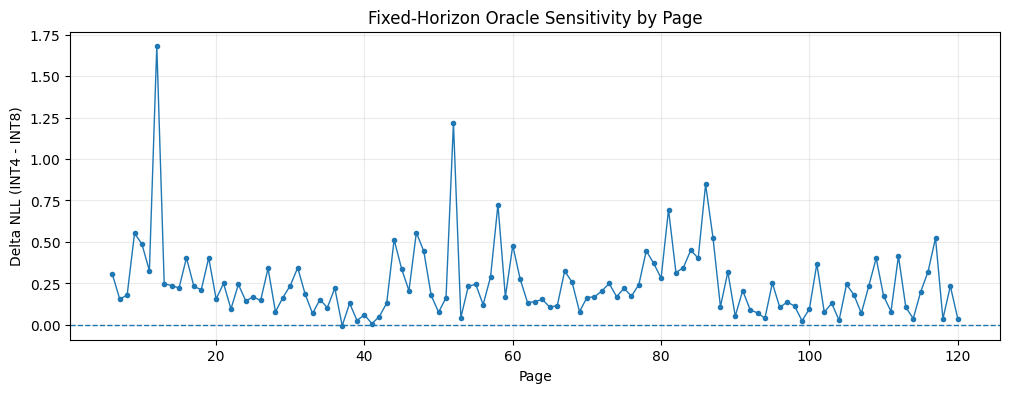

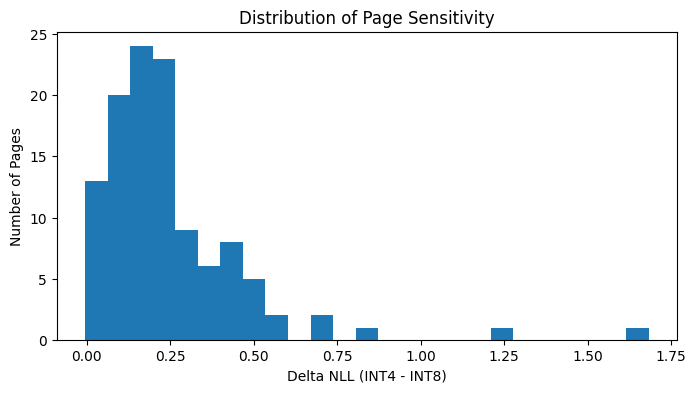


Cell 4 complete.
Primary predictor metric: Spearman rank correlation with oracle Delta_NLL.
Policy-oriented metrics: Top-K overlap for FP16 candidates and Bottom-K overlap for INT4 candidates.


In [5]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 4: Oracle diagnostics and evaluation metrics
# ============================================================

import matplotlib.pyplot as plt
from scipy.stats import spearmanr


# ------------------------------------------------------------
# Build canonical oracle table
# ------------------------------------------------------------

oracle_analysis_df = page_sensitivity_df.copy()

# Rank 1 = most sensitive / most important
oracle_analysis_df["Oracle_Rank"] = (
    oracle_analysis_df[ORACLE_TARGET]
    .rank(method="first", ascending=False)
    .astype(int)
)

# Normalized sensitivity percentile:
# 1.0 = among the most sensitive pages
# 0.0 = among the least sensitive pages
oracle_analysis_df["Oracle_Percentile"] = (
    oracle_analysis_df[ORACLE_TARGET]
    .rank(method="average", pct=True)
)


# ------------------------------------------------------------
# Check consistency with saved ranked oracle file
# ------------------------------------------------------------

if {
    "Page",
    "Delta_NLL"
}.issubset(ranked_oracle_df.columns):

    saved_ranked = (
        ranked_oracle_df[["Page", "Delta_NLL"]]
        .sort_values("Delta_NLL", ascending=False)
        .reset_index(drop=True)
    )

    derived_ranked = (
        oracle_analysis_df[["Page", "Delta_NLL"]]
        .sort_values("Delta_NLL", ascending=False)
        .reset_index(drop=True)
    )

    assert np.array_equal(
        saved_ranked["Page"].to_numpy(),
        derived_ranked["Page"].to_numpy()
    )

    assert np.allclose(
        saved_ranked["Delta_NLL"].to_numpy(),
        derived_ranked["Delta_NLL"].to_numpy(),
        atol=1e-10,
    )

    print("Saved ranked oracle matches derived ranking: YES")

else:
    print(
        "Saved ranked file has a different schema; "
        "canonical ranking derived from full_page_sensitivity_map.csv."
    )


# ------------------------------------------------------------
# Distribution statistics
# ------------------------------------------------------------

sens = oracle_analysis_df[ORACLE_TARGET]

print("\nOracle sensitivity distribution")
print("--------------------------------")
print(f"Pages:                    {len(sens)}")
print(f"Minimum:                  {sens.min():.6f}")
print(f"25th percentile:          {sens.quantile(0.25):.6f}")
print(f"Median:                   {sens.median():.6f}")
print(f"Mean:                     {sens.mean():.6f}")
print(f"75th percentile:          {sens.quantile(0.75):.6f}")
print(f"90th percentile:          {sens.quantile(0.90):.6f}")
print(f"Maximum:                  {sens.max():.6f}")
print(f"Std. deviation:           {sens.std():.6f}")

num_negative = int((sens < 0).sum())
num_positive = int((sens > 0).sum())

print(f"\nNegative Delta NLL pages: {num_negative}")
print(f"Positive Delta NLL pages: {num_positive}")


# ------------------------------------------------------------
# Ranking evaluation helpers
# ------------------------------------------------------------

def spearman_with_oracle(scores, oracle=oracle_analysis_df):
    """
    Higher predictor score must mean 'more important / sensitive'.
    Returns Spearman rank correlation with oracle Delta_NLL.
    """
    scores = np.asarray(scores, dtype=float)

    if len(scores) != len(oracle):
        raise ValueError(
            f"Expected {len(oracle)} scores, got {len(scores)}."
        )

    rho, p_value = spearmanr(
        scores,
        oracle[ORACLE_TARGET].to_numpy()
    )

    return float(rho), float(p_value)


def top_k_overlap(scores, k, oracle=oracle_analysis_df):
    """
    Fraction of true top-k sensitive pages recovered
    by the predictor's top-k pages.
    """
    scores = np.asarray(scores, dtype=float)

    if not (1 <= k <= len(oracle)):
        raise ValueError("Invalid k.")

    pages = oracle["Page"].to_numpy()
    oracle_scores = oracle[ORACLE_TARGET].to_numpy()

    true_idx = np.argsort(-oracle_scores)[:k]
    pred_idx = np.argsort(-scores)[:k]

    true_pages = set(pages[true_idx])
    pred_pages = set(pages[pred_idx])

    overlap = len(true_pages & pred_pages)

    return overlap / k


def bottom_k_overlap(scores, k, oracle=oracle_analysis_df):
    """
    Fraction of true bottom-k low-sensitivity pages recovered
    by the predictor's bottom-k pages.

    Especially relevant for choosing pages to demote to INT4.
    """
    scores = np.asarray(scores, dtype=float)

    if not (1 <= k <= len(oracle)):
        raise ValueError("Invalid k.")

    pages = oracle["Page"].to_numpy()
    oracle_scores = oracle[ORACLE_TARGET].to_numpy()

    true_idx = np.argsort(oracle_scores)[:k]
    pred_idx = np.argsort(scores)[:k]

    true_pages = set(pages[true_idx])
    pred_pages = set(pages[pred_idx])

    overlap = len(true_pages & pred_pages)

    return overlap / k


# ------------------------------------------------------------
# Show most/least sensitive pages
# ------------------------------------------------------------

print("\n10 most sensitive pages")
print("-----------------------")

display(
    oracle_analysis_df[
        ["Page", "Start_Token", "End_Token",
         "Delta_NLL", "Oracle_Rank"]
    ]
    .sort_values("Delta_NLL", ascending=False)
    .head(10)
    .reset_index(drop=True)
)


print("\n10 least sensitive pages")
print("------------------------")

display(
    oracle_analysis_df[
        ["Page", "Start_Token", "End_Token",
         "Delta_NLL", "Oracle_Rank"]
    ]
    .sort_values("Delta_NLL", ascending=True)
    .head(10)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Plot 1: sensitivity by page
# ------------------------------------------------------------

plt.figure(figsize=(12, 4))

plt.plot(
    oracle_analysis_df["Page"],
    oracle_analysis_df["Delta_NLL"],
    marker=".",
    linewidth=1
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Page")
plt.ylabel("Delta NLL (INT4 - INT8)")
plt.title("Fixed-Horizon Oracle Sensitivity by Page")
plt.grid(alpha=0.25)

plt.show()


# ------------------------------------------------------------
# Plot 2: sensitivity distribution
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))

plt.hist(
    oracle_analysis_df["Delta_NLL"],
    bins=25
)

plt.xlabel("Delta NLL (INT4 - INT8)")
plt.ylabel("Number of Pages")
plt.title("Distribution of Page Sensitivity")

plt.show()


print("\nCell 4 complete.")
print(
    "Primary predictor metric: Spearman rank correlation "
    "with oracle Delta_NLL."
)
print(
    "Policy-oriented metrics: Top-K overlap for FP16 candidates "
    "and Bottom-K overlap for INT4 candidates."
)

### Cell 4 — Oracle Sensitivity Analysis and Evaluation Metrics

Notebook 5 already measured the sensitivity of every candidate KV-cache page using the fixed-horizon oracle:

\[
S(p) = \Delta NLL
     = NLL_{\text{INT4},p} - NLL_{\text{INT8},p}
\]

A large positive \(\Delta NLL\) means that converting the page from INT8 to INT4 causes a large degradation in model quality. Therefore, the page is considered **highly sensitive / important**.

A small \(\Delta NLL\) means that the page can tolerate INT4 relatively well and is therefore a better candidate for low-precision storage.

Cell 4 does not modify the KV cache or implement a new policy. Its purpose is to characterize this oracle and define the metrics that will later be used to evaluate inference-time importance predictors.

#### Oracle distribution

The sensitivity map contains 115 candidate pages, covering pages 6–120.

The measured distribution is:

- Minimum \(\Delta NLL\): **-0.004689**
- 25th percentile: **0.111870**
- Median: **0.199217**
- Mean: **0.248416**
- 75th percentile: **0.320646**
- 90th percentile: **0.467215**
- Maximum: **1.682524**
- Standard deviation: **0.228007**

Only one page has a slightly negative \(\Delta NLL\), while the other 114 pages have positive sensitivity.

The distribution is strongly right-skewed: most pages have relatively low or moderate sensitivity, while a small number of pages are much more sensitive to INT4 quantization.

For example:

- Page 12: \(\Delta NLL = 1.682524\) — extremely sensitive
- Page 52: \(\Delta NLL = 1.217712\)
- Page 86: \(\Delta NLL = 0.847106\)

In contrast:

- Page 37: \(\Delta NLL = -0.004689\)
- Page 41: \(\Delta NLL = 0.007296\)
- Page 99: \(\Delta NLL = 0.024747\)

This confirms that page identity matters significantly and that different pages tolerate aggressive quantization very differently.

#### Why ranking metrics are needed

Notebook 6 will attempt to estimate page importance using information that is available during inference, such as:

- attention
- recency
- model confidence
- combinations of these signals

The true future \(\Delta NLL\) cannot be computed during real inference, because it requires evaluating future ground-truth tokens twice. Therefore, it serves only as an **oracle target** for evaluating the inference-time predictors.

Three main evaluation metrics are prepared:

**Spearman rank correlation**

Spearman correlation measures how similar the ordering produced by a predictor is to the oracle ordering.

\[
\rho = 1
\]

means a perfect ranking match,

\[
\rho \approx 0
\]

means little or no ranking relationship, and

\[
\rho = -1
\]

means the ranking is reversed.

This is useful because the final policy mainly needs to distinguish more-sensitive pages from less-sensitive pages rather than reproduce the exact numerical \(\Delta NLL\).

**Top-K overlap**

Top-K overlap measures how many of the oracle's most sensitive pages are also identified as highly important by the predictor.

This is useful for evaluating whether the predictor can identify pages that may benefit from being promoted to **FP16**.

**Bottom-K overlap**

Bottom-K overlap measures how many of the oracle's least-sensitive pages are also classified as low importance by the predictor.

This is useful for evaluating whether the predictor can safely identify pages that are good candidates for **INT4**.

Top-K and Bottom-K are useful diagnostic metrics, but they do not imply that the final policy must always assign a fixed number of pages to each precision tier.

#### Planned final precision policy

The intended architecture remains:

\[
\text{high importance} \rightarrow FP16
\]

\[
\text{medium/default importance} \rightarrow INT8
\]

\[
\text{low importance} \rightarrow INT4
\]

However, rather than defining the tiers using a fixed number of pages, the final policy should preferably use **importance/sensitivity thresholds**.

Conceptually:

\[
\hat{S}(p) > T_{\text{high}}
\Rightarrow FP16
\]

\[
T_{\text{low}} \leq \hat{S}(p) \leq T_{\text{high}}
\Rightarrow INT8
\]

\[
\hat{S}(p) < T_{\text{low}}
\Rightarrow INT4
\]

where \(\hat{S}(p)\) is the sensitivity predicted from inference-time signals.

The true oracle \(\Delta NLL\) will only be used during development and evaluation. At deployment time, the precision decision must depend only on signals available during inference.

The values of \(T_{\text{low}}\) and \(T_{\text{high}}\) should not be chosen arbitrarily. They will later be tuned experimentally by measuring the resulting memory–quality tradeoff and selecting thresholds that produce a good Pareto operating point.

#5: Page-Level Attention Helper Functions

In [6]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 5: Page-Level Attention Helper Functions
# ============================================================

import torch
import numpy as np
import math


# ------------------------------------------------------------
# Helper 1:
# Convert token-level attention mass into page-level mass
# ------------------------------------------------------------

def token_mass_to_page_mass(token_mass, page_size=PAGE_SIZE):
    """
    Convert attention mass over individual key tokens into
    attention mass over logical KV-cache pages.

    Parameters
    ----------
    token_mass : 1D torch.Tensor
        Attention mass for each key token.
        Shape: [K]

    page_size : int
        Number of tokens per logical KV-cache page.

    Returns
    -------
    page_mass : 1D torch.Tensor
        Attention mass for each logical page.
        Shape: [num_pages]
    """

    if token_mass.ndim != 1:
        raise ValueError(
            f"Expected 1D token_mass, got shape {token_mass.shape}"
        )

    key_len = token_mass.shape[0]

    num_pages = math.ceil(key_len / page_size)

    page_mass = []

    for page in range(num_pages):

        start = page * page_size
        end = min(
            (page + 1) * page_size,
            key_len
        )

        page_mass.append(
            token_mass[start:end].sum()
        )

    return torch.stack(page_mass)


# ------------------------------------------------------------
# Helper 2:
# Aggregate Hugging Face attention tensors into pages
# ------------------------------------------------------------

def summarize_attention_to_pages(
    attentions,
    page_size=PAGE_SIZE
):
    """
    Aggregate transformer attention weights into logical pages.

    Hugging Face returns one attention tensor per layer:

        [batch, query_heads, query_tokens, key_tokens]

    For Qwen2.5-1.5B:

        [1, 12, Q, K]

    We calculate two page-level views:

    1. Mean-query page attention
       Average attention over all query tokens in the current
       16-token page.

    2. Last-query page attention
       Attention produced by only the final token of the page.

    Both are averaged across attention heads and layers.
    """

    if attentions is None:
        raise ValueError("attentions is None")

    layer_page_mean = []
    layer_page_last = []

    for layer_attn in attentions:

        if layer_attn is None:
            raise ValueError(
                "One of the attention layers is None."
            )

        # Expected:
        # [B, H, Q, K]
        if layer_attn.ndim != 4:
            raise ValueError(
                f"Expected attention shape [B,H,Q,K], "
                f"got {layer_attn.shape}"
            )

        # Convert calculations to float32 for stable statistics.
        a = layer_attn.detach().float()


        # ----------------------------------------------------
        # Mean over:
        #   batch
        #   heads
        #   all query tokens
        #
        # Result:
        #   attention mass per KEY TOKEN
        # ----------------------------------------------------

        token_mass_mean = a.mean(
            dim=(0, 1, 2)
        )

        page_mass_mean = token_mass_to_page_mass(
            token_mass_mean,
            page_size
        )

        layer_page_mean.append(
            page_mass_mean
        )


        # ----------------------------------------------------
        # Attention from LAST QUERY TOKEN only
        #
        # This token is especially interesting because it is
        # the closest available observation to the point where
        # the page has just completed.
        # ----------------------------------------------------

        token_mass_last = a[
            :, :, -1, :
        ].mean(
            dim=(0, 1)
        )

        page_mass_last = token_mass_to_page_mass(
            token_mass_last,
            page_size
        )

        layer_page_last.append(
            page_mass_last
        )


    # [layers, pages]
    layer_page_mean = torch.stack(
        layer_page_mean
    )

    layer_page_last = torch.stack(
        layer_page_last
    )


    # Average across transformer layers
    page_mass_mean = (
        layer_page_mean.mean(dim=0)
    )

    page_mass_last = (
        layer_page_last.mean(dim=0)
    )


    return {
        "layer_page_mean": layer_page_mean,
        "layer_page_last": layer_page_last,

        "page_mass_mean": page_mass_mean,
        "page_mass_last": page_mass_last,
    }


# ------------------------------------------------------------
# Helper 3:
# Page-level entropy
# ------------------------------------------------------------

def normalized_page_entropy(page_mass):
    """
    Measure how spread-out the attention is over pages.

    0   -> attention concentrated on very few pages
    1   -> attention approximately uniform over all pages
    """

    p = page_mass.detach().float()

    total = p.sum()

    if total <= 0:
        return 0.0

    p = p / total

    p = p[p > 0]

    entropy = -(p * torch.log(p)).sum()

    max_entropy = math.log(
        len(page_mass)
    )

    if max_entropy == 0:
        return 0.0

    return float(
        entropy / max_entropy
    )


# ------------------------------------------------------------
# Helper 4:
# Extract predictor features for the page that has just
# completed.
# ------------------------------------------------------------

def extract_current_page_attention_features(
    page_idx,
    attention_summary
):
    """
    Produce inference-time attention features for page_idx.

    IMPORTANT:
    These features use only attention available when the
    current page has just completed.

    No future tokens are used.
    """

    mean_mass = (
        attention_summary["page_mass_mean"]
        .detach()
        .cpu()
    )

    last_mass = (
        attention_summary["page_mass_last"]
        .detach()
        .cpu()
    )

    layer_mean = (
        attention_summary["layer_page_mean"]
        .detach()
        .cpu()
    )

    if page_idx >= len(mean_mass):
        raise ValueError(
            f"page_idx={page_idx} but only "
            f"{len(mean_mass)} pages exist."
        )


    # Current page
    self_mean = float(
        mean_mass[page_idx]
    )

    self_last = float(
        last_mass[page_idx]
    )


    # Previous page
    if page_idx > 0:

        prev_mean = float(
            mean_mass[page_idx - 1]
        )

        prev_last = float(
            last_mass[page_idx - 1]
        )

    else:

        prev_mean = 0.0
        prev_last = 0.0


    # Layer-to-layer behavior of attention
    # received by the current page
    self_by_layer = (
        layer_mean[:, page_idx]
    )

    self_layer_std = float(
        self_by_layer.std()
    )

    self_layer_max = float(
        self_by_layer.max()
    )


    # Relative importance compared with the previous page
    eps = 1e-12

    self_prev_ratio = (
        self_mean /
        (prev_mean + eps)
    )


    # Rank of current page according to attention from the
    # current query page.
    #
    # Rank 1 = currently most-attended page.
    descending_order = torch.argsort(
        mean_mass,
        descending=True
    )

    self_attention_rank = int(
        (
            descending_order == page_idx
        ).nonzero(
            as_tuple=True
        )[0].item()
        + 1
    )


    features = {

        "Page": int(page_idx),

        # Attention received by this page
        "Attn_Self_Mean": self_mean,
        "Attn_Self_Last": self_last,

        # Neighbor comparison
        "Attn_Previous_Mean": prev_mean,
        "Attn_Previous_Last": prev_last,
        "Attn_SelfPrev_Ratio": self_prev_ratio,

        # Layer variability
        "Attn_Self_LayerStd": self_layer_std,
        "Attn_Self_LayerMax": self_layer_max,

        # Relative attention rank
        "Attn_Self_Rank": self_attention_rank,

        # Overall concentration of current attention
        "Attn_PageEntropy_Mean":
            normalized_page_entropy(
                mean_mass
            ),

        "Attn_PageEntropy_Last":
            normalized_page_entropy(
                last_mass
            ),
    }

    return features


# ------------------------------------------------------------
# Simple synthetic sanity test
# ------------------------------------------------------------

# 32 key tokens = 2 pages.
#
# Uniform token attention should give:
#
# page 0 -> 0.5
# page 1 -> 0.5

toy_token_mass = torch.ones(32) / 32

toy_page_mass = token_mass_to_page_mass(
    toy_token_mass,
    page_size=16
)

assert torch.allclose(
    toy_page_mass,
    torch.tensor([0.5, 0.5])
)

print("Attention helper sanity test: PASSED")
print(
    "Toy page masses:",
    toy_page_mass.tolist()
)

print("\nCell 5 complete.")
print(
    "Ready to collect page-level attention "
    "signals without future-token leakage."
)

Attention helper sanity test: PASSED
Toy page masses: [0.5, 0.5]

Cell 5 complete.
Ready to collect page-level attention signals without future-token leakage.


#6: Collect causal page-level attention signals

In [7]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 6: Collect Causal Page-Level Attention Signals
# ============================================================

import time
import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

# Row q, column p:
# attention from query page q -> key/cache page p
#
# Only p <= q exists causally.
# Future entries remain NaN.
page_attention_mean_matrix = np.full(
    (NUM_PAGES, NUM_PAGES),
    np.nan,
    dtype=np.float32,
)

page_attention_last_matrix = np.full(
    (NUM_PAGES, NUM_PAGES),
    np.nan,
    dtype=np.float32,
)

feature_rows = []


# ------------------------------------------------------------
# Sequential cache-aware inference
# ------------------------------------------------------------

past_key_values = None

start_time = time.time()

print("Collecting page-level attention...")
print("----------------------------------")


with torch.inference_mode():

    for page_idx in range(NUM_PAGES):

        start_token = page_idx * PAGE_SIZE
        end_token = (page_idx + 1) * PAGE_SIZE

        input_chunk = cache_input_ids[
            :,
            start_token:end_token
        ]


        # ----------------------------------------------------
        # Process one 16-token page while reusing previous KV
        # ----------------------------------------------------

        outputs = model(
            input_ids=input_chunk,
            past_key_values=past_key_values,
            use_cache=True,
            output_attentions=True,
            return_dict=True,
        )

        attentions = outputs.attentions

        if attentions is None:
            raise RuntimeError(
                "Model returned no attention tensors. "
                "Check that attn_implementation='eager'."
            )


        # ----------------------------------------------------
        # Basic attention-shape checks
        # ----------------------------------------------------

        first_layer_attn = attentions[0]

        # Expected:
        # [batch=1, heads=12, query_tokens=16, key_tokens=end_token]
        assert first_layer_attn.shape[0] == 1
        assert first_layer_attn.shape[1] == num_attention_heads
        assert first_layer_attn.shape[2] == PAGE_SIZE
        assert first_layer_attn.shape[3] == end_token


        # ----------------------------------------------------
        # Convert token attention -> logical page attention
        # ----------------------------------------------------

        attention_summary = summarize_attention_to_pages(
            attentions,
            page_size=PAGE_SIZE,
        )

        page_mass_mean = (
            attention_summary["page_mass_mean"]
            .detach()
            .cpu()
            .numpy()
        )

        page_mass_last = (
            attention_summary["page_mass_last"]
            .detach()
            .cpu()
            .numpy()
        )


        expected_visible_pages = page_idx + 1

        assert len(page_mass_mean) == expected_visible_pages
        assert len(page_mass_last) == expected_visible_pages


        # ----------------------------------------------------
        # Save complete causal attention trajectory
        #
        # q = current query page
        # p = cache/key page receiving attention
        # ----------------------------------------------------

        page_attention_mean_matrix[
            page_idx,
            :expected_visible_pages
        ] = page_mass_mean

        page_attention_last_matrix[
            page_idx,
            :expected_visible_pages
        ] = page_mass_last


        # ----------------------------------------------------
        # Immediate predictor features for candidate pages
        #
        # IMPORTANT:
        # These are extracted exactly when page_idx finishes.
        # Nothing from query pages > page_idx is used.
        # ----------------------------------------------------

        if page_idx in CANDIDATE_PAGES:

            features = extract_current_page_attention_features(
                page_idx,
                attention_summary,
            )

            features["Start_Token"] = start_token
            features["End_Token"] = end_token - 1

            # Decision occurs immediately after this page
            # has completed.
            features["Decision_After_Token"] = end_token - 1

            features["Visible_Pages"] = expected_visible_pages

            feature_rows.append(features)


        # ----------------------------------------------------
        # Keep the updated KV cache for the next page
        # ----------------------------------------------------

        past_key_values = outputs.past_key_values


        # ----------------------------------------------------
        # Free large attention tensors immediately
        # ----------------------------------------------------

        del outputs
        del attentions
        del attention_summary
        del first_layer_attn

        if torch.cuda.is_available() and (
            (page_idx + 1) % 16 == 0
        ):
            torch.cuda.empty_cache()


        # ----------------------------------------------------
        # Progress
        # ----------------------------------------------------

        if (
            page_idx == 0
            or (page_idx + 1) % 16 == 0
            or page_idx == NUM_PAGES - 1
        ):

            elapsed = time.time() - start_time

            print(
                f"Processed page {page_idx:3d} / "
                f"{NUM_PAGES - 1} "
                f"| cached tokens = {end_token:4d} "
                f"| elapsed = {elapsed:.1f}s"
            )


# ------------------------------------------------------------
# Convert immediate features to DataFrame
# ------------------------------------------------------------

attention_features_df = pd.DataFrame(feature_rows)

attention_features_df = (
    attention_features_df
    .sort_values("Page")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Causality checks
# ------------------------------------------------------------

upper_triangle_mask = np.triu(
    np.ones(
        (NUM_PAGES, NUM_PAGES),
        dtype=bool
    ),
    k=1,
)

# No query page can attend to a page that does not exist yet.
assert np.isnan(
    page_attention_mean_matrix[
        upper_triangle_mask
    ]
).all()

assert np.isnan(
    page_attention_last_matrix[
        upper_triangle_mask
    ]
).all()


# Every causal entry should exist.
lower_triangle_mask = np.tril(
    np.ones(
        (NUM_PAGES, NUM_PAGES),
        dtype=bool
    )
)

assert np.isfinite(
    page_attention_mean_matrix[
        lower_triangle_mask
    ]
).all()

assert np.isfinite(
    page_attention_last_matrix[
        lower_triangle_mask
    ]
).all()


# Candidate-page alignment
assert len(attention_features_df) == 115

assert np.array_equal(
    attention_features_df["Page"].to_numpy(),
    np.array(CANDIDATE_PAGES)
)


# ------------------------------------------------------------
# Attention-mass sanity checks
# ------------------------------------------------------------

# For each query page, total page-level attention should be
# approximately 1 after averaging across heads/layers/queries.
#
# Note: tiny floating-point deviations are expected.

mean_row_sums = np.nansum(
    page_attention_mean_matrix,
    axis=1
)

last_row_sums = np.nansum(
    page_attention_last_matrix,
    axis=1
)


print("\nAttention collection complete")
print("-----------------------------")

print(
    f"Candidate feature rows:      "
    f"{len(attention_features_df)}"
)

print(
    f"Mean-attention matrix shape: "
    f"{page_attention_mean_matrix.shape}"
)

print(
    f"Last-attention matrix shape: "
    f"{page_attention_last_matrix.shape}"
)

print(
    f"Mean row-sum range:          "
    f"{mean_row_sums.min():.6f} - "
    f"{mean_row_sums.max():.6f}"
)

print(
    f"Last row-sum range:          "
    f"{last_row_sums.min():.6f} - "
    f"{last_row_sums.max():.6f}"
)

print(
    f"Total runtime:               "
    f"{time.time() - start_time:.1f}s"
)


# ------------------------------------------------------------
# Preview
# ------------------------------------------------------------

display(
    attention_features_df.head(10)
)


print("\nCell 6 complete.")
print(
    "Causal attention trajectories and immediate "
    "page-level predictor features are ready."
)

----------------------------------
Processed page   0 / 127 | cached tokens =   16 | elapsed = 1.0s
Processed page  15 / 127 | cached tokens =  256 | elapsed = 1.7s
Processed page  31 / 127 | cached tokens =  512 | elapsed = 2.6s
Processed page  47 / 127 | cached tokens =  768 | elapsed = 3.7s
Processed page  63 / 127 | cached tokens = 1024 | elapsed = 5.1s
Processed page  79 / 127 | cached tokens = 1280 | elapsed = 6.6s
Processed page  95 / 127 | cached tokens = 1536 | elapsed = 8.9s
Processed page 111 / 127 | cached tokens = 1792 | elapsed = 11.1s
Processed page 127 / 127 | cached tokens = 2048 | elapsed = 13.2s


AssertionError: 

### Cell 6 — Collecting Causal Page-Level Attention Signals

This cell performs the first real inference-time experiment in Notebook 6.

The model processes the 2048-token sequence sequentially in logical pages of 16 tokens while using the KV cache:

\[
\text{Page }0 \rightarrow \text{Page }1 \rightarrow \cdots \rightarrow \text{Page }127
\]

At every step, the model receives only the current 16-token page and reuses the cached Keys and Values from all previously processed pages.

For every query page \(q\), the model returns attention weights over all KV-cache tokens that currently exist. These token-level attention weights are converted into page-level attention masses.

Two page-level attention matrices are recorded:

- **Mean-attention matrix** — attention averaged over all 16 query tokens, all attention heads, and all transformer layers.
- **Last-token attention matrix** — attention produced by the final query token of the current page, averaged over heads and layers.

Conceptually, each matrix stores:

\[
A[q,p]
\]

where \(A[q,p]\) is the attention given by query page \(q\) to cached page \(p\).

Because inference is causal, page \(q\) can only attend to pages that already exist:

\[
p \le q
\]

Therefore the attention matrix is lower triangular. Entries corresponding to future pages (\(p>q\)) are intentionally left undefined (`NaN`).

For example:

| Query page | Pages that can receive attention |
|---|---|
| 0 | 0 |
| 1 | 0, 1 |
| 2 | 0, 1, 2 |
| 52 | 0, 1, ..., 52 |
| 127 | 0, 1, ..., 127 |

The cell also extracts a compact set of inference-time features for each of the 115 candidate pages (pages 6–120), including:

- attention received by the current page,
- attention from the last token,
- attention received by the previous page,
- current-page / previous-page attention ratio,
- variation of attention across transformer layers,
- current attention rank,
- page-level attention entropy.

These features are measured **immediately when each page finishes**. No later query page is used when constructing the immediate predictor features.

This restriction is important because Notebook 5's oracle sensitivity uses future model behavior:

\[
S(p)=NLL_{\text{INT4},p}-NLL_{\text{INT8},p}
\]

but a deployable policy cannot observe that future information.

Therefore:

\[
\boxed{\text{Notebook 5 future } \Delta NLL = \text{evaluation target only}}
\]

while

\[
\boxed{\text{Notebook 6 causal signals = information available to the real policy}}
\]

The complete causal attention matrices are also retained. This allows later experiments with dynamic policies where a page can initially remain at INT8 and be demoted only after observing how subsequent tokens use it.

The goal of this cell is therefore not yet to determine FP16, INT8, or INT4 precision. Its purpose is to collect the causal attention information from which page-importance predictors can later be constructed.

In [8]:
# ============================================================
# Notebook 06 — Cell 6A
# Diagnose non-finite attention entries
# ============================================================

bad_mean_mask = (
    lower_triangle_mask
    & ~np.isfinite(page_attention_mean_matrix)
)

bad_last_mask = (
    lower_triangle_mask
    & ~np.isfinite(page_attention_last_matrix)
)

bad_mean_locations = np.argwhere(bad_mean_mask)
bad_last_locations = np.argwhere(bad_last_mask)


print("Non-finite attention diagnostic")
print("--------------------------------")

print(
    f"Bad mean-attention entries: "
    f"{len(bad_mean_locations)}"
)

print(
    f"Bad last-attention entries: "
    f"{len(bad_last_locations)}"
)


if len(bad_mean_locations) > 0:
    print("\nFirst bad MEAN entries:")

    for q, p in bad_mean_locations[:20]:

        print(
            f"query page {q:3d} -> key page {p:3d}: "
            f"{page_attention_mean_matrix[q, p]}"
        )


if len(bad_last_locations) > 0:
    print("\nFirst bad LAST entries:")

    for q, p in bad_last_locations[:20]:

        print(
            f"query page {q:3d} -> key page {p:3d}: "
            f"{page_attention_last_matrix[q, p]}"
        )


# ------------------------------------------------------------
# Which query pages are affected?
# ------------------------------------------------------------

bad_mean_query_pages = np.unique(
    bad_mean_locations[:, 0]
) if len(bad_mean_locations) else np.array([], dtype=int)

bad_last_query_pages = np.unique(
    bad_last_locations[:, 0]
) if len(bad_last_locations) else np.array([], dtype=int)


print("\nAffected query pages")
print("--------------------")

print(
    "Mean attention:",
    bad_mean_query_pages.tolist()
)

print(
    "Last attention:",
    bad_last_query_pages.tolist()
)


# ------------------------------------------------------------
# Check candidate feature table too
# ------------------------------------------------------------

numeric_feature_cols = (
    attention_features_df
    .select_dtypes(include=[np.number])
    .columns
)

feature_values = attention_features_df[
    numeric_feature_cols
].to_numpy()

bad_feature_mask = ~np.isfinite(feature_values)

print("\nFeature-table diagnostic")
print("------------------------")

print(
    f"Non-finite feature values: "
    f"{bad_feature_mask.sum()}"
)

if bad_feature_mask.any():

    bad_rows, bad_cols = np.where(
        bad_feature_mask
    )

    for r, c in list(
        zip(bad_rows, bad_cols)
    )[:20]:

        column = numeric_feature_cols[c]

        print(
            f"Page "
            f"{attention_features_df.loc[r, 'Page']} "
            f"| {column} = "
            f"{attention_features_df.loc[r, column]}"
        )


# ------------------------------------------------------------
# Row sums, ignoring the problematic entries for diagnosis only
# ------------------------------------------------------------

mean_row_sums_debug = np.nansum(
    page_attention_mean_matrix,
    axis=1
)

last_row_sums_debug = np.nansum(
    page_attention_last_matrix,
    axis=1
)

print("\nRow-sum diagnostic")
print("------------------")

print(
    f"Mean-attention row-sum range: "
    f"{mean_row_sums_debug.min():.6f} - "
    f"{mean_row_sums_debug.max():.6f}"
)

print(
    f"Last-attention row-sum range: "
    f"{last_row_sums_debug.min():.6f} - "
    f"{last_row_sums_debug.max():.6f}"
)

Non-finite attention diagnostic
--------------------------------
Bad mean-attention entries: 8256
Bad last-attention entries: 8256

First bad MEAN entries:
query page   0 -> key page   0: nan
query page   1 -> key page   0: nan
query page   1 -> key page   1: nan
query page   2 -> key page   0: nan
query page   2 -> key page   1: nan
query page   2 -> key page   2: nan
query page   3 -> key page   0: nan
query page   3 -> key page   1: nan
query page   3 -> key page   2: nan
query page   3 -> key page   3: nan
query page   4 -> key page   0: nan
query page   4 -> key page   1: nan
query page   4 -> key page   2: nan
query page   4 -> key page   3: nan
query page   4 -> key page   4: nan
query page   5 -> key page   0: nan
query page   5 -> key page   1: nan
query page   5 -> key page   2: nan
query page   5 -> key page   3: nan
query page   5 -> key page   4: nan

First bad LAST entries:
query page   0 -> key page   0: nan
query page   1 -> key page   0: nan
query page   1 -> key page 

In [9]:
# ============================================================
# Notebook 06 — Cell 6B
# Diagnose FP16 eager-attention NaNs and test FP32 fix
# ============================================================

import gc
import transformers
import torch
import numpy as np


print("Environment")
print("-----------")
print(f"Transformers version: {transformers.__version__}")
print(f"Current model dtype:  {next(model.parameters()).dtype}")


# ------------------------------------------------------------
# Part 1 — Fresh first-page test with CURRENT FP16 model
# ------------------------------------------------------------

test_chunk = cache_input_ids[:, :PAGE_SIZE]

with torch.inference_mode():

    fp16_test = model(
        input_ids=test_chunk,
        past_key_values=None,
        use_cache=True,
        output_attentions=True,
        return_dict=True,
    )


print("\nFP16 eager-attention diagnostic")
print("--------------------------------")

fp16_bad_layers = []

for layer_idx, a in enumerate(fp16_test.attentions):

    total = a.numel()

    finite = torch.isfinite(a).sum().item()

    finite_fraction = finite / total

    if finite_fraction < 1.0:
        fp16_bad_layers.append(layer_idx)

    print(
        f"Layer {layer_idx:2d}: "
        f"finite = {finite_fraction:.6f}"
    )


fp16_logits_finite = bool(
    torch.isfinite(fp16_test.logits).all()
)

print()
print(f"FP16 logits fully finite: {fp16_logits_finite}")
print(f"FP16 bad attention layers: {fp16_bad_layers}")


# ------------------------------------------------------------
# Remove temporary outputs and old Cell-6 KV cache
# ------------------------------------------------------------

del fp16_test

if "past_key_values" in globals():
    del past_key_values

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# Part 2 — Convert model to FP32
#
# We use FP32 ONLY for attention-signal extraction.
# Actual mixed-precision KV experiments later remain based
# on the FP16 model / INT8 / INT4 architecture.
# ------------------------------------------------------------

print("\nConverting attention-analysis model to FP32...")

model = model.float()
model.eval()

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(
    f"New model dtype:      "
    f"{next(model.parameters()).dtype}"
)


# ------------------------------------------------------------
# Fresh first-page FP32 test
# ------------------------------------------------------------

with torch.inference_mode():

    fp32_test = model(
        input_ids=test_chunk,
        past_key_values=None,
        use_cache=True,
        output_attentions=True,
        return_dict=True,
    )


print("\nFP32 eager-attention diagnostic")
print("--------------------------------")

fp32_bad_layers = []

for layer_idx, a in enumerate(fp32_test.attentions):

    finite_fraction = (
        torch.isfinite(a).sum().item()
        / a.numel()
    )

    if finite_fraction < 1.0:
        fp32_bad_layers.append(layer_idx)

    print(
        f"Layer {layer_idx:2d}: "
        f"finite = {finite_fraction:.6f}"
    )


fp32_logits_finite = bool(
    torch.isfinite(fp32_test.logits).all()
)

all_fp32_attn_finite = all(
    torch.isfinite(a).all().item()
    for a in fp32_test.attentions
)


print()
print(
    f"FP32 attention fully finite: "
    f"{all_fp32_attn_finite}"
)

print(
    f"FP32 logits fully finite:    "
    f"{fp32_logits_finite}"
)

print(
    f"FP32 bad attention layers:   "
    f"{fp32_bad_layers}"
)


# ------------------------------------------------------------
# Strong validation
# ------------------------------------------------------------

assert all_fp32_attn_finite, (
    "FP32 attention still contains non-finite values."
)

assert fp32_logits_finite, (
    "FP32 logits still contain non-finite values."
)


# Check that attention probabilities sum to ~1
# across key positions.
first_layer = fp32_test.attentions[0].float()

attention_row_sums = first_layer.sum(dim=-1)

print(
    "\nFirst-layer attention row-sum range: "
    f"{attention_row_sums.min().item():.6f} - "
    f"{attention_row_sums.max().item():.6f}"
)


del fp32_test

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


print("\nCell 6B complete.")
print(
    "FP32 eager attention is ready for stable "
    "attention-signal extraction."
)

Environment
-----------
Transformers version: 5.16.1
Current model dtype:  torch.float16

FP16 eager-attention diagnostic
--------------------------------
Layer  0: finite = 0.953125
Layer  1: finite = 0.000000
Layer  2: finite = 0.000000
Layer  3: finite = 0.000000
Layer  4: finite = 0.000000
Layer  5: finite = 0.000000
Layer  6: finite = 0.000000
Layer  7: finite = 0.000000
Layer  8: finite = 0.000000
Layer  9: finite = 0.000000
Layer 10: finite = 0.000000
Layer 11: finite = 0.000000
Layer 12: finite = 0.000000
Layer 13: finite = 0.000000
Layer 14: finite = 0.000000
Layer 15: finite = 0.000000
Layer 16: finite = 0.000000
Layer 17: finite = 0.000000
Layer 18: finite = 0.000000
Layer 19: finite = 0.000000
Layer 20: finite = 0.000000
Layer 21: finite = 0.000000
Layer 22: finite = 0.000000
Layer 23: finite = 0.000000
Layer 24: finite = 0.000000
Layer 25: finite = 0.000000
Layer 26: finite = 0.000000
Layer 27: finite = 0.000000

FP16 logits fully finite: False
FP16 bad attention layers: [

In [10]:
# ============================================================
# Notebook 06 — Cell 6C
# Stable FP32 Causal Page-Level Attention Collection
# ============================================================

import time
import gc
import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Confirm stable analysis configuration
# ------------------------------------------------------------

assert next(model.parameters()).dtype == torch.float32

print("Stable attention collection configuration")
print("-----------------------------------------")
print(f"Model dtype:        {next(model.parameters()).dtype}")
print(f"Attention mode:     eager")
print(f"Pages:              {NUM_PAGES}")
print(f"Page size:          {PAGE_SIZE}")
print(f"Candidate pages:    {len(CANDIDATE_PAGES)}")


# ------------------------------------------------------------
# Reset ALL corrupted Cell-6 results
# ------------------------------------------------------------

page_attention_mean_matrix = np.full(
    (NUM_PAGES, NUM_PAGES),
    np.nan,
    dtype=np.float32,
)

page_attention_last_matrix = np.full(
    (NUM_PAGES, NUM_PAGES),
    np.nan,
    dtype=np.float32,
)

feature_rows = []

past_key_values = None


gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# Sequential cache-aware inference
# ------------------------------------------------------------

start_time = time.time()

print("\nCollecting stable page-level attention...")
print("-----------------------------------------")


with torch.inference_mode():

    for page_idx in range(NUM_PAGES):

        start_token = page_idx * PAGE_SIZE
        end_token = (page_idx + 1) * PAGE_SIZE

        input_chunk = cache_input_ids[
            :,
            start_token:end_token
        ]


        # ----------------------------------------------------
        # Process current 16-token page using existing KV cache
        # ----------------------------------------------------

        outputs = model(
            input_ids=input_chunk,
            past_key_values=past_key_values,
            use_cache=True,
            output_attentions=True,
            return_dict=True,
        )

        attentions = outputs.attentions


        if attentions is None:
            raise RuntimeError(
                f"No attention tensors returned at page {page_idx}."
            )


        # ----------------------------------------------------
        # Attention shape validation
        # ----------------------------------------------------

        first_layer_attn = attentions[0]

        assert first_layer_attn.shape == (
            1,
            num_attention_heads,
            PAGE_SIZE,
            end_token,
        )


        # ----------------------------------------------------
        # IMPORTANT:
        # Fail immediately if any layer becomes non-finite.
        # ----------------------------------------------------

        bad_layers = [
            layer_idx
            for layer_idx, a in enumerate(attentions)
            if not torch.isfinite(a).all()
        ]

        if bad_layers:
            raise RuntimeError(
                f"Non-finite attention at page {page_idx}; "
                f"bad layers = {bad_layers}"
            )


        if not torch.isfinite(outputs.logits).all():
            raise RuntimeError(
                f"Non-finite logits at page {page_idx}."
            )


        # ----------------------------------------------------
        # Convert token attention -> page attention
        # ----------------------------------------------------

        attention_summary = summarize_attention_to_pages(
            attentions,
            page_size=PAGE_SIZE,
        )


        page_mass_mean = (
            attention_summary["page_mass_mean"]
            .detach()
            .cpu()
            .numpy()
        )

        page_mass_last = (
            attention_summary["page_mass_last"]
            .detach()
            .cpu()
            .numpy()
        )


        visible_pages = page_idx + 1

        assert len(page_mass_mean) == visible_pages
        assert len(page_mass_last) == visible_pages

        assert np.isfinite(page_mass_mean).all()
        assert np.isfinite(page_mass_last).all()


        # ----------------------------------------------------
        # Page-level attention should sum approximately to 1
        # ----------------------------------------------------

        assert np.isclose(
            page_mass_mean.sum(),
            1.0,
            atol=1e-5,
        )

        assert np.isclose(
            page_mass_last.sum(),
            1.0,
            atol=1e-5,
        )


        # ----------------------------------------------------
        # Save causal attention matrices
        # ----------------------------------------------------

        page_attention_mean_matrix[
            page_idx,
            :visible_pages
        ] = page_mass_mean

        page_attention_last_matrix[
            page_idx,
            :visible_pages
        ] = page_mass_last


        # ----------------------------------------------------
        # Extract immediate features for candidate pages only
        # ----------------------------------------------------

        if page_idx in CANDIDATE_PAGES:

            features = extract_current_page_attention_features(
                page_idx,
                attention_summary,
            )

            features["Start_Token"] = start_token
            features["End_Token"] = end_token - 1

            features["Decision_After_Token"] = (
                end_token - 1
            )

            features["Visible_Pages"] = (
                visible_pages
            )

            feature_rows.append(features)


        # ----------------------------------------------------
        # Preserve KV cache for next page
        # ----------------------------------------------------

        past_key_values = outputs.past_key_values


        # ----------------------------------------------------
        # Free large temporary attention tensors
        # ----------------------------------------------------

        del outputs
        del attentions
        del attention_summary
        del first_layer_attn


        # ----------------------------------------------------
        # Progress
        # ----------------------------------------------------

        if (
            page_idx == 0
            or (page_idx + 1) % 16 == 0
            or page_idx == NUM_PAGES - 1
        ):

            elapsed = time.time() - start_time

            print(
                f"Processed page {page_idx:3d} / "
                f"{NUM_PAGES - 1} "
                f"| cached tokens = {end_token:4d} "
                f"| elapsed = {elapsed:.1f}s"
            )


# ------------------------------------------------------------
# Build feature dataframe
# ------------------------------------------------------------

attention_features_df = pd.DataFrame(
    feature_rows
)

attention_features_df = (
    attention_features_df
    .sort_values("Page")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Final matrix validation
# ------------------------------------------------------------

upper_triangle_mask = np.triu(
    np.ones(
        (NUM_PAGES, NUM_PAGES),
        dtype=bool
    ),
    k=1,
)

lower_triangle_mask = np.tril(
    np.ones(
        (NUM_PAGES, NUM_PAGES),
        dtype=bool
    )
)


# Future entries should still be NaN
assert np.isnan(
    page_attention_mean_matrix[
        upper_triangle_mask
    ]
).all()

assert np.isnan(
    page_attention_last_matrix[
        upper_triangle_mask
    ]
).all()


# Every causal entry must now be finite
assert np.isfinite(
    page_attention_mean_matrix[
        lower_triangle_mask
    ]
).all()

assert np.isfinite(
    page_attention_last_matrix[
        lower_triangle_mask
    ]
).all()


# ------------------------------------------------------------
# Feature-table validation
# ------------------------------------------------------------

assert len(attention_features_df) == 115

assert np.array_equal(
    attention_features_df["Page"].to_numpy(),
    np.array(CANDIDATE_PAGES)
)

numeric_cols = (
    attention_features_df
    .select_dtypes(include=[np.number])
    .columns
)

assert np.isfinite(
    attention_features_df[
        numeric_cols
    ].to_numpy()
).all()


# ------------------------------------------------------------
# Row-sum validation
# ------------------------------------------------------------

mean_row_sums = np.nansum(
    page_attention_mean_matrix,
    axis=1,
)

last_row_sums = np.nansum(
    page_attention_last_matrix,
    axis=1,
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

runtime = time.time() - start_time

print("\nStable attention collection complete")
print("------------------------------------")

print(
    f"Candidate feature rows:      "
    f"{len(attention_features_df)}"
)

print(
    f"Mean-attention matrix shape: "
    f"{page_attention_mean_matrix.shape}"
)

print(
    f"Last-attention matrix shape: "
    f"{page_attention_last_matrix.shape}"
)

print(
    f"Mean row-sum range:          "
    f"{mean_row_sums.min():.6f} - "
    f"{mean_row_sums.max():.6f}"
)

print(
    f"Last row-sum range:          "
    f"{last_row_sums.min():.6f} - "
    f"{last_row_sums.max():.6f}"
)

print(
    f"Total runtime:               "
    f"{runtime:.1f}s"
)


# ------------------------------------------------------------
# Preview candidate features
# ------------------------------------------------------------

display(
    attention_features_df.head(10)
)


print("\nCell 6C complete.")
print(
    "Stable causal attention signals are ready "
    "for analysis."
)

Stable attention collection configuration
-----------------------------------------
Model dtype:        torch.float32
Attention mode:     eager
Pages:              128
Page size:          16
Candidate pages:    115

-----------------------------------------
Processed page   0 / 127 | cached tokens =   16 | elapsed = 0.1s
Processed page  15 / 127 | cached tokens =  256 | elapsed = 0.9s
Processed page  31 / 127 | cached tokens =  512 | elapsed = 2.1s
Processed page  47 / 127 | cached tokens =  768 | elapsed = 3.4s
Processed page  63 / 127 | cached tokens = 1024 | elapsed = 5.3s
Processed page  79 / 127 | cached tokens = 1280 | elapsed = 7.4s
Processed page  95 / 127 | cached tokens = 1536 | elapsed = 9.3s
Processed page 111 / 127 | cached tokens = 1792 | elapsed = 11.5s
Processed page 127 / 127 | cached tokens = 2048 | elapsed = 14.0s

Stable attention collection complete
------------------------------------
Candidate feature rows:      115
Mean-attention matrix shape: (128, 128)
Last-at

,Page,Attn_Self_Mean,Attn_Self_Last,Attn_Previous_Mean,Attn_Previous_Last,Attn_SelfPrev_Ratio,Attn_Self_LayerStd,Attn_Self_LayerMax,Attn_Self_Rank,Attn_PageEntropy_Mean,Attn_PageEntropy_Last,Start_Token,End_Token,Decision_After_Token,Visible_Pages
0,6,0.239007,0.413851,0.082686,0.033544,2.890534,0.124363,0.676966,2,0.788827,0.658103,96,111,111,7
1,7,0.287866,0.370211,0.110528,0.073631,2.604466,0.132968,0.720336,2,0.729927,0.735689,112,127,127,8
2,8,0.262926,0.315531,0.077195,0.055004,3.405990,0.132547,0.688881,2,0.740443,0.743895,128,143,143,9
3,9,0.251731,0.382686,0.097683,0.096679,2.577011,0.122040,0.672693,2,0.735213,0.728608,144,159,159,10
4,10,0.279134,0.449277,0.123645,0.048710,2.257538,0.130796,0.721825,2,0.675672,0.563435,160,175,175,11
5,11,0.255860,0.370518,0.066617,0.040958,3.840749,0.132786,0.689015,2,0.700146,0.660053,176,191,191,12
6,12,0.235517,0.298885,0.130030,0.097061,1.811249,0.144613,0.689303,2,0.604265,0.584748,192,207,207,13
7,13,0.269229,0.288521,0.024275,0.058098,11.090614,0.134063,0.647179,2,0.689924,0.610783,208,223,223,14
8,14,0.252608,0.313229,0.128180,0.075435,1.970724,0.129387,0.681094,2,0.695533,0.647063,224,239,239,15
9,15,0.233780,0.301902,0.140093,0.090075,1.668744,0.113915,0.641008,2,0.708448,0.707488,240,255,255,16



Cell 6C complete.
Stable causal attention signals are ready for analysis.


### Cell 6 — Causal Attention Collection and Numerical-Stability Fix

The goal of Cell 6 is to collect **inference-time attention signals for every KV-cache page**.

The 2048-token sequence is processed sequentially using the existing logical page size:

\[
\text{PAGE\_SIZE}=16
\]

so the sequence contains:

\[
\frac{2048}{16}=128
\]

logical pages.

The model processes the sequence as:

\[
P_0 \rightarrow P_1 \rightarrow P_2 \rightarrow \cdots \rightarrow P_{127}
\]

using `use_cache=True`, so when page \(q\) is processed, the KV cache already contains all previous pages.

---

#### Causal page-level attention

For each query page \(q\), the model returns token-level attention weights over the KV-cache tokens that currently exist.

These attention weights are converted into page-level attention:

\[
A[q,p]
\]

where:

- \(q\) = the current query page
- \(p\) = a page stored in the KV cache
- \(A[q,p]\) = the amount of attention query page \(q\) gives to page \(p\)

Because transformer inference is causal:

\[
p \le q
\]

Only the current and previous pages can receive attention.

Therefore the page-attention matrix is lower triangular:

\[
\begin{array}{c|ccccc}
 & P_0 & P_1 & P_2 & P_3 & \cdots \\
\hline
Q_0 & A_{00} & - & - & - & \cdots\\
Q_1 & A_{10} & A_{11} & - & - & \cdots\\
Q_2 & A_{20} & A_{21} & A_{22} & - & \cdots\\
Q_3 & A_{30} & A_{31} & A_{32} & A_{33} & \cdots
\end{array}
\]

Entries above the diagonal correspond to future pages and are intentionally stored as `NaN`.

Two versions of this matrix are collected:

1. **Mean attention**

   Attention is averaged over:

   - all 16 query tokens in the current page,
   - all 12 attention heads,
   - all 28 transformer layers.

2. **Last-token attention**

   Only the final token of the current page is used as the query, after which attention is averaged over heads and layers.

The last-token signal may be useful because it represents the model state at the exact moment when the current page has just completed.

---

### Initial FP16 problem

The first attempt used the normal model precision:

\[
\text{FP16}
\]

with:

```python
attn_implementation="eager"
output_attentions=True

Features collected for each candidate page

For every candidate page \(p\), the following inference-time features are stored:

Attn_Self_Mean
Average attention received by the current page.
Attn_Self_Last
Attention received by the current page from the final token.
Attn_Previous_Mean
Average attention received by the previous page.
Attn_Previous_Last
Last-token attention received by the previous page.
Attn_SelfPrev_Ratio
Ratio between current-page and previous-page attention.
Attn_Self_LayerStd
Variation in current-page attention across transformer layers.
Attn_Self_LayerMax
Maximum layer-level attention received by the page.
Attn_Self_Rank
Rank of the current page among all currently visible pages according to attention.
Attn_PageEntropy_Mean
How concentrated or distributed the mean attention is across pages.
Attn_PageEntropy_Last
The same concentration measure using only the last query token.
No future-information leakage

The feature vector for page \(p\) is created immediately when page \(p\) finishes.

#7: Merge attention features with the oracle and test each signal individually

Do any of the causal attention signals collected in Cell 6 actually relate to the true page sensitivity measured in Notebook 5?

-We want to find a good attention signal from the ones we calculated in cell 6 (prev cell).
We're only studying signal quality here.

Attention/oracle merge
----------------------
Merged pages:          115
Page range:            6-120
Page/token alignment:  PASSED

Feature variability
-------------------


,Feature,Min,Max,Mean,Std,Unique_Values
0,Attn_SelfPrev_Ratio,0.920809,18.238183,2.912972,2.066430,115
1,Attn_Self_Rank_Reversed,-3.000000,-1.000000,-2.000000,0.131876,3
2,Attn_PageEntropy_Last,0.286224,0.743895,0.532399,0.113628,115
3,Attn_PageEntropy_Mean,0.366825,0.788827,0.579450,0.102448,115
4,Attn_Self_Last,0.192498,0.449277,0.323854,0.058998,115
5,Attn_Previous_Mean,0.014414,0.226052,0.102979,0.032681,115
6,Attn_Previous_Last,0.004054,0.172391,0.054066,0.032507,115
7,Attn_Self_Mean,0.193150,0.345391,0.252953,0.030058,115
8,Attn_Self_LayerMax,0.555754,0.721825,0.656683,0.028148,115
9,Attn_Self_LayerStd,0.098580,0.144613,0.124665,0.007885,115



Attention signal vs oracle sensitivity
--------------------------------------


,Feature,Spearman_Rho,Abs_Rho,P_Value
0,Attn_Self_LayerMax,0.153271,0.153271,0.101972
1,Attn_Self_Rank_Reversed,0.152945,0.152945,0.102710
2,Attn_Self_LayerStd,0.129567,0.129567,0.167557
3,Attn_Self_Last,0.127421,0.127421,0.174767
4,Attn_SelfPrev_Ratio,0.074978,0.074978,0.425805
5,Attn_PageEntropy_Mean,0.073566,0.073566,0.434598
6,Attn_Self_Mean,0.072067,0.072067,0.444044
7,Attn_Previous_Last,-0.068524,0.068524,0.466820
8,Attn_Previous_Mean,-0.032841,0.032841,0.727516
9,Attn_PageEntropy_Last,0.028533,0.028533,0.762117



Strongest individual attention signal: Attn_Self_LayerMax
Spearman rho:                       0.1533


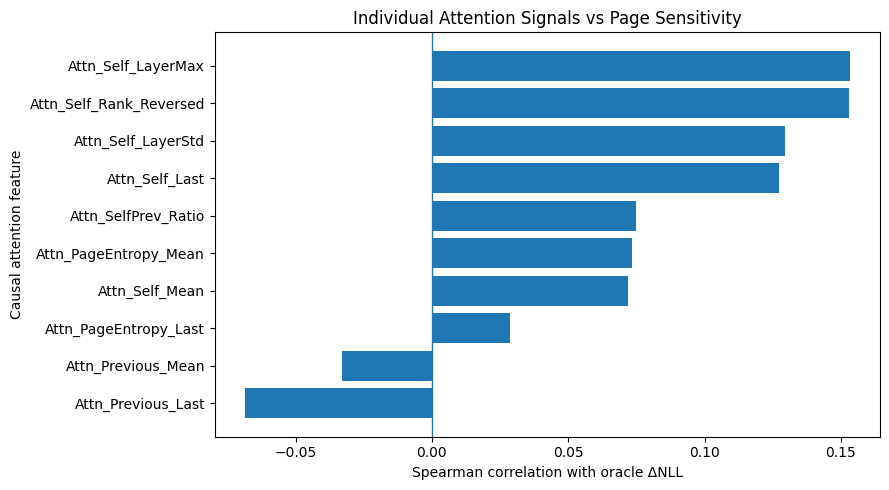

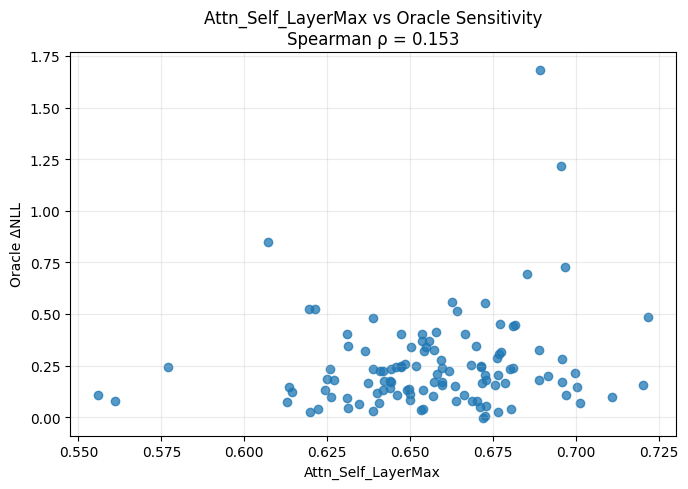


Most sensitive oracle pages
---------------------------


,Page,Delta_NLL,Oracle_Rank,Best_Attention_Score
0,12,1.682524,1,0.689303
1,52,1.217712,2,0.695604
2,86,0.847106,3,0.607028
3,58,0.725152,4,0.696764
4,81,0.695237,5,0.685272
5,47,0.556649,6,0.662706
6,9,0.553010,7,0.672693
7,87,0.524720,8,0.619425
8,117,0.524231,9,0.621456
9,44,0.513706,10,0.664318



Least sensitive oracle pages
----------------------------


,Page,Delta_NLL,Oracle_Rank,Best_Attention_Score
0,37,-0.004689,115,0.672096
1,41,0.007296,114,0.672780
2,99,0.024747,113,0.676501
3,39,0.026757,112,0.619971
4,104,0.028315,111,0.638747
5,118,0.036819,110,0.653317
6,120,0.037850,109,0.680570
7,114,0.038565,108,0.622217
8,94,0.040540,107,0.653912
9,53,0.044093,106,0.631351



Cell 7 complete.
Individual causal attention signals have now been evaluated against the fixed-horizon sensitivity oracle.


In [11]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 7: Merge Attention Features with Oracle and
#         Evaluate Individual Attention Signals
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


# ------------------------------------------------------------
# 1. Merge causal attention features with Notebook 05 oracle
# ------------------------------------------------------------

analysis_df = attention_features_df.merge(
    oracle_analysis_df[
        [
            "Page",
            "Start_Token",
            "End_Token",
            "Delta_NLL",
            "Oracle_Rank",
            "Oracle_Percentile",
        ]
    ],
    on=["Page", "Start_Token", "End_Token"],
    how="inner",
    validate="one_to_one",
)


# ------------------------------------------------------------
# Alignment validation
# ------------------------------------------------------------

assert len(analysis_df) == len(CANDIDATE_PAGES) == 115

assert np.array_equal(
    analysis_df["Page"].to_numpy(),
    np.array(CANDIDATE_PAGES)
)

assert analysis_df["Delta_NLL"].notna().all()

print("Attention/oracle merge")
print("----------------------")
print(f"Merged pages:          {len(analysis_df)}")
print(
    f"Page range:            "
    f"{analysis_df['Page'].min()}-"
    f"{analysis_df['Page'].max()}"
)
print("Page/token alignment:  PASSED")


# ------------------------------------------------------------
# 2. Define attention predictors
#
# Convention:
# HIGH score = predicted HIGH sensitivity / importance
# ------------------------------------------------------------

predictor_scores = {

    # More attention to current page -> potentially more important
    "Attn_Self_Mean":
        analysis_df["Attn_Self_Mean"].to_numpy(),

    "Attn_Self_Last":
        analysis_df["Attn_Self_Last"].to_numpy(),

    # Previous-page usage may carry useful local context
    "Attn_Previous_Mean":
        analysis_df["Attn_Previous_Mean"].to_numpy(),

    "Attn_Previous_Last":
        analysis_df["Attn_Previous_Last"].to_numpy(),

    # Current / previous relative attention
    "Attn_SelfPrev_Ratio":
        analysis_df["Attn_SelfPrev_Ratio"].to_numpy(),

    # Layer-wise behavior
    "Attn_Self_LayerStd":
        analysis_df["Attn_Self_LayerStd"].to_numpy(),

    "Attn_Self_LayerMax":
        analysis_df["Attn_Self_LayerMax"].to_numpy(),

    # Rank 1 means HIGH attention, so reverse sign.
    "Attn_Self_Rank_Reversed":
        -analysis_df["Attn_Self_Rank"].to_numpy(),

    # Attention concentration / dispersion
    "Attn_PageEntropy_Mean":
        analysis_df["Attn_PageEntropy_Mean"].to_numpy(),

    "Attn_PageEntropy_Last":
        analysis_df["Attn_PageEntropy_Last"].to_numpy(),
}


oracle_values = analysis_df["Delta_NLL"].to_numpy()


# ------------------------------------------------------------
# 3. Feature variability
#
# A nearly constant feature cannot be useful for ranking.
# ------------------------------------------------------------

feature_diagnostics = []

for name, scores in predictor_scores.items():

    scores = np.asarray(scores, dtype=float)

    feature_diagnostics.append({
        "Feature": name,
        "Min": scores.min(),
        "Max": scores.max(),
        "Mean": scores.mean(),
        "Std": scores.std(),
        "Unique_Values": len(np.unique(scores)),
    })


feature_diagnostics_df = pd.DataFrame(
    feature_diagnostics
)


print("\nFeature variability")
print("-------------------")

display(
    feature_diagnostics_df.sort_values(
        "Std",
        ascending=False
    ).reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Spearman correlation with oracle Delta NLL
# ------------------------------------------------------------

correlation_rows = []

for name, scores in predictor_scores.items():

    scores = np.asarray(scores, dtype=float)

    # Constant features cannot have a meaningful correlation.
    if np.allclose(scores, scores[0]):

        rho = np.nan
        p_value = np.nan

    else:

        rho, p_value = spearmanr(
            scores,
            oracle_values
        )


    correlation_rows.append({
        "Feature": name,
        "Spearman_Rho": rho,
        "Abs_Rho": (
            abs(rho)
            if np.isfinite(rho)
            else np.nan
        ),
        "P_Value": p_value,
    })


attention_correlation_df = pd.DataFrame(
    correlation_rows
)

attention_correlation_df = (
    attention_correlation_df
    .sort_values(
        "Abs_Rho",
        ascending=False,
        na_position="last"
    )
    .reset_index(drop=True)
)


print("\nAttention signal vs oracle sensitivity")
print("--------------------------------------")

display(attention_correlation_df)


# ------------------------------------------------------------
# 5. Identify strongest usable attention signals
# ------------------------------------------------------------

valid_corr = attention_correlation_df.dropna(
    subset=["Spearman_Rho"]
)

best_feature = valid_corr.iloc[0]["Feature"]
best_rho = valid_corr.iloc[0]["Spearman_Rho"]


print(
    f"\nStrongest individual attention signal: "
    f"{best_feature}"
)

print(
    f"Spearman rho:                       "
    f"{best_rho:.4f}"
)


# ------------------------------------------------------------
# 6. Plot all correlations
# ------------------------------------------------------------

plot_corr = valid_corr.sort_values(
    "Spearman_Rho"
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_corr["Feature"],
    plot_corr["Spearman_Rho"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Spearman correlation with oracle ΔNLL")
plt.ylabel("Causal attention feature")
plt.title(
    "Individual Attention Signals vs Page Sensitivity"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Scatter plot for strongest signal
# ------------------------------------------------------------

best_scores = np.asarray(
    predictor_scores[best_feature],
    dtype=float
)

plt.figure(figsize=(7, 5))

plt.scatter(
    best_scores,
    oracle_values,
    alpha=0.75
)

plt.xlabel(best_feature)
plt.ylabel("Oracle ΔNLL")
plt.title(
    f"{best_feature} vs Oracle Sensitivity\n"
    f"Spearman ρ = {best_rho:.3f}"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Show pages at sensitivity extremes with their
#    strongest attention score
# ------------------------------------------------------------

extreme_view = analysis_df[
    [
        "Page",
        "Delta_NLL",
        "Oracle_Rank",
    ]
].copy()

extreme_view["Best_Attention_Score"] = best_scores


print("\nMost sensitive oracle pages")
print("---------------------------")

display(
    extreme_view
    .sort_values(
        "Delta_NLL",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)


print("\nLeast sensitive oracle pages")
print("----------------------------")

display(
    extreme_view
    .sort_values(
        "Delta_NLL",
        ascending=True
    )
    .head(10)
    .reset_index(drop=True)
)


print("\nCell 7 complete.")
print(
    "Individual causal attention signals have now been "
    "evaluated against the fixed-horizon sensitivity oracle."
)

### Cell 7 — Do Immediate Attention Signals Predict Page Sensitivity?

Cell 7 compares the causal attention features collected in Cell 6 against the fixed-horizon page-sensitivity oracle from Notebook 5.

The oracle target is:

\[
S(p)=\Delta NLL
=
NLL_{\text{INT4},p}
-
NLL_{\text{INT8},p}
\]

where a larger \(\Delta NLL\) means that page \(p\) is more sensitive to INT4 quantization.

The goal of this experiment is to determine whether attention information available **when a page has just completed** can predict this future sensitivity.

The 115 candidate pages from the attention experiment were first merged with the 115 oracle measurements.

The alignment check passed:

\[
\text{Pages}=6,\ldots,120
\]

with the correct token ranges for every page.

---

#### Individual attention features

Each attention feature was compared with the oracle using Spearman rank correlation.

Spearman correlation measures whether pages ranked highly by an inference-time signal also tend to be ranked highly by the sensitivity oracle.

A value near:

\[
\rho=1
\]

would indicate a strong useful ranking relationship, while:

\[
\rho\approx0
\]

means that the predictor ordering has little relationship with the oracle ordering.

The strongest individual attention feature was:

\[
\text{Attn\_Self\_LayerMax}
\]

with:

\[
\rho=0.1533
\]

and:

\[
p=0.102
\]

This is only a weak positive relationship.

The other strongest signals were also weak:

\[
\rho_{\text{SelfRank}}\approx0.153
\]

\[
\rho_{\text{LayerStd}}\approx0.130
\]

\[
\rho_{\text{SelfLast}}\approx0.127
\]

All remaining correlations had magnitude below approximately \(0.08\).

None of the tested attention features produced a conventional statistically significant result at:

\[
p<0.05
\]

on these 115 pages.

Therefore, the current experiment does not provide strong evidence that any **single immediate attention statistic** can predict page sensitivity well.

---

#### Feature variability does not imply predictive power

Some features varied substantially across pages but still had almost no relationship with the oracle.

For example:

\[
\text{Attn\_SelfPrev\_Ratio}
\]

ranged from approximately:

\[
0.92 \rightarrow 18.24
\]

but its Spearman correlation was only:

\[
\rho\approx0.075
\]

Therefore, large numerical variation in a feature does not necessarily mean that the feature captures quantization sensitivity.

The attention-rank feature showed the opposite problem.

`Attn_Self_Rank_Reversed` had only **3 unique values across all 115 pages**, meaning that the current page was almost always assigned approximately the same attention rank.

This makes the feature too coarse to provide a useful page-level ranking on its own.

---

#### Sensitive and insensitive pages are not cleanly separated

The strongest attention feature also fails to clearly separate the most-sensitive and least-sensitive pages.

For example, the most-sensitive page is:

\[
\text{Page 12}: \Delta NLL=1.682524
\]

with an `Attn_Self_LayerMax` value of approximately:

\[
0.689
\]

However, the least-sensitive page is:

\[
\text{Page 37}: \Delta NLL\approx-0.004689
\]

and still has a very similar attention value:

\[
0.672
\]

Furthermore, Page 86 is the third-most-sensitive page:

\[
\Delta NLL=0.847106
\]

but its attention score is only approximately:

\[
0.607
\]

which is lower than the attention scores of several very low-sensitivity pages.

The scatter plot therefore does not show a clear monotonic separation between attention and sensitivity.

---

### Interpretation

The result does **not** show that attention is generally useless for KV-cache management.

It shows something more specific:

\[
\boxed{
\text{Immediate page-completion attention alone is a weak predictor of future INT4 sensitivity}
}
\]

At the moment page \(p\) finishes, no future page has yet had the opportunity to attend to it.

Therefore, the attention features available at this point mainly describe how the tokens inside the current page interact with the existing context, rather than how useful this page will become to future tokens.

A future token may later repeatedly attend to a page that did not appear particularly important at the instant it was created.

This motivates two possible directions:

1. Combine attention with other causal signals such as model confidence.
2. Later investigate a delayed-demotion policy, where a page initially remains INT8 and is demoted only after observing how subsequent tokens use it.

The complete causal attention matrices from Cell 6 were preserved so that the second idea can be evaluated later without repeating attention extraction.

For now, the next experiment tests **model-confidence signals** that are also available during inference.

The current conclusion is therefore:

\[
\boxed{
\text{Attention alone is insufficient; additional signals are needed.}
}
\]

#8: Collect and evaluate causal model-confidence signals

Confidence-signal collection
----------------------------
Model dtype:       torch.float32
Pages:             128
Candidate pages:   115

---------------------------------------
Processed page   0 / 127 | elapsed = 0.3s
Processed page  15 / 127 | elapsed = 1.7s
Processed page  31 / 127 | elapsed = 3.1s
Processed page  47 / 127 | elapsed = 4.2s
Processed page  63 / 127 | elapsed = 5.3s
Processed page  79 / 127 | elapsed = 6.3s
Processed page  95 / 127 | elapsed = 7.3s
Processed page 111 / 127 | elapsed = 8.4s
Processed page 127 / 127 | elapsed = 9.5s

Confidence signal vs oracle sensitivity
---------------------------------------


,Feature,Spearman_Rho,Abs_Rho,P_Value
0,Conf_Entropy_Last,0.102225,0.102225,0.276985
1,Conf_LowTop1_Last,0.071719,0.071719,0.446248
2,Conf_Entropy_Mean,0.062053,0.062053,0.510016
3,Conf_LowMargin_Last,0.046169,0.046169,0.624162
4,Conf_LowTop1_Mean,0.042468,0.042468,0.652242
5,Conf_LowMargin_Mean,0.039699,0.039699,0.673583
6,Conf_Entropy_Max,0.024643,0.024643,0.793769



Strongest individual confidence signal: Conf_Entropy_Last
Spearman rho:                         0.1022

Best individual signals so far
------------------------------
Attention:  Attn_Self_LayerMax           rho = 0.1533
Confidence: Conf_Entropy_Last            rho = 0.1022


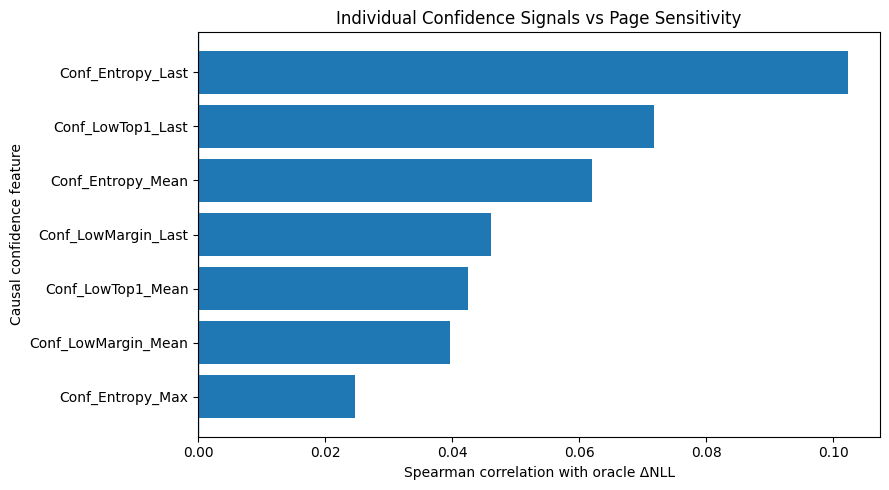

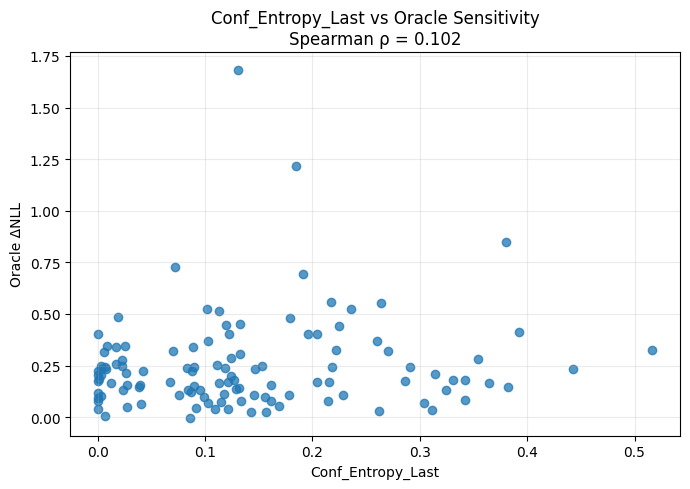


Confidence feature preview
--------------------------


,Page,Conf_Entropy_Mean,Conf_Entropy_Last,Conf_Entropy_Max,Conf_Top1_Mean,Conf_Top1_Last,Conf_Margin_Mean,Conf_Margin_Last,Start_Token,End_Token
0,6,0.165767,0.132370,0.584109,0.604314,0.695243,0.505464,0.606000,96,111
1,7,0.257865,0.161054,0.591259,0.491596,0.545067,0.412761,0.354029,112,127
2,8,0.225867,0.126843,0.498236,0.423206,0.696602,0.282346,0.547671,128,143
3,9,0.250534,0.263907,0.514125,0.464894,0.365380,0.360433,0.223655,144,159
4,10,0.174618,0.019226,0.519224,0.604509,0.967708,0.512256,0.954834,160,175
5,11,0.231193,0.516542,0.516542,0.458140,0.022251,0.357519,0.005408,176,191
6,12,0.328507,0.130458,0.539840,0.296610,0.752754,0.138808,0.710886,192,207
7,13,0.133067,0.002802,0.522503,0.622588,0.996243,0.510310,0.994588,208,223
8,14,0.223300,0.118643,0.542024,0.452258,0.598711,0.336701,0.454573,224,239
9,15,0.186937,0.087972,0.532778,0.561770,0.679928,0.453207,0.462635,240,255



Cell 8 complete.
Causal confidence signals have been evaluated against the sensitivity oracle.


In [12]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 8: Causal Model-Confidence Signals
# ============================================================

import time
import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


# ------------------------------------------------------------
# We keep FP32 for this analysis pass because the model is
# already in the numerically stable analysis configuration.
# ------------------------------------------------------------

assert next(model.parameters()).dtype == torch.float32

print("Confidence-signal collection")
print("----------------------------")
print(f"Model dtype:       {next(model.parameters()).dtype}")
print(f"Pages:             {NUM_PAGES}")
print(f"Candidate pages:   {len(CANDIDATE_PAGES)}")


# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

confidence_rows = []

past_key_values = None

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# Sequential cache-aware inference
# ------------------------------------------------------------

start_time = time.time()

print("\nCollecting causal confidence signals...")
print("---------------------------------------")


with torch.inference_mode():

    for page_idx in range(NUM_PAGES):

        start_token = page_idx * PAGE_SIZE
        end_token = (page_idx + 1) * PAGE_SIZE

        input_chunk = cache_input_ids[
            :,
            start_token:end_token
        ]


        outputs = model(
            input_ids=input_chunk,
            past_key_values=past_key_values,
            use_cache=True,
            output_attentions=False,
            return_dict=True,
        )


        logits = outputs.logits.float()

        if not torch.isfinite(logits).all():
            raise RuntimeError(
                f"Non-finite logits at page {page_idx}."
            )


        # ----------------------------------------------------
        # Convert logits to probabilities
        #
        # Shape:
        # [1, 16, vocabulary_size]
        # ----------------------------------------------------

        log_probs = torch.log_softmax(
            logits,
            dim=-1
        )

        probs = torch.exp(log_probs)


        # ----------------------------------------------------
        # Token-level entropy
        #
        # Higher entropy = more uncertainty
        # ----------------------------------------------------

        entropy = -(
            probs * log_probs
        ).sum(dim=-1)


        # Normalize by maximum possible entropy log(V)
        vocab_size = logits.shape[-1]

        normalized_entropy = (
            entropy / np.log(vocab_size)
        )


        # ----------------------------------------------------
        # Top-1 probability and top-1/top-2 margin
        #
        # Higher values = greater confidence
        # ----------------------------------------------------

        top2_probs = torch.topk(
            probs,
            k=2,
            dim=-1
        ).values

        top1_prob = top2_probs[..., 0]

        probability_margin = (
            top2_probs[..., 0]
            - top2_probs[..., 1]
        )


        # ----------------------------------------------------
        # Store candidate-page features
        # ----------------------------------------------------

        if page_idx in CANDIDATE_PAGES:

            confidence_rows.append({

                "Page": int(page_idx),

                # Entropy:
                # high = uncertain
                "Conf_Entropy_Mean":
                    float(
                        normalized_entropy.mean()
                    ),

                "Conf_Entropy_Last":
                    float(
                        normalized_entropy[:, -1].mean()
                    ),

                "Conf_Entropy_Max":
                    float(
                        normalized_entropy.max()
                    ),

                # Top-1 probability:
                # high = confident
                "Conf_Top1_Mean":
                    float(
                        top1_prob.mean()
                    ),

                "Conf_Top1_Last":
                    float(
                        top1_prob[:, -1].mean()
                    ),

                # Probability margin:
                # high = confident
                "Conf_Margin_Mean":
                    float(
                        probability_margin.mean()
                    ),

                "Conf_Margin_Last":
                    float(
                        probability_margin[:, -1].mean()
                    ),

                "Start_Token": start_token,
                "End_Token": end_token - 1,
            })


        past_key_values = outputs.past_key_values


        # ----------------------------------------------------
        # Free temporary tensors
        # ----------------------------------------------------

        del outputs
        del logits
        del log_probs
        del probs
        del entropy
        del normalized_entropy
        del top2_probs
        del top1_prob
        del probability_margin


        if (
            page_idx == 0
            or (page_idx + 1) % 16 == 0
            or page_idx == NUM_PAGES - 1
        ):

            elapsed = time.time() - start_time

            print(
                f"Processed page {page_idx:3d} / "
                f"{NUM_PAGES - 1} "
                f"| elapsed = {elapsed:.1f}s"
            )


# ------------------------------------------------------------
# Create confidence DataFrame
# ------------------------------------------------------------

confidence_features_df = pd.DataFrame(
    confidence_rows
)

confidence_features_df = (
    confidence_features_df
    .sort_values("Page")
    .reset_index(drop=True)
)


assert len(confidence_features_df) == 115

assert np.array_equal(
    confidence_features_df["Page"].to_numpy(),
    np.array(CANDIDATE_PAGES)
)


numeric_conf_cols = (
    confidence_features_df
    .select_dtypes(include=[np.number])
    .columns
)

assert np.isfinite(
    confidence_features_df[
        numeric_conf_cols
    ].to_numpy()
).all()


# ------------------------------------------------------------
# Merge with existing attention + oracle analysis table
# ------------------------------------------------------------

analysis_df = analysis_df.merge(
    confidence_features_df,
    on=[
        "Page",
        "Start_Token",
        "End_Token",
    ],
    how="inner",
    validate="one_to_one",
)


assert len(analysis_df) == 115


# ------------------------------------------------------------
# Convert confidence measurements into importance scores
#
# Convention:
#
# HIGH predictor score
#       =
# predicted HIGH sensitivity
#
# Our hypothesis:
# uncertainty may indicate greater sensitivity.
# ------------------------------------------------------------

confidence_predictors = {

    # Higher entropy -> more uncertain
    "Conf_Entropy_Mean":
        analysis_df[
            "Conf_Entropy_Mean"
        ].to_numpy(),

    "Conf_Entropy_Last":
        analysis_df[
            "Conf_Entropy_Last"
        ].to_numpy(),

    "Conf_Entropy_Max":
        analysis_df[
            "Conf_Entropy_Max"
        ].to_numpy(),

    # Lower top-1 probability -> more uncertain,
    # so reverse the sign.
    "Conf_LowTop1_Mean":
        -analysis_df[
            "Conf_Top1_Mean"
        ].to_numpy(),

    "Conf_LowTop1_Last":
        -analysis_df[
            "Conf_Top1_Last"
        ].to_numpy(),

    # Smaller top1-top2 margin -> more uncertain,
    # so reverse the sign.
    "Conf_LowMargin_Mean":
        -analysis_df[
            "Conf_Margin_Mean"
        ].to_numpy(),

    "Conf_LowMargin_Last":
        -analysis_df[
            "Conf_Margin_Last"
        ].to_numpy(),
}


oracle_values = (
    analysis_df["Delta_NLL"]
    .to_numpy()
)


# ------------------------------------------------------------
# Correlation with oracle sensitivity
# ------------------------------------------------------------

confidence_corr_rows = []


for name, scores in confidence_predictors.items():

    rho, p_value = spearmanr(
        scores,
        oracle_values
    )

    confidence_corr_rows.append({
        "Feature": name,
        "Spearman_Rho": float(rho),
        "Abs_Rho": abs(float(rho)),
        "P_Value": float(p_value),
    })


confidence_correlation_df = pd.DataFrame(
    confidence_corr_rows
)

confidence_correlation_df = (
    confidence_correlation_df
    .sort_values(
        "Abs_Rho",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nConfidence signal vs oracle sensitivity")
print("---------------------------------------")

display(confidence_correlation_df)


# ------------------------------------------------------------
# Best confidence signal
# ------------------------------------------------------------

best_conf_feature = (
    confidence_correlation_df
    .iloc[0]["Feature"]
)

best_conf_rho = (
    confidence_correlation_df
    .iloc[0]["Spearman_Rho"]
)


print(
    f"\nStrongest individual confidence signal: "
    f"{best_conf_feature}"
)

print(
    f"Spearman rho:                         "
    f"{best_conf_rho:.4f}"
)


# ------------------------------------------------------------
# Compare with best attention signal from Cell 7
# ------------------------------------------------------------

print("\nBest individual signals so far")
print("------------------------------")

print(
    f"Attention:  {best_feature:<28} "
    f"rho = {best_rho:.4f}"
)

print(
    f"Confidence: {best_conf_feature:<28} "
    f"rho = {best_conf_rho:.4f}"
)


# ------------------------------------------------------------
# Correlation plot
# ------------------------------------------------------------

plot_conf = (
    confidence_correlation_df
    .sort_values("Spearman_Rho")
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_conf["Feature"],
    plot_conf["Spearman_Rho"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel(
    "Spearman correlation with oracle ΔNLL"
)

plt.ylabel(
    "Causal confidence feature"
)

plt.title(
    "Individual Confidence Signals vs Page Sensitivity"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Scatter plot of strongest confidence signal
# ------------------------------------------------------------

best_conf_scores = np.asarray(
    confidence_predictors[
        best_conf_feature
    ],
    dtype=float
)

plt.figure(figsize=(7, 5))

plt.scatter(
    best_conf_scores,
    oracle_values,
    alpha=0.75
)

plt.xlabel(best_conf_feature)

plt.ylabel(
    "Oracle ΔNLL"
)

plt.title(
    f"{best_conf_feature} vs Oracle Sensitivity\n"
    f"Spearman ρ = {best_conf_rho:.3f}"
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Preview features
# ------------------------------------------------------------

print("\nConfidence feature preview")
print("--------------------------")

display(
    confidence_features_df.head(10)
)


print("\nCell 8 complete.")
print(
    "Causal confidence signals have been evaluated "
    "against the sensitivity oracle."
)

### Cell 8 — Do Model-Confidence Signals Predict Page Sensitivity?

Cell 8 evaluates whether the model's own confidence while processing a page can predict how sensitive that page will later be to INT4 quantization.

Unlike the Notebook 5 oracle, these confidence signals are available directly during inference and do not require future ground-truth tokens.

For each of the 115 candidate pages, several confidence measurements were extracted from the model's output probability distribution.

---

### Confidence measurements

For every token, the model produces a probability distribution over the vocabulary.

Three types of confidence information were considered.

#### 1. Entropy

Entropy measures how spread out the probability distribution is.

\[
H=-\sum_i p_i\log p_i
\]

Higher entropy means the model is less certain about the next token.

The entropy was normalized by the maximum possible entropy:

\[
H_{\text{norm}}
=
\frac{H}{\log |\mathcal V|}
\]

The following page-level versions were recorded:

- mean entropy across the 16 tokens,
- entropy of the final token,
- maximum entropy inside the page.

---

#### 2. Top-1 probability

Let:

\[
P_1
\]

be the probability assigned to the model's most likely next token.

A large \(P_1\) means high confidence.

Because the predictor convention is:

\[
\text{higher score}
\Rightarrow
\text{higher predicted sensitivity},
\]

the sign was reversed when evaluating this feature:

\[
-P_1.
\]

Thus lower model confidence corresponds to a larger predictor score.

---

#### 3. Top-1 / Top-2 probability margin

Let:

\[
P_1
\]

and

\[
P_2
\]

be the probabilities of the first- and second-most likely next tokens.

The confidence margin is:

\[
P_1-P_2.
\]

A large margin means that the model strongly prefers one token, while a small margin means that several alternatives are competitive.

Again, the sign was reversed for the sensitivity predictor:

\[
-(P_1-P_2).
\]

---

### Results

All confidence signals showed only weak correlation with the Notebook 5 sensitivity oracle.

The strongest feature was:

\[
\text{Conf\_Entropy\_Last}
\]

with:

\[
\rho=0.1022
\]

and:

\[
p=0.277.
\]

The remaining correlations were even smaller:

- `Conf_LowTop1_Last`: \(\rho \approx 0.072\)
- `Conf_Entropy_Mean`: \(\rho \approx 0.062\)
- `Conf_LowMargin_Last`: \(\rho \approx 0.046\)
- `Conf_LowTop1_Mean`: \(\rho \approx 0.042\)
- `Conf_LowMargin_Mean`: \(\rho \approx 0.040\)
- `Conf_Entropy_Max`: \(\rho \approx 0.025\)

None of these relationships is statistically significant on the current 115-page sample.

---

### Comparison with attention

The strongest individual signals obtained so far are:

\[
\text{Attention: }
\rho=0.1533
\]

for `Attn_Self_LayerMax`, and:

\[
\text{Confidence: }
\rho=0.1022
\]

for `Conf_Entropy_Last`.

Therefore:

\[
\boxed{
\text{Immediate attention performs slightly better than confidence}
}
\]

but neither is sufficiently predictive by itself.

---

### Interpretation

The original hypothesis was that uncertain model states might indicate that more contextual information is important and therefore that the corresponding KV pages may require higher precision.

The experiment provides only weak evidence for this hypothesis.

The scatter plot shows substantial overlap: pages with similar confidence values can have very different oracle sensitivities.

In particular, some extremely sensitive pages do not have exceptionally high entropy.

Therefore there is no simple confidence threshold such as:

\[
H > T
\Rightarrow FP16
\]

that would currently separate sensitive and insensitive pages reliably.

The result should therefore be interpreted as:

\[
\boxed{
\text{Immediate model confidence alone is a weak predictor of future INT4 sensitivity.}
}
\]

This does not mean confidence is useless.

Confidence may still contribute useful information when combined with:

- attention,
- page position / age,
- delayed attention usage,
- other page-level statistics.

A nonlinear hybrid model may also exploit interactions that do not appear in individual Spearman correlations.

Possible hybrid models to test later include:

- linear / regularized regression as a simple baseline,
- Random Forest or Extra Trees as bagging-style methods,
- Gradient Boosting as a boosting-style method.

However, the current dataset contains only 115 page examples from one sequence, so ensemble methods must be evaluated carefully using held-out data to avoid overfitting.

Before constructing the hybrid predictor, the remaining inexpensive baseline signals should first be measured.

#9: Page position / recency baseline

Page-position baseline vs oracle sensitivity
--------------------------------------------


,Feature,Spearman_Rho,Abs_Rho,P_Value
0,Later_Page,-0.140582,0.140582,0.133988
1,Older_Page,0.140582,0.140582,0.133988



Direct Page vs Delta NLL:
Spearman rho = -0.1406
p-value      = 0.133988

Best individual signals so far
------------------------------
Attention:   Attn_Self_LayerMax           rho = 0.1533
Confidence:  Conf_Entropy_Last            rho = 0.1022
Position:    Later_Page                   rho = -0.1406


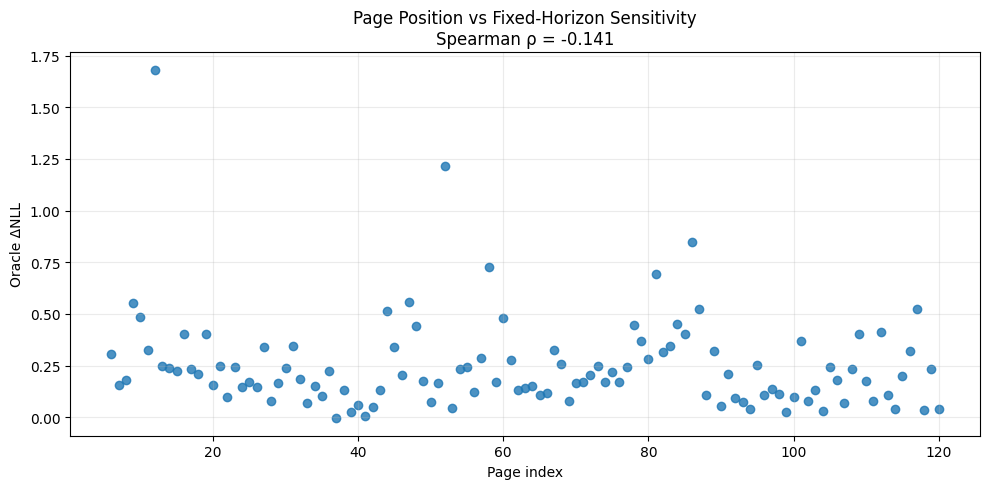


Sensitivity by sequence region
------------------------------


,Position_Quartile,Pages,Mean_Delta_NLL,Median_Delta_NLL,Max_Delta_NLL
0,Early,29,0.290895,0.232668,1.682524
1,Mid-Early,29,0.251149,0.169131,1.217712
2,Mid-Late,28,0.285953,0.246554,0.847106
3,Late,29,0.166962,0.114151,0.524231


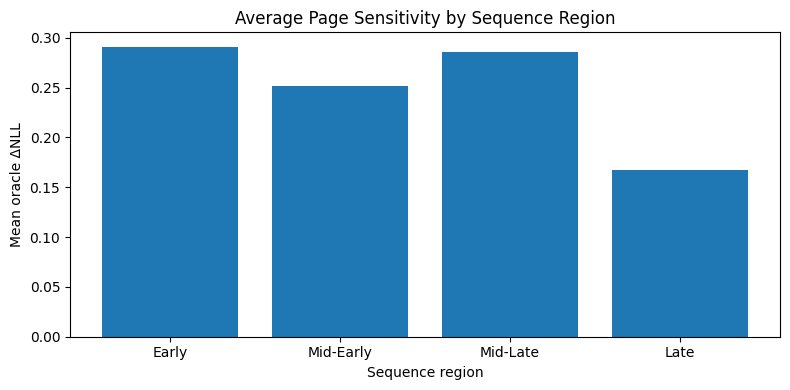


Cell 9 complete.
Simple page-position / age baselines have been evaluated against the fixed-horizon oracle.


In [13]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 9: Page Position / Recency Baselines
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


# ------------------------------------------------------------
# Build simple positional features
# ------------------------------------------------------------

analysis_df["Page_Index"] = (
    analysis_df["Page"].astype(float)
)

# Normalize position into approximately [0, 1]
analysis_df["Normalized_Position"] = (
    analysis_df["Page_Index"]
    / (NUM_PAGES - 1)
)

# If we look at the cache when all 128 pages exist,
# older pages have larger age.
analysis_df["Final_Page_Age"] = (
    (NUM_PAGES - 1)
    - analysis_df["Page_Index"]
)

analysis_df["Normalized_Final_Age"] = (
    analysis_df["Final_Page_Age"]
    / (NUM_PAGES - 1)
)


# ------------------------------------------------------------
# Predictor convention:
#
# Higher score = predicted MORE sensitive / important
#
# We test both possible positional directions rather than
# assuming in advance that old or recent pages are important.
# ------------------------------------------------------------

position_predictors = {

    # Later position = higher score
    "Later_Page":
        analysis_df[
            "Normalized_Position"
        ].to_numpy(),

    # Older page = higher score
    "Older_Page":
        analysis_df[
            "Normalized_Final_Age"
        ].to_numpy(),
}


oracle_values = (
    analysis_df["Delta_NLL"]
    .to_numpy()
)


# ------------------------------------------------------------
# Correlations
# ------------------------------------------------------------

position_rows = []

for name, scores in position_predictors.items():

    rho, p_value = spearmanr(
        scores,
        oracle_values
    )

    position_rows.append({
        "Feature": name,
        "Spearman_Rho": float(rho),
        "Abs_Rho": abs(float(rho)),
        "P_Value": float(p_value),
    })


position_correlation_df = pd.DataFrame(
    position_rows
).sort_values(
    "Abs_Rho",
    ascending=False
).reset_index(drop=True)


print("Page-position baseline vs oracle sensitivity")
print("--------------------------------------------")

display(position_correlation_df)


# ------------------------------------------------------------
# Direct page-number correlation
# ------------------------------------------------------------

page_rho, page_p = spearmanr(
    analysis_df["Page_Index"],
    oracle_values
)

print(
    f"\nDirect Page vs Delta NLL:"
    f"\nSpearman rho = {page_rho:.4f}"
    f"\np-value      = {page_p:.6f}"
)


# ------------------------------------------------------------
# Compare strongest single signals so far
# ------------------------------------------------------------

best_position_feature = (
    position_correlation_df.iloc[0]["Feature"]
)

best_position_rho = (
    position_correlation_df.iloc[0]["Spearman_Rho"]
)


print("\nBest individual signals so far")
print("------------------------------")

print(
    f"Attention:   {best_feature:<28} "
    f"rho = {best_rho:.4f}"
)

print(
    f"Confidence:  {best_conf_feature:<28} "
    f"rho = {best_conf_rho:.4f}"
)

print(
    f"Position:    {best_position_feature:<28} "
    f"rho = {best_position_rho:.4f}"
)


# ------------------------------------------------------------
# Plot sensitivity versus absolute page position
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.scatter(
    analysis_df["Page"],
    analysis_df["Delta_NLL"],
    alpha=0.8
)

plt.xlabel("Page index")
plt.ylabel("Oracle ΔNLL")

plt.title(
    f"Page Position vs Fixed-Horizon Sensitivity\n"
    f"Spearman ρ = {page_rho:.3f}"
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Coarse region analysis
#
# Not used as a final policy.
# Only checks whether different sequence regions have
# systematically different sensitivity.
# ------------------------------------------------------------

analysis_df["Position_Quartile"] = pd.qcut(
    analysis_df["Page"],
    q=4,
    labels=[
        "Early",
        "Mid-Early",
        "Mid-Late",
        "Late",
    ]
)

position_region_summary = (
    analysis_df
    .groupby(
        "Position_Quartile",
        observed=True
    )
    .agg(
        Pages=("Page", "count"),
        Mean_Delta_NLL=("Delta_NLL", "mean"),
        Median_Delta_NLL=("Delta_NLL", "median"),
        Max_Delta_NLL=("Delta_NLL", "max"),
    )
    .reset_index()
)


print("\nSensitivity by sequence region")
print("------------------------------")

display(position_region_summary)


# ------------------------------------------------------------
# Plot quartile means
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))

plt.bar(
    position_region_summary["Position_Quartile"],
    position_region_summary["Mean_Delta_NLL"]
)

plt.xlabel("Sequence region")
plt.ylabel("Mean oracle ΔNLL")

plt.title(
    "Average Page Sensitivity by Sequence Region"
)

plt.tight_layout()
plt.show()


print("\nCell 9 complete.")
print(
    "Simple page-position / age baselines have been "
    "evaluated against the fixed-horizon oracle."
)

### Cell 9 — Page Position / Recency as a Sensitivity Baseline

Cell 9 evaluates whether a page's position in the sequence can predict its sensitivity to INT4 quantization.

This is a simple baseline.

For each candidate page \(p\), two equivalent positional signals are considered:

\[
\text{Position}(p)=p
\]

and, when viewing the completed 128-page cache,

\[
\text{Age}(p)=127-p.
\]

These two features contain the same information with opposite direction.

---

### Results

The correlation between page index and the Notebook 5 fixed-horizon sensitivity oracle was:

\[
\rho=-0.1406
\]

with:

\[
p=0.134.
\]

Equivalently, page age had:

\[
\rho=+0.1406.
\]

This means that earlier / older pages have a weak tendency to be more sensitive to INT4, while later pages have a weak tendency to be less sensitive.

However, the relationship is small and is not statistically significant on the current 115-page sample.

Therefore:

\[
\boxed{
\text{Page position alone is a weak predictor of sensitivity.}
}
\]

---

### Sequence-region analysis

The candidate pages were also divided into four approximately equal sequence regions.

The average oracle sensitivity was:

| Region | Mean \(\Delta NLL\) |
|---|---:|
| Early | 0.2909 |
| Mid-Early | 0.2511 |
| Mid-Late | 0.2860 |
| Late | 0.1670 |

The late region is noticeably less sensitive on average.

However, the trend is not monotonic.

In particular:

\[
\text{Mid-Late sensitivity}
>
\text{Mid-Early sensitivity}
\]

and the Mid-Late average is almost as high as the Early average.

This shows that sensitivity cannot be explained simply as:

\[
\text{older page}
\Rightarrow
\text{more important}
\]

or:

\[
\text{newer page}
\Rightarrow
\text{less important}.
\]

Individual pages deviate strongly from the broad positional trend.

---

### Comparison with the other individual signals

The strongest individual predictors found so far are approximately:

\[
\text{Immediate attention: }
\rho=0.1533
\]

\[
\text{Page position: }
|\rho|=0.1406
\]

\[
\text{Model confidence: }
\rho=0.1022.
\]

None of these signals is strong enough to reliably determine page precision by itself.

This suggests that page sensitivity depends on more than one simple local property.

---

### Interpretation

The weak positional relationship supports the conclusion from Notebook 5 that pure recency-based cache management is insufficient.

There is some coarse positional structure — particularly the lower average sensitivity of the final quarter of the sequence — but there are also highly sensitive pages throughout the context.

Therefore, a policy such as:

\[
\text{old pages} \rightarrow INT4
\]

would incorrectly demote some important pages.

Likewise, simply protecting every recent page would waste precision on many pages that are actually insensitive.

The more promising direction is therefore to combine multiple signals or to observe how a page is actually used by subsequent tokens.

The next experiment tests **delayed attention**: instead of deciding a page's final precision immediately when it is created, the page remains at INT8 for a short observation period and its attention from later query pages is measured.

#10: Delayed-attention importance

This is a more interesting experiment than immediate attention.

For page \(p\), instead of asking only:

How much attention does it get when it is created?

we ask:

How much do the next few pages actually use page \(p\)?

That tests an important alternative architecture:

keep a new page at INT8 initially → watch whether future tokens actually use it → then promote to FP16 or demote to INT4.

Delayed attention vs oracle sensitivity
---------------------------------------


,Delay_Pages,Delay_Tokens,Pages_Evaluated,Feature,Spearman_Rho,Abs_Rho,P_Value
0,2,32,115,DelayedAttn_Mean_Mean,0.125037,0.125037,0.183037
1,4,64,115,DelayedAttn_Mean_Mean,0.121621,0.121621,0.195389
2,2,32,115,DelayedAttn_Last_Max,0.112010,0.112010,0.233338
3,1,16,115,DelayedAttn_Mean_Mean,0.111836,0.111836,0.234068
4,2,32,115,DelayedAttn_Mean_Max,0.111836,0.111836,0.234068
5,1,16,115,DelayedAttn_Mean_Max,0.111836,0.111836,0.234068
6,4,64,115,DelayedAttn_Mean_Max,0.111836,0.111836,0.234068
7,2,32,115,DelayedAttn_Last_Mean,0.105555,0.105555,0.261554
8,8,128,114,DelayedAttn_Mean_Max,0.100820,0.100820,0.285826
9,8,128,114,DelayedAttn_Mean_Mean,0.088370,0.088370,0.349806



Best delayed-attention signal
-----------------------------
Observation window:  2 pages (32 tokens)
Feature:             DelayedAttn_Mean_Mean
Spearman rho:        0.1250
p-value:             0.183037

Best individual signals so far
------------------------------
Immediate attention: 0.1533
Confidence:          0.1022
Position:            -0.1406
Delayed attention:   0.1250


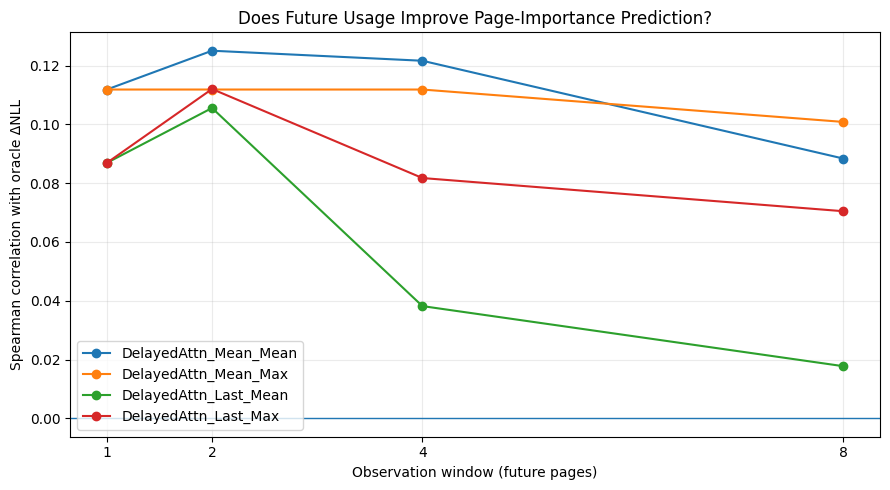

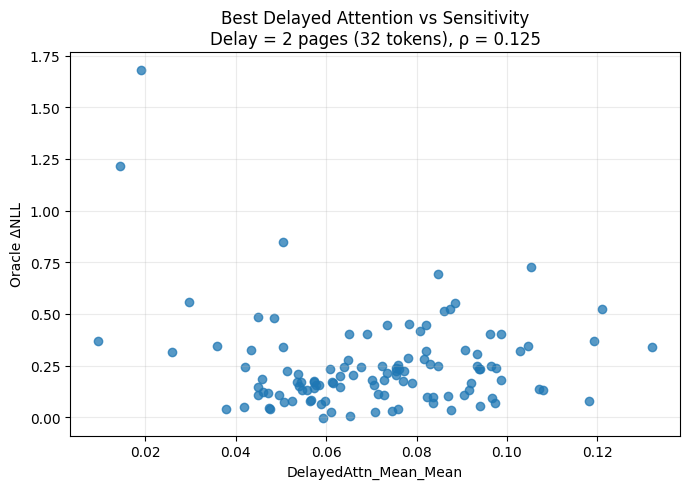


Cell 10 complete.
Delayed future usage has been evaluated as a causal page-importance signal.


In [14]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 10: Delayed-Attention Page Importance
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


# ------------------------------------------------------------
# Observation windows
#
# Number of future PAGES observed before making the decision.
# PAGE_SIZE = 16 tokens.
# ------------------------------------------------------------

DELAY_WINDOWS = [1, 2, 4, 8]


delayed_results = []
delayed_feature_frames = []


# ------------------------------------------------------------
# For each delay, measure how much FUTURE query pages
# attend back to target page p.
# ------------------------------------------------------------

for delay in DELAY_WINDOWS:

    rows = []

    # Require a complete observation window.
    #
    # Example:
    # delay = 8
    # target page 119 can use queries 120..127.
    #
    # Page 120 does not have 8 later pages inside the
    # current 2048-token attention matrix, so it is excluded
    # from this delay-specific comparison.
    max_target_page = (
        NUM_PAGES - 1 - delay
    )

    eligible_pages = [
        p for p in CANDIDATE_PAGES
        if p <= max_target_page
    ]


    for p in eligible_pages:

        q_start = p + 1
        q_end = p + delay + 1

        # -----------------------------------------------
        # Attention received by page p from future pages
        #
        # Matrix convention:
        # row    = query page q
        # column = cached page p
        # -----------------------------------------------

        future_mean_attention = (
            page_attention_mean_matrix[
                q_start:q_end,
                p
            ]
        )

        future_last_attention = (
            page_attention_last_matrix[
                q_start:q_end,
                p
            ]
        )


        assert len(future_mean_attention) == delay
        assert len(future_last_attention) == delay

        assert np.isfinite(
            future_mean_attention
        ).all()

        assert np.isfinite(
            future_last_attention
        ).all()


        rows.append({

            "Page": int(p),

            "Delay_Pages": int(delay),

            "Delay_Tokens": int(
                delay * PAGE_SIZE
            ),

            # -------------------------------------------
            # Mean-query attention from future pages
            # -------------------------------------------

            "DelayedAttn_Mean_Mean":
                float(
                    np.mean(
                        future_mean_attention
                    )
                ),

            "DelayedAttn_Mean_Max":
                float(
                    np.max(
                        future_mean_attention
                    )
                ),

            # -------------------------------------------
            # Last-query-token attention
            # -------------------------------------------

            "DelayedAttn_Last_Mean":
                float(
                    np.mean(
                        future_last_attention
                    )
                ),

            "DelayedAttn_Last_Max":
                float(
                    np.max(
                        future_last_attention
                    )
                ),
        })


    delay_df = pd.DataFrame(rows)


    # --------------------------------------------------------
    # Merge with oracle sensitivity
    # --------------------------------------------------------

    delay_df = delay_df.merge(
        oracle_analysis_df[
            [
                "Page",
                "Delta_NLL",
                "Oracle_Rank",
            ]
        ],
        on="Page",
        how="inner",
        validate="one_to_one",
    )


    delayed_feature_frames.append(
        delay_df
    )


    # --------------------------------------------------------
    # Evaluate each delayed-attention feature
    # --------------------------------------------------------

    delayed_features = [

        "DelayedAttn_Mean_Mean",
        "DelayedAttn_Mean_Max",

        "DelayedAttn_Last_Mean",
        "DelayedAttn_Last_Max",
    ]


    for feature in delayed_features:

        rho, p_value = spearmanr(
            delay_df[feature],
            delay_df["Delta_NLL"]
        )

        delayed_results.append({

            "Delay_Pages": delay,

            "Delay_Tokens":
                delay * PAGE_SIZE,

            "Pages_Evaluated":
                len(delay_df),

            "Feature": feature,

            "Spearman_Rho":
                float(rho),

            "Abs_Rho":
                abs(float(rho)),

            "P_Value":
                float(p_value),
        })


# ------------------------------------------------------------
# Combine results
# ------------------------------------------------------------

delayed_correlation_df = pd.DataFrame(
    delayed_results
)

delayed_correlation_df = (
    delayed_correlation_df
    .sort_values(
        "Abs_Rho",
        ascending=False
    )
    .reset_index(drop=True)
)


print("Delayed attention vs oracle sensitivity")
print("---------------------------------------")

display(delayed_correlation_df)


# ------------------------------------------------------------
# Best delayed-attention result
# ------------------------------------------------------------

best_delayed = (
    delayed_correlation_df.iloc[0]
)

best_delay = int(
    best_delayed["Delay_Pages"]
)

best_delay_tokens = int(
    best_delayed["Delay_Tokens"]
)

best_delayed_feature = (
    best_delayed["Feature"]
)

best_delayed_rho = float(
    best_delayed["Spearman_Rho"]
)

best_delayed_p = float(
    best_delayed["P_Value"]
)


print("\nBest delayed-attention signal")
print("-----------------------------")

print(
    f"Observation window:  "
    f"{best_delay} pages "
    f"({best_delay_tokens} tokens)"
)

print(
    f"Feature:             "
    f"{best_delayed_feature}"
)

print(
    f"Spearman rho:        "
    f"{best_delayed_rho:.4f}"
)

print(
    f"p-value:             "
    f"{best_delayed_p:.6f}"
)


# ------------------------------------------------------------
# Compare with previous immediate signals
# ------------------------------------------------------------

print("\nBest individual signals so far")
print("------------------------------")

print(
    f"Immediate attention: "
    f"{best_rho:.4f}"
)

print(
    f"Confidence:          "
    f"{best_conf_rho:.4f}"
)

print(
    f"Position:            "
    f"{best_position_rho:.4f}"
)

print(
    f"Delayed attention:   "
    f"{best_delayed_rho:.4f}"
)


# ------------------------------------------------------------
# Plot correlation vs observation window
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))


for feature in [
    "DelayedAttn_Mean_Mean",
    "DelayedAttn_Mean_Max",
    "DelayedAttn_Last_Mean",
    "DelayedAttn_Last_Max",
]:

    temp = (
        delayed_correlation_df[
            delayed_correlation_df[
                "Feature"
            ] == feature
        ]
        .sort_values("Delay_Pages")
    )

    plt.plot(
        temp["Delay_Pages"],
        temp["Spearman_Rho"],
        marker="o",
        label=feature,
    )


plt.axhline(
    0,
    linewidth=1
)

plt.xlabel(
    "Observation window (future pages)"
)

plt.ylabel(
    "Spearman correlation with oracle ΔNLL"
)

plt.title(
    "Does Future Usage Improve Page-Importance Prediction?"
)

plt.xticks(DELAY_WINDOWS)

plt.legend()

plt.grid(alpha=0.25)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# Get dataframe corresponding to the winning window
# ------------------------------------------------------------

best_delay_df = next(
    df
    for df in delayed_feature_frames
    if int(df["Delay_Pages"].iloc[0])
    == best_delay
)


# ------------------------------------------------------------
# Scatter plot of best delayed signal
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.scatter(
    best_delay_df[
        best_delayed_feature
    ],
    best_delay_df[
        "Delta_NLL"
    ],
    alpha=0.75
)

plt.xlabel(
    best_delayed_feature
)

plt.ylabel(
    "Oracle ΔNLL"
)

plt.title(
    f"Best Delayed Attention vs Sensitivity\n"
    f"Delay = {best_delay} pages "
    f"({best_delay_tokens} tokens), "
    f"ρ = {best_delayed_rho:.3f}"
)

plt.grid(alpha=0.25)

plt.tight_layout()

plt.show()


print("\nCell 10 complete.")

print(
    "Delayed future usage has been evaluated "
    "as a causal page-importance signal."
)

### Cell 10 — Delayed Attention as a Page-Importance Signal

Cell 10 tests whether page importance becomes easier to predict after observing how subsequent tokens actually use the page.

The immediate-attention experiment in Cell 7 makes a precision decision at the moment page \(p\) finishes. At that point, no future page has yet had the opportunity to attend to \(p\).

Cell 10 therefore considers a delayed decision.

A newly completed page remains at the default precision temporarily:

\[
\text{new page} \rightarrow INT8
\]

and attention from the next few query pages is observed before making a possible precision decision.

The tested observation windows were:

\[
1,\ 2,\ 4,\ 8\text{ pages}
\]

which correspond to:

\[
16,\ 32,\ 64,\ 128\text{ future tokens}.
\]

For each target page \(p\), the experiment measures the attention received from the following query pages using several statistics:

- mean of mean-query attention,
- maximum mean-query attention,
- mean last-token attention,
- maximum last-token attention.

All of these signals are causal at the delayed decision point because the observed query pages have already occurred.

---

### Results

The strongest delayed-attention signal was:

\[
\text{DelayedAttn\_Mean\_Mean}
\]

using an observation window of:

\[
2\text{ pages}=32\text{ tokens}.
\]

Its correlation with the Notebook 5 sensitivity oracle was:

\[
\rho=0.1250
\]

with:

\[
p=0.183.
\]

This is a weak positive relationship and is not statistically significant on the current sample.

The strongest individual signals measured so far are:

\[
\text{Immediate attention: } \rho=0.1533
\]

\[
\text{Page position: } |\rho|=0.1406
\]

\[
\text{Delayed attention: } \rho=0.1250
\]

\[
\text{Confidence: } \rho=0.1022.
\]

Therefore delayed attention did **not** improve over the best immediate-attention signal.

---

### Effect of increasing the observation window

Prediction quality did not increase monotonically as more future pages were observed.

For the strongest delayed-attention family, the approximate correlations were:

\[
1\text{ page}: \rho\approx0.112
\]

\[
2\text{ pages}: \rho\approx0.125
\]

\[
4\text{ pages}: \rho\approx0.122
\]

\[
8\text{ pages}: \rho\approx0.088.
\]

Therefore waiting longer does not automatically produce a better estimate of page sensitivity.

Several last-token attention statistics deteriorated even more strongly for longer observation windows.

This suggests that raw attention mass and INT4 quantization sensitivity measure different properties of a KV page.

A page can receive substantial attention yet tolerate quantization well, while another page can receive modest attention but contain Keys or Values for which quantization error has a large effect on future predictions.

---

### Current conclusion

The experiment does not support a policy based purely on delayed attention such as:

\[
\text{low future attention} \Rightarrow INT4.
\]

Instead:

\[
\boxed{
\text{Raw attention usage alone remains a weak predictor of INT4 sensitivity.}
}
\]

This is true both at page creation time and after short future observation windows.

---

### Important methodological caveat

The Notebook 5 fixed-horizon oracle measures the effect of changing page \(p\) from INT8 to INT4 immediately after the page is completed:

\[
S(p)
=
NLL_{\text{INT4},p}
-
NLL_{\text{INT8},p}.
\]

A genuinely delayed policy would instead keep the page at INT8 during the observation period and only make the precision decision afterward.

Therefore, if delayed attention becomes part of the final policy, a new delay-aligned sensitivity experiment should eventually be created in which the INT4 demotion occurs only after the observation window.

Cell 10 currently uses delayed attention only as an exploratory predictor of the original Notebook 5 oracle.

---

### Next direction

No single signal tested so far is sufficiently strong:

- immediate attention is weak,
- confidence is weak,
- page position is weak,
- delayed attention is weak.

However, these signals describe different aspects of the model state and may contain complementary information.

The next experiment therefore evaluates **hybrid predictors** that combine several causal features.

Both simple and nonlinear models will be tested, including:

- regularized linear regression,
- bagging-style tree ensembles,
- boosting-style tree ensembles.

Because only 115 page examples from one sequence are currently available, evaluation must use held-out pages rather than training and evaluating on the same data.

#11: Hybrid predictors with blocked cross-validation

Your bagging/boosting idea fits here.

But we should not train a Random Forest or Gradient Boosting model on 115 rows and then report its score on those same 115 rows. It could easily memorize them.

We'll use 5 blocked folds. Each fold holds out one contiguous region of the sequence:

$$ \boxed{\text{train on other regions} \rightarrow \text{predict unseen contiguous pages}} $$

Every page ultimately receives an out-of-fold prediction from a model that was not trained on that page.

We'll test:

Ridge — simple linear baseline.
Random Forest — bagging.
Extra Trees — stronger randomized bagging.
Gradient Boosting — boosting.

And we'll deliberately compare two feature sets:

Immediate hybrid: attention + confidence + position only.
This is fully aligned with the current immediate-demotion oracle.

Delayed exploratory hybrid: same features + best 2-page delayed attention.
This is exploratory because of the oracle-timing caveat above.

Blocked cross-validation
------------------------
Fold 1: test pages 6-28 (23 pages)
Fold 2: test pages 29-51 (23 pages)
Fold 3: test pages 52-74 (23 pages)
Fold 4: test pages 75-97 (23 pages)
Fold 5: test pages 98-120 (23 pages)

Blocked out-of-fold hybrid results
----------------------------------


,Feature_Set,Model,Num_Features,Spearman_Rho,Abs_Rho,P_Value,MAE,RMSE
0,Delayed_2pages,GradientBoosting,17,0.162369,0.162369,0.082968,0.138107,0.216208
1,Delayed_2pages,RandomForest,17,0.133851,0.133851,0.153827,0.149853,0.227039
2,Immediate,GradientBoosting,13,0.050750,0.050750,0.590142,0.143883,0.227161
3,Delayed_2pages,ExtraTrees,17,-0.008025,0.008025,0.932167,0.148257,0.229266
4,Immediate,Ridge,13,-0.032273,0.032273,0.732049,0.163481,0.237541
5,Immediate,RandomForest,13,-0.056687,0.056687,0.547342,0.162477,0.237069
6,Delayed_2pages,Ridge,17,-0.062811,0.062811,0.504855,0.168601,0.241186
7,Immediate,ExtraTrees,13,-0.090294,0.090294,0.337215,0.155126,0.234158



Best hybrid predictor
---------------------
Feature set:     Delayed_2pages
Model:           GradientBoosting
Spearman rho:    0.1624
MAE:             0.138107
RMSE:            0.216208

Comparison
----------
Immediate attention: rho = 0.1533
Confidence:          rho = 0.1022
Position:            |rho| = 0.1406
Delayed attention:   rho = 0.1250
Hybrid OOF:          rho = 0.1624


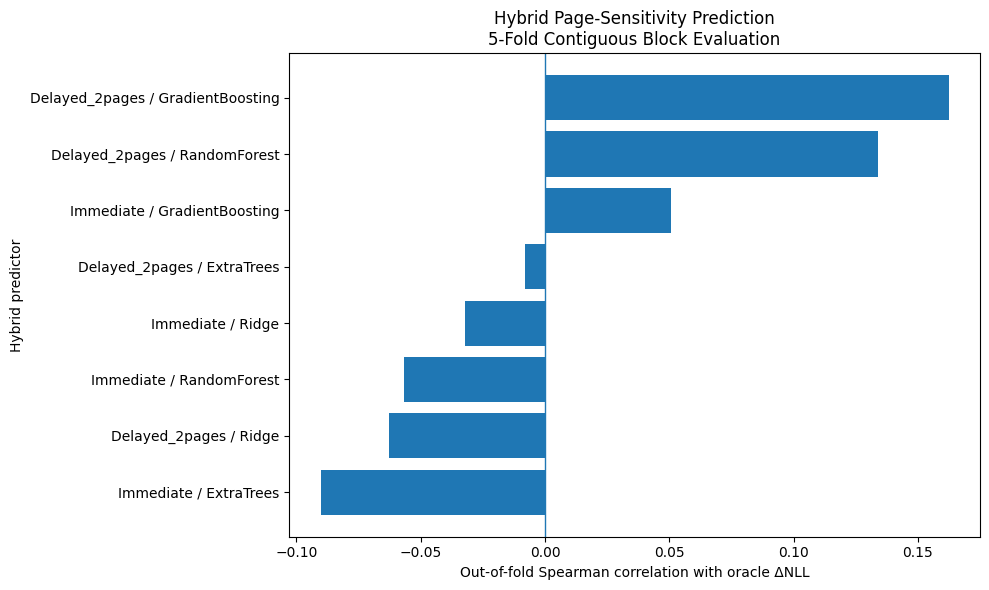

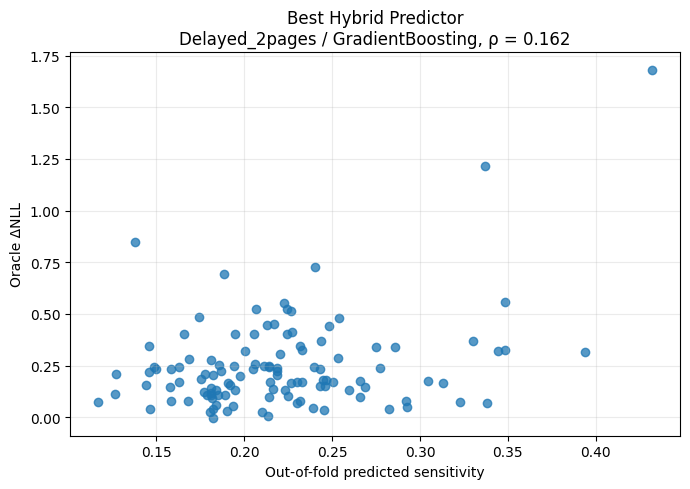


Prediction preview
------------------


,Page,Oracle_Delta_NLL,Predicted_Delta_NLL
0,6,0.306892,0.220320
1,7,0.155956,0.191874
2,8,0.179487,0.246810
3,9,0.553010,0.222847
4,10,0.486313,0.174329
5,11,0.326217,0.348510
6,12,1.682524,0.432079
7,13,0.248027,0.214308
8,14,0.237502,0.277126
9,15,0.222520,0.186868



Cell 11 complete.
Bagging, boosting, and linear hybrid predictors have been evaluated using out-of-fold contiguous page blocks.


In [15]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 11: Hybrid Predictors with Blocked Cross-Validation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
)


# ------------------------------------------------------------
# 1. Add best delayed-attention features to analysis table
# ------------------------------------------------------------

delay2_df = next(
    df for df in delayed_feature_frames
    if int(df["Delay_Pages"].iloc[0]) == 2
)

delay2_features = delay2_df[
    [
        "Page",
        "DelayedAttn_Mean_Mean",
        "DelayedAttn_Mean_Max",
        "DelayedAttn_Last_Mean",
        "DelayedAttn_Last_Max",
    ]
].copy()


hybrid_df = analysis_df.merge(
    delay2_features,
    on="Page",
    how="inner",
    validate="one_to_one",
)

assert len(hybrid_df) == 115


# ------------------------------------------------------------
# 2. Define feature sets
#
# Immediate set:
# available exactly when the page finishes.
#
# Delayed set:
# adds observations from next 2 pages (32 tokens).
# ------------------------------------------------------------

IMMEDIATE_FEATURES = [

    # Immediate attention
    "Attn_Self_Mean",
    "Attn_Self_Last",
    "Attn_Self_LayerStd",
    "Attn_Self_LayerMax",
    "Attn_PageEntropy_Mean",
    "Attn_PageEntropy_Last",

    # Confidence
    "Conf_Entropy_Mean",
    "Conf_Entropy_Last",
    "Conf_Top1_Mean",
    "Conf_Top1_Last",
    "Conf_Margin_Mean",
    "Conf_Margin_Last",

    # Position
    "Normalized_Position",
]


DELAYED_FEATURES = (
    IMMEDIATE_FEATURES
    + [
        "DelayedAttn_Mean_Mean",
        "DelayedAttn_Mean_Max",
        "DelayedAttn_Last_Mean",
        "DelayedAttn_Last_Max",
    ]
)


FEATURE_SETS = {
    "Immediate": IMMEDIATE_FEATURES,
    "Delayed_2pages": DELAYED_FEATURES,
}


# ------------------------------------------------------------
# 3. Models
#
# Tree models are intentionally regularized because we have
# only 115 examples.
# ------------------------------------------------------------

MODELS = {

    "Ridge": Pipeline([
        ("scale", StandardScaler()),
        ("model", Ridge(alpha=10.0)),
    ]),

    # Bagging
    "RandomForest": RandomForestRegressor(
        n_estimators=300,
        max_depth=3,
        min_samples_leaf=5,
        max_features=0.7,
        random_state=SEED,
        n_jobs=-1,
    ),

    # Randomized bagging
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=3,
        min_samples_leaf=5,
        max_features=0.7,
        random_state=SEED,
        n_jobs=-1,
    ),

    # Boosting
    "GradientBoosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=5,
        loss="huber",
        random_state=SEED,
    ),
}


# ------------------------------------------------------------
# 4. Build five CONTIGUOUS test blocks
#
# We do not randomly mix nearby pages between train/test.
# ------------------------------------------------------------

num_samples = len(hybrid_df)

all_indices = np.arange(num_samples)

blocked_folds = np.array_split(
    all_indices,
    5
)


print("Blocked cross-validation")
print("------------------------")

for fold_idx, test_idx in enumerate(blocked_folds):

    pages = hybrid_df.iloc[test_idx]["Page"]

    print(
        f"Fold {fold_idx + 1}: "
        f"test pages {pages.min()}-{pages.max()} "
        f"({len(test_idx)} pages)"
    )


# ------------------------------------------------------------
# 5. Out-of-fold evaluation
# ------------------------------------------------------------

target = hybrid_df["Delta_NLL"].to_numpy()

result_rows = []

oof_predictions = {}


for feature_set_name, feature_names in FEATURE_SETS.items():

    X = hybrid_df[
        feature_names
    ].to_numpy(dtype=float)

    assert np.isfinite(X).all()


    for model_name, model_template in MODELS.items():

        predictions = np.full(
            num_samples,
            np.nan,
            dtype=float
        )


        for test_idx in blocked_folds:

            train_mask = np.ones(
                num_samples,
                dtype=bool
            )

            train_mask[test_idx] = False

            train_idx = all_indices[
                train_mask
            ]


            model = clone(
                model_template
            )


            model.fit(
                X[train_idx],
                target[train_idx]
            )


            predictions[test_idx] = (
                model.predict(
                    X[test_idx]
                )
            )


        assert np.isfinite(
            predictions
        ).all()


        # -----------------------------------------------
        # Ranking metric
        # -----------------------------------------------

        rho, p_value = spearmanr(
            predictions,
            target
        )


        # -----------------------------------------------
        # Regression metrics
        # -----------------------------------------------

        mae = mean_absolute_error(
            target,
            predictions
        )

        rmse = np.sqrt(
            mean_squared_error(
                target,
                predictions
            )
        )


        key = (
            feature_set_name,
            model_name
        )

        oof_predictions[key] = (
            predictions
        )


        result_rows.append({

            "Feature_Set":
                feature_set_name,

            "Model":
                model_name,

            "Num_Features":
                len(feature_names),

            "Spearman_Rho":
                float(rho),

            "Abs_Rho":
                abs(float(rho)),

            "P_Value":
                float(p_value),

            "MAE":
                float(mae),

            "RMSE":
                float(rmse),
        })


# ------------------------------------------------------------
# 6. Results
# ------------------------------------------------------------

hybrid_results_df = pd.DataFrame(
    result_rows
)

hybrid_results_df = (
    hybrid_results_df
    .sort_values(
        "Spearman_Rho",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nBlocked out-of-fold hybrid results")
print("----------------------------------")

display(hybrid_results_df)


# ------------------------------------------------------------
# 7. Winning model
# ------------------------------------------------------------

best_hybrid_row = (
    hybrid_results_df.iloc[0]
)

best_hybrid_feature_set = (
    best_hybrid_row["Feature_Set"]
)

best_hybrid_model = (
    best_hybrid_row["Model"]
)

best_hybrid_rho = float(
    best_hybrid_row["Spearman_Rho"]
)

best_hybrid_key = (
    best_hybrid_feature_set,
    best_hybrid_model
)

best_hybrid_predictions = (
    oof_predictions[
        best_hybrid_key
    ]
)


print("\nBest hybrid predictor")
print("---------------------")

print(
    f"Feature set:     "
    f"{best_hybrid_feature_set}"
)

print(
    f"Model:           "
    f"{best_hybrid_model}"
)

print(
    f"Spearman rho:    "
    f"{best_hybrid_rho:.4f}"
)

print(
    f"MAE:             "
    f"{best_hybrid_row['MAE']:.6f}"
)

print(
    f"RMSE:            "
    f"{best_hybrid_row['RMSE']:.6f}"
)


# ------------------------------------------------------------
# 8. Compare against best individual signals
# ------------------------------------------------------------

print("\nComparison")
print("----------")

print(
    f"Immediate attention: "
    f"rho = {best_rho:.4f}"
)

print(
    f"Confidence:          "
    f"rho = {best_conf_rho:.4f}"
)

print(
    f"Position:            "
    f"|rho| = {abs(best_position_rho):.4f}"
)

print(
    f"Delayed attention:   "
    f"rho = {best_delayed_rho:.4f}"
)

print(
    f"Hybrid OOF:          "
    f"rho = {best_hybrid_rho:.4f}"
)


# ------------------------------------------------------------
# 9. Plot model comparison
# ------------------------------------------------------------

plot_results = (
    hybrid_results_df
    .copy()
)

plot_results["Label"] = (
    plot_results["Feature_Set"]
    + " / "
    + plot_results["Model"]
)

plot_results = (
    plot_results
    .sort_values("Spearman_Rho")
)


plt.figure(figsize=(10, 6))

plt.barh(
    plot_results["Label"],
    plot_results["Spearman_Rho"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel(
    "Out-of-fold Spearman correlation with oracle ΔNLL"
)

plt.ylabel(
    "Hybrid predictor"
)

plt.title(
    "Hybrid Page-Sensitivity Prediction\n"
    "5-Fold Contiguous Block Evaluation"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. OOF scatter for winning predictor
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.scatter(
    best_hybrid_predictions,
    target,
    alpha=0.75
)

plt.xlabel(
    "Out-of-fold predicted sensitivity"
)

plt.ylabel(
    "Oracle ΔNLL"
)

plt.title(
    f"Best Hybrid Predictor\n"
    f"{best_hybrid_feature_set} / "
    f"{best_hybrid_model}, "
    f"ρ = {best_hybrid_rho:.3f}"
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Save OOF predictions in table
# ------------------------------------------------------------

hybrid_prediction_df = pd.DataFrame({

    "Page":
        hybrid_df["Page"],

    "Oracle_Delta_NLL":
        target,

    "Predicted_Delta_NLL":
        best_hybrid_predictions,
})


print("\nPrediction preview")
print("------------------")

display(
    hybrid_prediction_df.head(15)
)


print("\nCell 11 complete.")

print(
    "Bagging, boosting, and linear hybrid predictors "
    "have been evaluated using out-of-fold contiguous "
    "page blocks."
)

### Cell 11 — Hybrid Prediction with Bagging and Boosting

Cell 11 tests whether multiple weak inference-time signals become more useful when combined using machine-learning models.

The available signals include:

- immediate attention,
- model confidence,
- page position,
- and, in the delayed feature set, attention received during the next two pages.

The prediction target remains the Notebook 5 fixed-horizon oracle:

\[
S(p)=\Delta NLL.
\]

---

### Why blocked cross-validation is required

The current dataset contains only:

\[
115
\]

candidate pages from a single WikiText-2 sequence.

Training and evaluating a nonlinear model on the same 115 pages could therefore produce severe overfitting.

To reduce this risk, the pages were divided into five contiguous blocks:

- Pages 6–28
- Pages 29–51
- Pages 52–74
- Pages 75–97
- Pages 98–120

For each fold, one contiguous block is completely held out while the model is trained on the remaining pages.

Thus every reported prediction is an **out-of-fold prediction** for a page that was not used to train that model.

This evaluation is more difficult than a random train/test split because nearby pages are not randomly mixed between training and testing.

---

### Models tested

Four predictor families were compared.

#### Ridge regression

A regularized linear model used as a simple baseline.

#### Random Forest

A bagging-style ensemble of decision trees.

#### Extra Trees

A more strongly randomized bagging-style tree ensemble.

#### Gradient Boosting

A boosting model in which small trees are added sequentially to correct the errors of previous trees.

Two feature sets were evaluated:

1. **Immediate**

   Uses only information available when the page finishes.

2. **Delayed 2 pages**

   Adds attention received during the following:

\[
2\text{ pages}=32\text{ tokens}.
\]

---

### Results

The best hybrid predictor was:

\[
\boxed{
\text{Delayed 2-page features + Gradient Boosting}
}
\]

with:

\[
\rho=0.1624
\]

\[
MAE=0.1381
\]

and:

\[
RMSE=0.2162.
\]

Its correlation is only slightly higher than the best individual immediate-attention feature:

\[
0.1533 \rightarrow 0.1624.
\]

The best Random Forest configuration obtained:

\[
\rho=0.1339.
\]

However, several models generalized poorly:

\[
\rho_{\text{Immediate Random Forest}}
\approx -0.057
\]

\[
\rho_{\text{Immediate Extra Trees}}
\approx -0.090
\]

\[
\rho_{\text{Delayed Ridge}}
\approx -0.063.
\]

This indicates that combining features does not automatically produce a reliable predictor.

---

### Comparison with individual signals

The strongest results obtained so far are approximately:

\[
\text{Immediate attention: } \rho=0.1533
\]

\[
\text{Position: } |\rho|=0.1406
\]

\[
\text{Delayed attention: } \rho=0.1250
\]

\[
\text{Confidence: } \rho=0.1022
\]

\[
\text{Hybrid Gradient Boosting: } \rho=0.1624.
\]

Therefore the hybrid model provides only a small improvement.

The result suggests that the signals contain some complementary information, but the current dataset is too small and the relationship is too weak to accurately reconstruct the full oracle ranking.

---

### Extreme sensitivities remain difficult

The regression model also tends to compress very large sensitivity values toward the center of the distribution.

For example:

\[
\text{Page 12}
\]

has oracle sensitivity:

\[
\Delta NLL=1.6825
\]

but its out-of-fold prediction is only approximately:

\[
\hat{\Delta NLL}=0.4321.
\]

This is important because the most-sensitive pages are precisely the pages that may eventually justify promotion to FP16.

Therefore regression error alone may not be the best way to evaluate the final precision policy.

---

### Interpretation

The current evidence does not support using the hybrid regressor directly as a final precision controller.

However, the final system does not actually require an exact prediction of:

\[
\Delta NLL.
\]

The real decision is closer to:

\[
\text{clearly low sensitivity} \rightarrow INT4
\]

\[
\text{uncertain / medium sensitivity} \rightarrow INT8
\]

\[
\text{clearly high sensitivity} \rightarrow FP16.
\]

Therefore the next experiment will evaluate the predictor using **sensitivity thresholds** rather than requiring an accurate regression value for every page.

This is also more consistent with the intended three-tier architecture.

#12: Threshold-oriented evaluation

Does our best OOF hybrid predictor at least distinguish low-sensitivity and high-sensitivity pages?

This is where we transition from “predict exact \(\Delta NLL\)” toward your idea:

$$ \hat S(p) < T_{\text{low}} \Rightarrow INT4 $$ $$ T_{\text{low}}\leq\hat S(p)\leq T_{\text{high}} \Rightarrow INT8 $$ $$ \hat S(p)>T_{\text{high}} \Rightarrow FP16. $$

But we won't choose final thresholds yet.

Threshold-oriented predictor evaluation
---------------------------------------


,Task,Oracle_Threshold,Positive_Pages,Negative_Pages,ROC_AUC,Average_Precision,Positive_Rate
0,Low -> INT4 candidate,0.05,10,105,0.563810,0.109659,0.086957
1,Low -> INT4 candidate,0.10,24,91,0.505266,0.256215,0.208696
2,Low -> INT4 candidate,0.15,40,75,0.585500,0.439162,0.347826
3,High -> FP16 candidate,0.30,32,83,0.670369,0.516080,0.278261
4,High -> FP16 candidate,0.40,20,95,0.572368,0.267620,0.173913
5,High -> FP16 candidate,0.50,10,105,0.635714,0.276638,0.086957



Performance relative to random ranking
--------------------------------------


,Task,Oracle_Threshold,Positive_Pages,ROC_AUC,Average_Precision,Positive_Rate,AP_Over_Random
0,Low -> INT4 candidate,0.05,10,0.563810,0.109659,0.086957,1.261077
1,Low -> INT4 candidate,0.10,24,0.505266,0.256215,0.208696,1.227697
2,Low -> INT4 candidate,0.15,40,0.585500,0.439162,0.347826,1.262590
3,High -> FP16 candidate,0.30,32,0.670369,0.516080,0.278261,1.854663
4,High -> FP16 candidate,0.40,20,0.572368,0.267620,0.173913,1.538815
5,High -> FP16 candidate,0.50,10,0.635714,0.276638,0.086957,3.181339


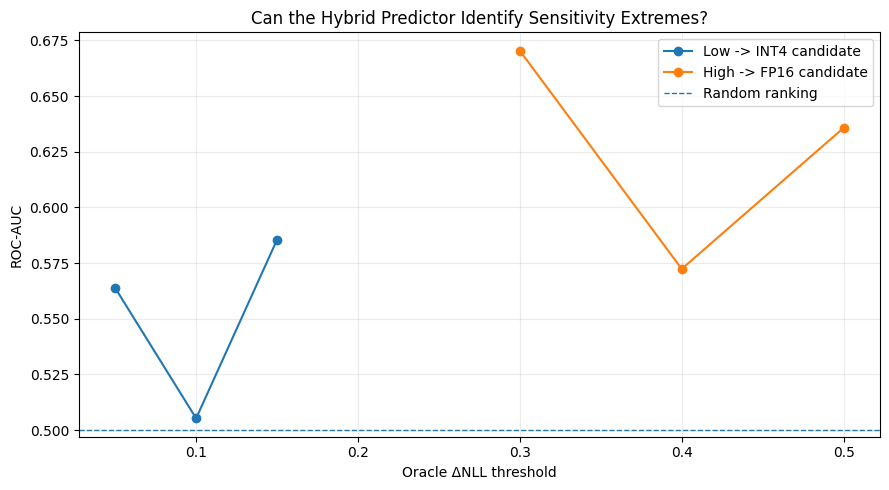


Representative oracle tiers (diagnostic only):
Low  <= 0.1
High >= 0.4


,Pages
Oracle_Tier,
Low,24
Medium,71
High,20


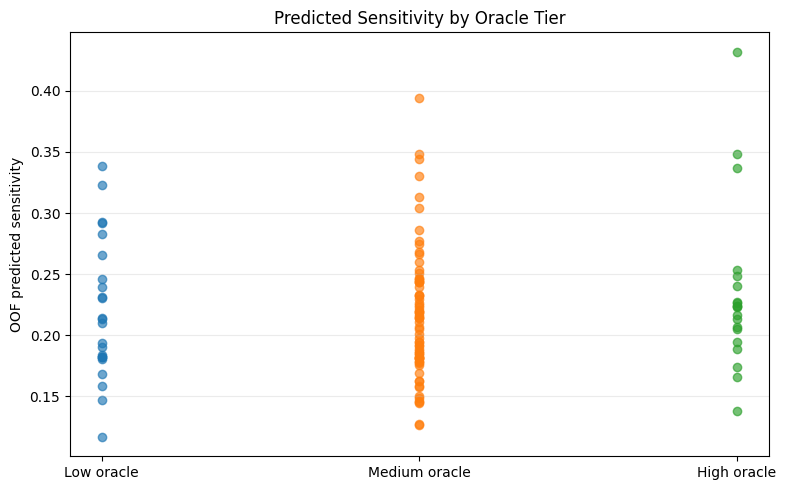


Cell 12 complete.
The best hybrid predictor has now been evaluated for detecting low- and high-sensitivity pages under several Delta-NLL thresholds.


In [16]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 12: Threshold-Oriented Evaluation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)


# ------------------------------------------------------------
# Oracle and OOF predictor
# ------------------------------------------------------------

oracle = hybrid_prediction_df[
    "Oracle_Delta_NLL"
].to_numpy()

predicted = hybrid_prediction_df[
    "Predicted_Delta_NLL"
].to_numpy()

pages = hybrid_prediction_df[
    "Page"
].to_numpy()


# ------------------------------------------------------------
# Candidate ORACLE thresholds
#
# These do NOT define the final policy yet.
#
# Low sensitivity:
# page may be a good INT4 candidate.
#
# High sensitivity:
# page may deserve protection / FP16 consideration.
# ------------------------------------------------------------

LOW_THRESHOLDS = [
    0.05,
    0.10,
    0.15,
]

HIGH_THRESHOLDS = [
    0.30,
    0.40,
    0.50,
]


evaluation_rows = []


# ------------------------------------------------------------
# LOW-sensitivity detection
#
# Oracle positive class:
#
# Delta NLL <= threshold
#
# For the predictor:
# LOWER predicted sensitivity means more likely low.
#
# Therefore use -prediction as classification score.
# ------------------------------------------------------------

for threshold in LOW_THRESHOLDS:

    labels = (
        oracle <= threshold
    ).astype(int)

    num_positive = int(
        labels.sum()
    )

    num_negative = int(
        len(labels) - num_positive
    )

    if (
        num_positive == 0
        or num_negative == 0
    ):
        continue


    auc = roc_auc_score(
        labels,
        -predicted
    )

    ap = average_precision_score(
        labels,
        -predicted
    )


    evaluation_rows.append({

        "Task":
            "Low -> INT4 candidate",

        "Oracle_Threshold":
            threshold,

        "Positive_Pages":
            num_positive,

        "Negative_Pages":
            num_negative,

        "ROC_AUC":
            float(auc),

        "Average_Precision":
            float(ap),

        "Positive_Rate":
            float(labels.mean()),
    })


# ------------------------------------------------------------
# HIGH-sensitivity detection
#
# Oracle positive class:
#
# Delta NLL >= threshold
#
# HIGH predictor score means more likely high.
# ------------------------------------------------------------

for threshold in HIGH_THRESHOLDS:

    labels = (
        oracle >= threshold
    ).astype(int)

    num_positive = int(
        labels.sum()
    )

    num_negative = int(
        len(labels) - num_positive
    )

    if (
        num_positive == 0
        or num_negative == 0
    ):
        continue


    auc = roc_auc_score(
        labels,
        predicted
    )

    ap = average_precision_score(
        labels,
        predicted
    )


    evaluation_rows.append({

        "Task":
            "High -> FP16 candidate",

        "Oracle_Threshold":
            threshold,

        "Positive_Pages":
            num_positive,

        "Negative_Pages":
            num_negative,

        "ROC_AUC":
            float(auc),

        "Average_Precision":
            float(ap),

        "Positive_Rate":
            float(labels.mean()),
    })


# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------

threshold_eval_df = pd.DataFrame(
    evaluation_rows
)


print("Threshold-oriented predictor evaluation")
print("---------------------------------------")

display(threshold_eval_df)


# ------------------------------------------------------------
# Compare Average Precision against prevalence
#
# Random ranking has expected AP approximately equal to
# positive-class prevalence.
# ------------------------------------------------------------

threshold_eval_df[
    "AP_Over_Random"
] = (
    threshold_eval_df[
        "Average_Precision"
    ]
    /
    threshold_eval_df[
        "Positive_Rate"
    ]
)


print("\nPerformance relative to random ranking")
print("--------------------------------------")

display(
    threshold_eval_df[
        [
            "Task",
            "Oracle_Threshold",
            "Positive_Pages",
            "ROC_AUC",
            "Average_Precision",
            "Positive_Rate",
            "AP_Over_Random",
        ]
    ]
)


# ------------------------------------------------------------
# Plot ROC-AUC by oracle threshold
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for task in threshold_eval_df["Task"].unique():

    temp = threshold_eval_df[
        threshold_eval_df[
            "Task"
        ] == task
    ]

    plt.plot(
        temp["Oracle_Threshold"],
        temp["ROC_AUC"],
        marker="o",
        label=task,
    )


plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1,
    label="Random ranking",
)

plt.xlabel(
    "Oracle ΔNLL threshold"
)

plt.ylabel(
    "ROC-AUC"
)

plt.title(
    "Can the Hybrid Predictor Identify Sensitivity Extremes?"
)

plt.legend()

plt.grid(alpha=0.25)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# Show actual low/high pages for representative thresholds
#
# These are diagnostics only.
# ------------------------------------------------------------

REP_LOW = 0.10
REP_HIGH = 0.40


diagnostic_df = hybrid_prediction_df.copy()


diagnostic_df["Oracle_Tier"] = np.where(

    diagnostic_df[
        "Oracle_Delta_NLL"
    ] <= REP_LOW,

    "Low",

    np.where(

        diagnostic_df[
            "Oracle_Delta_NLL"
        ] >= REP_HIGH,

        "High",

        "Medium"
    )
)


print(
    f"\nRepresentative oracle tiers "
    f"(diagnostic only):"
)

print(
    f"Low  <= {REP_LOW}"
)

print(
    f"High >= {REP_HIGH}"
)


tier_counts = (
    diagnostic_df[
        "Oracle_Tier"
    ]
    .value_counts()
    .reindex(
        [
            "Low",
            "Medium",
            "High",
        ]
    )
)


display(
    tier_counts.rename(
        "Pages"
    ).to_frame()
)


# ------------------------------------------------------------
# Compare predictor distributions by oracle tier
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))


for tier in [
    "Low",
    "Medium",
    "High",
]:

    values = diagnostic_df.loc[
        diagnostic_df[
            "Oracle_Tier"
        ] == tier,
        "Predicted_Delta_NLL"
    ]

    plt.scatter(
        np.full(
            len(values),
            [
                "Low",
                "Medium",
                "High",
            ].index(tier)
        ),
        values,
        alpha=0.65,
        label=tier,
    )


plt.xticks(
    [0, 1, 2],
    [
        "Low oracle",
        "Medium oracle",
        "High oracle",
    ]
)

plt.ylabel(
    "OOF predicted sensitivity"
)

plt.title(
    "Predicted Sensitivity by Oracle Tier"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.show()


print("\nCell 12 complete.")

print(
    "The best hybrid predictor has now been evaluated "
    "for detecting low- and high-sensitivity pages "
    "under several Delta-NLL thresholds."
)

Cell 12 gives us an interesting asymmetry:

Detecting low-sensitivity / INT4-safe pages is still weak: best ROC-AUC only about 0.586.
Detecting high-sensitivity / FP16-worthy pages looks more promising. At \(\Delta NLL\ge 0.30\), ROC-AUC is 0.670 and AP is 0.516 versus a random baseline of 0.278. For the very-high threshold \(\Delta NLL\ge0.50\), AP is about 3.18× random.

So our signals may be better at answering “which pages are dangerous to quantize?” than “which pages are definitely safe for INT4?”

#13: Direct classification of low- and high-sensitivity pages

Until now, Gradient Boosting tried to predict the actual value:

$$ \hat{\Delta NLL}. $$

But our final system does not really need exact regression.

It wants decisions like:

$$ \text{Low sensitivity?} $$

and

$$ \text{High sensitivity?} $$

So Cell 13 trains classifiers directly for these questions.

For this exploratory experiment we'll use:

$$ \boxed{\Delta NLL \le 0.15} $$

as the low-sensitivity class, because it contains 40 pages and Cell 12 showed the best low-side AUC among our tested thresholds.

For high sensitivity:

$$ \boxed{\Delta NLL \ge 0.30} $$

because it contains 32 pages and gave the strongest high-side AUC.

These are experimental labels, not final production thresholds.

Direct classification targets
-----------------------------
Low sensitivity  <= 0.15: 40 pages
High sensitivity >= 0.3: 32 pages

Task: Low_INT4_Candidate
Positive pages: 40 / 115

Task: High_FP16_Candidate
Positive pages: 32 / 115

Direct classification results
-----------------------------


,Task,Feature_Set,Classifier,Num_Features,Positive_Pages,Positive_Rate,ROC_AUC,Average_Precision,AP_Over_Random,Precision_at_0.5,Recall_at_0.5,F1_at_0.5
0,High_FP16_Candidate,Delayed_2pages,GradientBoosting,17,32,0.278261,0.744729,0.479790,1.724244,0.405405,0.46875,0.434783
1,High_FP16_Candidate,Delayed_2pages,RandomForest,17,32,0.278261,0.739458,0.468798,1.684741,0.531250,0.53125,0.531250
2,High_FP16_Candidate,Delayed_2pages,ExtraTrees,17,32,0.278261,0.687123,0.423101,1.520520,0.394737,0.46875,0.428571
3,High_FP16_Candidate,Immediate,GradientBoosting,13,32,0.278261,0.544992,0.294797,1.059427,0.263158,0.15625,0.196078
4,High_FP16_Candidate,Immediate,ExtraTrees,13,32,0.278261,0.534262,0.293725,1.055573,0.305556,0.34375,0.323529
5,High_FP16_Candidate,Immediate,RandomForest,13,32,0.278261,0.521837,0.278382,1.000434,0.136364,0.09375,0.111111
6,High_FP16_Candidate,Immediate,LogisticRegression,13,32,0.278261,0.493223,0.300971,1.081614,0.288462,0.46875,0.357143
7,High_FP16_Candidate,Delayed_2pages,LogisticRegression,17,32,0.278261,0.486822,0.297705,1.069879,0.288462,0.46875,0.357143
8,Low_INT4_Candidate,Immediate,LogisticRegression,13,40,0.347826,0.541667,0.423519,1.217618,0.422222,0.47500,0.447059
9,Low_INT4_Candidate,Delayed_2pages,LogisticRegression,17,40,0.347826,0.531667,0.410439,1.180013,0.400000,0.45000,0.423529



Best classifier per task
------------------------


,Task,Feature_Set,Classifier,Num_Features,Positive_Pages,Positive_Rate,ROC_AUC,Average_Precision,AP_Over_Random,Precision_at_0.5,Recall_at_0.5,F1_at_0.5
0,High_FP16_Candidate,Delayed_2pages,GradientBoosting,17,32,0.278261,0.744729,0.479790,1.724244,0.405405,0.46875,0.434783
1,Low_INT4_Candidate,Immediate,LogisticRegression,13,40,0.347826,0.541667,0.423519,1.217618,0.422222,0.47500,0.447059



Comparison with Cell 12
-----------------------
Low_INT4_Candidate:
  Best direct classifier: Immediate / LogisticRegression
  ROC-AUC: 0.5417
  Average Precision: 0.4235
  AP/random: 1.22x
High_FP16_Candidate:
  Best direct classifier: Delayed_2pages / GradientBoosting
  ROC-AUC: 0.7447
  Average Precision: 0.4798
  AP/random: 1.72x


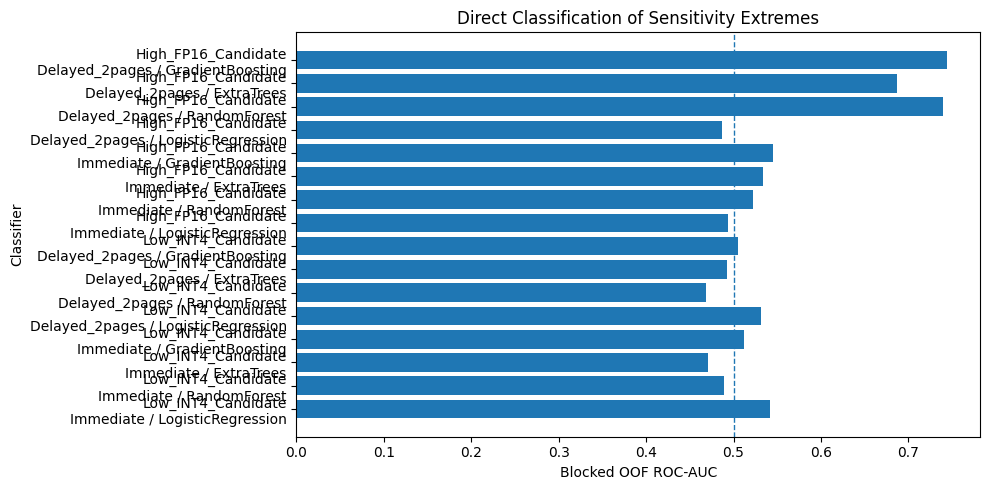


Best classifier score preview
-----------------------------


,Page,Delta_NLL,High_FP16_Candidate_Score,Low_INT4_Candidate_Score
0,6,0.306892,0.606893,0.274326
1,7,0.155956,0.157745,0.163071
2,8,0.179487,0.142098,0.281913
3,9,0.553010,0.520003,0.283919
4,10,0.486313,0.439428,0.192641
5,11,0.326217,0.548141,0.118382
6,12,1.682524,0.893060,0.470766
7,13,0.248027,0.468507,0.383999
8,14,0.237502,0.521942,0.373335
9,15,0.222520,0.208396,0.571520



Cell 13 complete.
Direct low/high sensitivity classifiers have been evaluated using blocked out-of-fold predictions.


In [17]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 13: Direct Low/High Sensitivity Classification
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
)


# ------------------------------------------------------------
# 1. Representative oracle classification thresholds
#
# Exploratory only -- NOT final precision thresholds.
# ------------------------------------------------------------

LOW_CLASS_THRESHOLD = 0.15
HIGH_CLASS_THRESHOLD = 0.30


hybrid_df["Is_Low_Sensitivity"] = (
    hybrid_df["Delta_NLL"]
    <= LOW_CLASS_THRESHOLD
).astype(int)

hybrid_df["Is_High_Sensitivity"] = (
    hybrid_df["Delta_NLL"]
    >= HIGH_CLASS_THRESHOLD
).astype(int)


print("Direct classification targets")
print("-----------------------------")

print(
    f"Low sensitivity  <= {LOW_CLASS_THRESHOLD}: "
    f"{hybrid_df['Is_Low_Sensitivity'].sum()} pages"
)

print(
    f"High sensitivity >= {HIGH_CLASS_THRESHOLD}: "
    f"{hybrid_df['Is_High_Sensitivity'].sum()} pages"
)


# ------------------------------------------------------------
# 2. Feature sets
#
# Reuse the same Immediate and Delayed-2-page sets
# from Cell 11.
# ------------------------------------------------------------

CLASSIFICATION_FEATURE_SETS = {
    "Immediate": IMMEDIATE_FEATURES,
    "Delayed_2pages": DELAYED_FEATURES,
}


# ------------------------------------------------------------
# 3. Classifiers
# ------------------------------------------------------------

CLASSIFIERS = {

    "LogisticRegression": Pipeline([
        (
            "scale",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                C=0.5,
                class_weight="balanced",
                max_iter=2000,
                random_state=SEED,
            )
        ),
    ]),

    # Bagging
    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        max_depth=3,
        min_samples_leaf=5,
        max_features=0.7,
        class_weight="balanced_subsample",
        random_state=SEED,
        n_jobs=-1,
    ),

    # Randomized bagging
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=300,
        max_depth=3,
        min_samples_leaf=5,
        max_features=0.7,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1,
    ),

    # Boosting
    "GradientBoosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=5,
        loss="log_loss",
        random_state=SEED,
    ),
}


# ------------------------------------------------------------
# 4. Tasks
# ------------------------------------------------------------

CLASSIFICATION_TASKS = {

    "Low_INT4_Candidate":
        "Is_Low_Sensitivity",

    "High_FP16_Candidate":
        "Is_High_Sensitivity",
}


# ------------------------------------------------------------
# Helper: balanced sample weights for Gradient Boosting
# ------------------------------------------------------------

def balanced_sample_weights(y):

    y = np.asarray(y)

    n = len(y)

    n0 = np.sum(y == 0)
    n1 = np.sum(y == 1)

    weights = np.ones(
        n,
        dtype=float
    )

    if n0 > 0:
        weights[y == 0] = (
            n / (2.0 * n0)
        )

    if n1 > 0:
        weights[y == 1] = (
            n / (2.0 * n1)
        )

    return weights


# ------------------------------------------------------------
# 5. Blocked out-of-fold classification
# ------------------------------------------------------------

classification_rows = []

classification_oof = {}


for task_name, target_column in CLASSIFICATION_TASKS.items():

    y = hybrid_df[
        target_column
    ].to_numpy(dtype=int)


    print(
        f"\nTask: {task_name}"
    )

    print(
        f"Positive pages: {y.sum()} / {len(y)}"
    )


    for feature_set_name, feature_names in (
        CLASSIFICATION_FEATURE_SETS.items()
    ):

        X = hybrid_df[
            feature_names
        ].to_numpy(dtype=float)

        assert np.isfinite(X).all()


        for classifier_name, classifier_template in (
            CLASSIFIERS.items()
        ):

            oof_prob = np.full(
                len(y),
                np.nan,
                dtype=float
            )


            # --------------------------------------------
            # Same contiguous folds as Cell 11
            # --------------------------------------------

            for test_idx in blocked_folds:

                train_mask = np.ones(
                    len(y),
                    dtype=bool
                )

                train_mask[
                    test_idx
                ] = False

                train_idx = all_indices[
                    train_mask
                ]


                clf = clone(
                    classifier_template
                )


                # ----------------------------------------
                # Gradient Boosting does not have a
                # class_weight parameter, so supply
                # balanced sample weights explicitly.
                # ----------------------------------------

                if (
                    classifier_name
                    == "GradientBoosting"
                ):

                    train_weights = (
                        balanced_sample_weights(
                            y[train_idx]
                        )
                    )

                    clf.fit(
                        X[train_idx],
                        y[train_idx],
                        sample_weight=train_weights,
                    )

                else:

                    clf.fit(
                        X[train_idx],
                        y[train_idx],
                    )


                oof_prob[
                    test_idx
                ] = clf.predict_proba(
                    X[test_idx]
                )[:, 1]


            assert np.isfinite(
                oof_prob
            ).all()


            # --------------------------------------------
            # Ranking metrics
            # --------------------------------------------

            auc = roc_auc_score(
                y,
                oof_prob
            )

            ap = average_precision_score(
                y,
                oof_prob
            )


            # --------------------------------------------
            # Simple 0.5 classification threshold
            #
            # Diagnostic only.
            # Final policy threshold will be tuned later.
            # --------------------------------------------

            predicted_class = (
                oof_prob >= 0.5
            ).astype(int)


            precision = precision_score(
                y,
                predicted_class,
                zero_division=0,
            )

            recall = recall_score(
                y,
                predicted_class,
                zero_division=0,
            )

            f1 = f1_score(
                y,
                predicted_class,
                zero_division=0,
            )


            prevalence = float(
                y.mean()
            )


            key = (
                task_name,
                feature_set_name,
                classifier_name,
            )

            classification_oof[
                key
            ] = oof_prob


            classification_rows.append({

                "Task":
                    task_name,

                "Feature_Set":
                    feature_set_name,

                "Classifier":
                    classifier_name,

                "Num_Features":
                    len(feature_names),

                "Positive_Pages":
                    int(y.sum()),

                "Positive_Rate":
                    prevalence,

                "ROC_AUC":
                    float(auc),

                "Average_Precision":
                    float(ap),

                "AP_Over_Random":
                    float(
                        ap / prevalence
                    ),

                "Precision_at_0.5":
                    float(precision),

                "Recall_at_0.5":
                    float(recall),

                "F1_at_0.5":
                    float(f1),
            })


# ------------------------------------------------------------
# 6. Results
# ------------------------------------------------------------

classification_results_df = pd.DataFrame(
    classification_rows
)


print(
    "\nDirect classification results"
)

print(
    "-----------------------------"
)

display(
    classification_results_df
    .sort_values(
        [
            "Task",
            "ROC_AUC",
        ],
        ascending=[
            True,
            False,
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Best classifier for each task
# ------------------------------------------------------------

best_classifier_rows = (
    classification_results_df
    .sort_values(
        "ROC_AUC",
        ascending=False
    )
    .groupby(
        "Task",
        as_index=False
    )
    .first()
)


print("\nBest classifier per task")
print("------------------------")

display(best_classifier_rows)


# ------------------------------------------------------------
# 8. Compare direct classification against Cell 12
#    regression-derived classification
# ------------------------------------------------------------

print("\nComparison with Cell 12")
print("-----------------------")


for task_name in CLASSIFICATION_TASKS:

    row = best_classifier_rows[
        best_classifier_rows[
            "Task"
        ] == task_name
    ].iloc[0]


    print(
        f"{task_name}:"
    )

    print(
        f"  Best direct classifier: "
        f"{row['Feature_Set']} / "
        f"{row['Classifier']}"
    )

    print(
        f"  ROC-AUC: "
        f"{row['ROC_AUC']:.4f}"
    )

    print(
        f"  Average Precision: "
        f"{row['Average_Precision']:.4f}"
    )

    print(
        f"  AP/random: "
        f"{row['AP_Over_Random']:.2f}x"
    )


# ------------------------------------------------------------
# 9. Plot best classifiers
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))


plot_df = (
    classification_results_df
    .copy()
)

plot_df["Label"] = (
    plot_df["Task"]
    + "\n"
    + plot_df["Feature_Set"]
    + " / "
    + plot_df["Classifier"]
)


plt.barh(
    plot_df["Label"],
    plot_df["ROC_AUC"]
)

plt.axvline(
    0.5,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Blocked OOF ROC-AUC"
)

plt.ylabel(
    "Classifier"
)

plt.title(
    "Direct Classification of Sensitivity Extremes"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 10. Save best low/high OOF probability scores
# ------------------------------------------------------------

best_classification_scores = (
    hybrid_df[
        [
            "Page",
            "Delta_NLL",
        ]
    ]
    .copy()
)


for _, row in best_classifier_rows.iterrows():

    task_name = row["Task"]

    key = (
        task_name,
        row["Feature_Set"],
        row["Classifier"],
    )

    best_classification_scores[
        f"{task_name}_Score"
    ] = classification_oof[
        key
    ]


print(
    "\nBest classifier score preview"
)

print(
    "-----------------------------"
)

display(
    best_classification_scores.head(15)
)


print("\nCell 13 complete.")

print(
    "Direct low/high sensitivity classifiers have been "
    "evaluated using blocked out-of-fold predictions."
)

### Cell 13 — Direct Classification of High- and Low-Sensitivity Pages

Previous cells attempted to predict the exact oracle sensitivity:

\[
S(p)=\Delta NLL.
\]

However, the final KV-cache policy does not necessarily require an accurate numerical estimate of \(\Delta NLL\).

The practical decisions are closer to:

\[
\text{high sensitivity} \rightarrow \text{protect / consider FP16}
\]

and:

\[
\text{low sensitivity} \rightarrow \text{consider INT4}.
\]

Cell 13 therefore reformulates the problem as two direct classification tasks.

The exploratory oracle labels are:

\[
\Delta NLL \le 0.15
\]

for a **low-sensitivity / INT4-candidate** page, and:

\[
\Delta NLL \ge 0.30
\]

for a **high-sensitivity / FP16-candidate** page.

These values are analysis thresholds only and are not yet final precision-policy thresholds.

---

#### Evaluation method

The same five contiguous held-out blocks used in Cell 11 are retained.

Therefore every reported probability is an out-of-fold prediction for a page that the classifier did not see during training.

The following classifier families were evaluated:

- Logistic Regression,
- Random Forest,
- Extra Trees,
- Gradient Boosting.

Both immediate features and delayed two-page features were tested.

---

### High-sensitivity detection

The strongest result was:

\[
\boxed{
\text{Delayed 2-page features + Gradient Boosting}
}
\]

with:

\[
ROC\text{-}AUC=0.7447
\]

and:

\[
Average\ Precision=0.4798.
\]

High-sensitivity pages represent approximately:

\[
27.8\%
\]

of the current dataset.

Therefore random ranking would have expected Average Precision of approximately:

\[
0.278.
\]

The classifier achieves approximately:

\[
\frac{0.480}{0.278}
\approx1.72
\]

times the random Average-Precision baseline.

This is substantially more encouraging than the earlier full-regression results.

A Random Forest using the same delayed features obtains a very similar:

\[
ROC\text{-}AUC=0.7395.
\]

Therefore the improvement does not appear to depend entirely on a single classifier implementation.

---

### Low-sensitivity detection

The low-sensitivity task remains much harder.

The strongest low-sensitivity classifier was:

\[
\text{Immediate features + Logistic Regression}
\]

with:

\[
ROC\text{-}AUC=0.5417.
\]

Its Average Precision was:

\[
0.4235
\]

while the positive-class prevalence was approximately:

\[
0.348.
\]

This represents only a modest improvement over random ranking.

Therefore the current features do not provide strong evidence that a page is genuinely safe for aggressive INT4 quantization.

---

### Classification versus regression

The most important result is that the two sides of the problem behave differently.

For high-sensitivity detection, direct classification improves the ROC-AUC substantially compared with predicting exact \(\Delta NLL\).

This suggests that the available features may contain enough information to distinguish broadly dangerous pages even though they cannot accurately reconstruct the complete sensitivity ranking.

For low-sensitivity detection, direct classification does not provide the same improvement.

Thus:

\[
\boxed{
\text{Predicting highly sensitive pages is easier than predicting safely quantizable pages.}
}
\]

---

### Implication for the three-tier architecture

The intended architecture remains:

\[
\text{High importance} \rightarrow FP16
\]

\[
\text{Medium / uncertain} \rightarrow INT8
\]

\[
\text{Low importance} \rightarrow INT4.
\]

However, the current evidence suggests that the three decisions should not be treated symmetrically.

The predictor may be useful for identifying pages that deserve additional protection:

\[
\text{high classifier score}
\Rightarrow
\text{FP16 candidate}.
\]

In contrast, an INT4 demotion should remain conservative because the low-sensitivity classifier is currently weak.

A reasonable design principle is therefore:

\[
\boxed{
\text{When uncertain, remain at the safe default INT8.}
}
\]

The next cell studies the robustness of these results and the precision/coverage tradeoff obtained when different classifier-score thresholds are used.

#14: Robustness and selective operating-point analysis

The goal now is not to squeeze out another model.

We want to know:

1. Is the promising high-sensitivity result stable across different sequence regions?
2. At what classifier threshold can we identify high pages with useful precision?
3. Can the low classifier ever reach a sufficiently trustworthy precision for INT4?
4. How many pages would we actually act on at those thresholds?

Fold-by-fold robustness
-----------------------


,Fold,Test_Page_Start,Test_Page_End,Task,Pages,Positive_Pages,ROC_AUC,Average_Precision
0,1,6,28,High_FP16_Candidate,23,8,0.775000,0.671253
1,1,6,28,Low_INT4_Candidate,23,4,0.618421,0.433824
2,2,29,51,High_FP16_Candidate,23,5,0.811111,0.569048
3,2,29,51,Low_INT4_Candidate,23,10,0.561538,0.524184
4,3,52,74,High_FP16_Candidate,23,4,0.750000,0.338095
5,3,52,74,Low_INT4_Candidate,23,7,0.741071,0.603855
6,4,75,97,High_FP16_Candidate,23,10,0.692308,0.681493
7,4,75,97,Low_INT4_Candidate,23,7,0.660714,0.483824
8,5,98,120,High_FP16_Candidate,23,5,0.800000,0.456623
9,5,98,120,Low_INT4_Candidate,23,12,0.439394,0.521774



Fold robustness summary
-----------------------


,Task,Mean_AUC,Std_AUC,Min_AUC,Max_AUC,Mean_AP,Std_AP
0,High_FP16_Candidate,0.765684,0.047324,0.692308,0.811111,0.543303,0.146419
1,Low_INT4_Candidate,0.604228,0.113039,0.439394,0.741071,0.513492,0.062401



High-sensitivity / FP16 threshold sweep
---------------------------------------


,Score_Threshold,Selected_Pages,Coverage,Precision,Recall,F1
0,0.20,88,0.765217,0.352273,0.96875,0.516667
1,0.25,76,0.660870,0.381579,0.90625,0.537037
2,0.30,67,0.582609,0.417910,0.87500,0.565657
3,0.35,57,0.495652,0.473684,0.84375,0.606742
4,0.40,47,0.408696,0.468085,0.68750,0.556962
5,0.45,41,0.356522,0.439024,0.56250,0.493151
6,0.50,37,0.321739,0.405405,0.46875,0.434783
7,0.55,27,0.234783,0.407407,0.34375,0.372881
8,0.60,21,0.182609,0.428571,0.28125,0.339623
9,0.65,13,0.113043,0.538462,0.21875,0.311111



Low-sensitivity / INT4 threshold sweep
--------------------------------------


,Score_Threshold,Selected_Pages,Coverage,Precision,Recall,F1
0,0.20,106,0.921739,0.367925,0.975,0.534247
1,0.25,103,0.895652,0.368932,0.950,0.531469
2,0.30,88,0.765217,0.340909,0.750,0.468750
3,0.35,84,0.730435,0.333333,0.700,0.451613
4,0.40,69,0.600000,0.318841,0.550,0.403670
5,0.45,57,0.495652,0.368421,0.525,0.432990
6,0.50,45,0.391304,0.422222,0.475,0.447059
7,0.55,30,0.260870,0.400000,0.300,0.342857
8,0.60,23,0.200000,0.434783,0.250,0.317460
9,0.65,17,0.147826,0.529412,0.225,0.315789



Best selective operating points
--------------------------------
High / FP16 candidate detector:
  threshold = 0.65
  selected pages = 13
  coverage = 0.113
  precision = 0.538
  recall = 0.219

Low / INT4 candidate detector:
  threshold = 0.75
  selected pages = 6
  coverage = 0.052
  precision = 0.667
  recall = 0.100


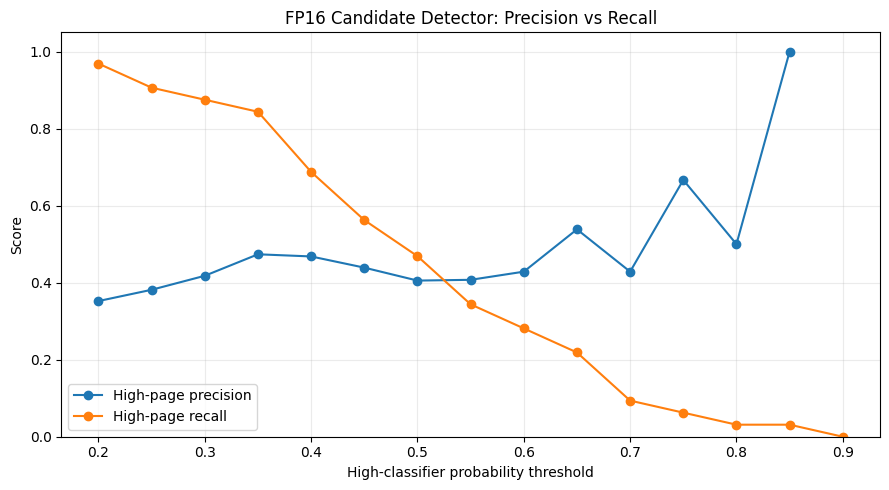

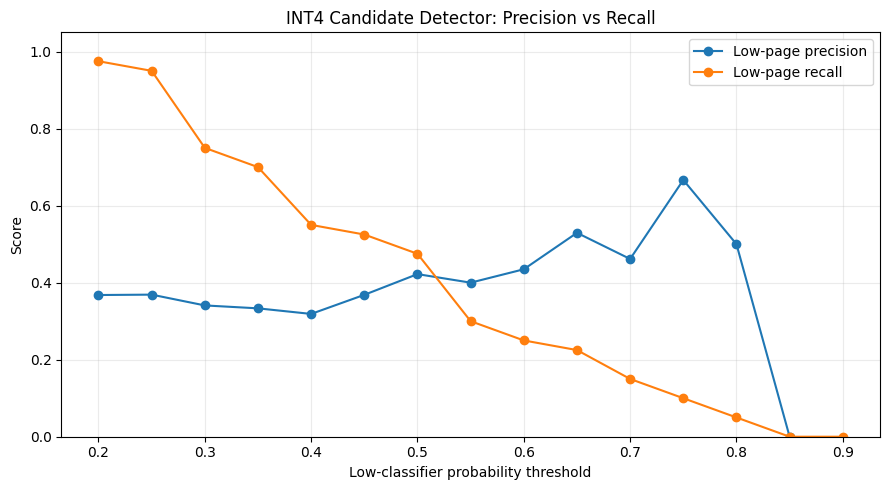

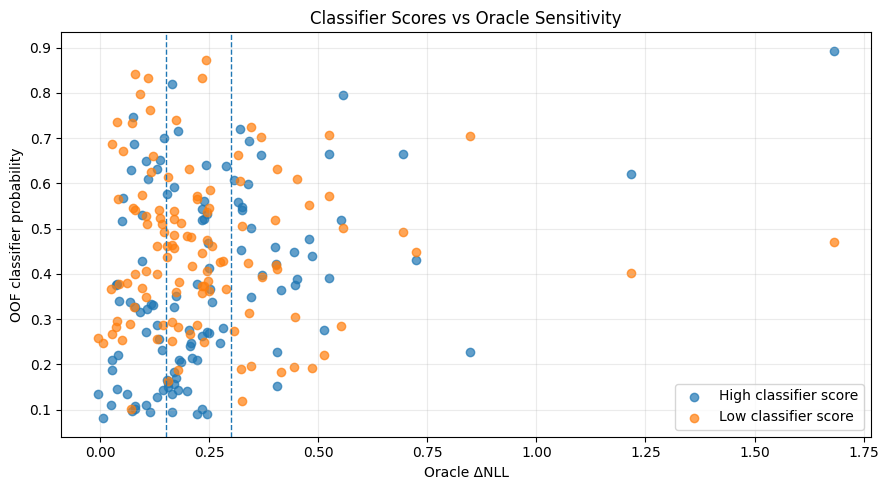


Notebook 06 predictor evidence summary
--------------------------------------
High-sensitivity detector:
  ROC-AUC = 0.7447
  AP      = 0.4798

Low-sensitivity detector:
  ROC-AUC = 0.5417
  AP      = 0.4235

Interpretation:
- High-sensitivity detection is the strongest predictive result obtained in Notebook 06.
- Low-sensitivity detection remains weak and should not yet be treated as a reliable INT4 demotion rule.
- INT8 remains the conservative default whenever the predictor is uncertain.

Cell 14 complete.


In [18]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 14: Robustness and Selective Operating-Point Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
)


# ------------------------------------------------------------
# 1. Recover best OOF classifier scores
# ------------------------------------------------------------

high_scores = (
    best_classification_scores[
        "High_FP16_Candidate_Score"
    ].to_numpy()
)

low_scores = (
    best_classification_scores[
        "Low_INT4_Candidate_Score"
    ].to_numpy()
)

oracle_delta = (
    best_classification_scores[
        "Delta_NLL"
    ].to_numpy()
)

pages = (
    best_classification_scores[
        "Page"
    ].to_numpy()
)


high_labels = (
    oracle_delta >= HIGH_CLASS_THRESHOLD
).astype(int)

low_labels = (
    oracle_delta <= LOW_CLASS_THRESHOLD
).astype(int)


assert len(high_scores) == 115
assert len(low_scores) == 115

assert np.isfinite(high_scores).all()
assert np.isfinite(low_scores).all()


# ------------------------------------------------------------
# 2. Fold-by-fold robustness
#
# Evaluate each contiguous held-out block separately.
# ------------------------------------------------------------

fold_rows = []


for fold_number, test_idx in enumerate(
    blocked_folds,
    start=1
):

    fold_pages = pages[test_idx]

    for task_name, labels, scores in [

        (
            "High_FP16_Candidate",
            high_labels,
            high_scores,
        ),

        (
            "Low_INT4_Candidate",
            low_labels,
            low_scores,
        ),
    ]:

        y = labels[test_idx]
        s = scores[test_idx]


        # AUC requires both classes to exist
        if len(np.unique(y)) == 2:

            auc = roc_auc_score(
                y,
                s
            )

            ap = average_precision_score(
                y,
                s
            )

        else:

            auc = np.nan
            ap = np.nan


        fold_rows.append({

            "Fold":
                fold_number,

            "Test_Page_Start":
                int(fold_pages.min()),

            "Test_Page_End":
                int(fold_pages.max()),

            "Task":
                task_name,

            "Pages":
                len(test_idx),

            "Positive_Pages":
                int(y.sum()),

            "ROC_AUC":
                float(auc)
                if np.isfinite(auc)
                else np.nan,

            "Average_Precision":
                float(ap)
                if np.isfinite(ap)
                else np.nan,
        })


fold_performance_df = pd.DataFrame(
    fold_rows
)


print("Fold-by-fold robustness")
print("-----------------------")

display(fold_performance_df)


# ------------------------------------------------------------
# 3. Summary across folds
# ------------------------------------------------------------

fold_summary_df = (
    fold_performance_df
    .groupby("Task")
    .agg(
        Mean_AUC=("ROC_AUC", "mean"),
        Std_AUC=("ROC_AUC", "std"),
        Min_AUC=("ROC_AUC", "min"),
        Max_AUC=("ROC_AUC", "max"),

        Mean_AP=("Average_Precision", "mean"),
        Std_AP=("Average_Precision", "std"),
    )
    .reset_index()
)


print("\nFold robustness summary")
print("-----------------------")

display(fold_summary_df)


# ------------------------------------------------------------
# 4. Threshold sweep helper
# ------------------------------------------------------------

def threshold_sweep(
    labels,
    scores,
    thresholds
):

    rows = []

    labels = np.asarray(labels)
    scores = np.asarray(scores)


    for threshold in thresholds:

        pred = (
            scores >= threshold
        ).astype(int)

        selected = int(
            pred.sum()
        )

        coverage = (
            selected / len(pred)
        )


        if selected > 0:

            precision = precision_score(
                labels,
                pred,
                zero_division=0
            )

        else:

            precision = np.nan


        recall = recall_score(
            labels,
            pred,
            zero_division=0
        )

        f1 = f1_score(
            labels,
            pred,
            zero_division=0
        )


        rows.append({

            "Score_Threshold":
                threshold,

            "Selected_Pages":
                selected,

            "Coverage":
                coverage,

            "Precision":
                precision,

            "Recall":
                recall,

            "F1":
                f1,
        })


    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 5. Sweep probability thresholds
# ------------------------------------------------------------

PROB_THRESHOLDS = np.round(
    np.arange(
        0.20,
        0.91,
        0.05
    ),
    2
)


high_threshold_df = threshold_sweep(
    high_labels,
    high_scores,
    PROB_THRESHOLDS
)

low_threshold_df = threshold_sweep(
    low_labels,
    low_scores,
    PROB_THRESHOLDS
)


print("\nHigh-sensitivity / FP16 threshold sweep")
print("---------------------------------------")

display(high_threshold_df)


print("\nLow-sensitivity / INT4 threshold sweep")
print("--------------------------------------")

display(low_threshold_df)


# ------------------------------------------------------------
# 6. Find useful selective operating points
#
# These are diagnostics, not final deployment thresholds.
# ------------------------------------------------------------

def best_precision_with_min_coverage(
    df,
    min_selected=5
):

    valid = df[
        df["Selected_Pages"]
        >= min_selected
    ].copy()

    if len(valid) == 0:
        return None

    valid = valid.sort_values(
        [
            "Precision",
            "Recall",
        ],
        ascending=False
    )

    return valid.iloc[0]


best_high_selective = (
    best_precision_with_min_coverage(
        high_threshold_df,
        min_selected=5
    )
)

best_low_selective = (
    best_precision_with_min_coverage(
        low_threshold_df,
        min_selected=5
    )
)


print("\nBest selective operating points")
print("--------------------------------")


if best_high_selective is not None:

    print("High / FP16 candidate detector:")

    print(
        f"  threshold = "
        f"{best_high_selective['Score_Threshold']:.2f}"
    )

    print(
        f"  selected pages = "
        f"{int(best_high_selective['Selected_Pages'])}"
    )

    print(
        f"  coverage = "
        f"{best_high_selective['Coverage']:.3f}"
    )

    print(
        f"  precision = "
        f"{best_high_selective['Precision']:.3f}"
    )

    print(
        f"  recall = "
        f"{best_high_selective['Recall']:.3f}"
    )


if best_low_selective is not None:

    print("\nLow / INT4 candidate detector:")

    print(
        f"  threshold = "
        f"{best_low_selective['Score_Threshold']:.2f}"
    )

    print(
        f"  selected pages = "
        f"{int(best_low_selective['Selected_Pages'])}"
    )

    print(
        f"  coverage = "
        f"{best_low_selective['Coverage']:.3f}"
    )

    print(
        f"  precision = "
        f"{best_low_selective['Precision']:.3f}"
    )

    print(
        f"  recall = "
        f"{best_low_selective['Recall']:.3f}"
    )


# ------------------------------------------------------------
# 7. Plot precision / recall versus threshold
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    high_threshold_df[
        "Score_Threshold"
    ],
    high_threshold_df[
        "Precision"
    ],
    marker="o",
    label="High-page precision"
)

plt.plot(
    high_threshold_df[
        "Score_Threshold"
    ],
    high_threshold_df[
        "Recall"
    ],
    marker="o",
    label="High-page recall"
)

plt.xlabel(
    "High-classifier probability threshold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "FP16 Candidate Detector: Precision vs Recall"
)

plt.ylim(
    0,
    1.05
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 8. INT4 precision / recall
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    low_threshold_df[
        "Score_Threshold"
    ],
    low_threshold_df[
        "Precision"
    ],
    marker="o",
    label="Low-page precision"
)

plt.plot(
    low_threshold_df[
        "Score_Threshold"
    ],
    low_threshold_df[
        "Recall"
    ],
    marker="o",
    label="Low-page recall"
)

plt.xlabel(
    "Low-classifier probability threshold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "INT4 Candidate Detector: Precision vs Recall"
)

plt.ylim(
    0,
    1.05
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 9. Visualize scores against oracle sensitivity
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.scatter(
    oracle_delta,
    high_scores,
    alpha=0.7,
    label="High classifier score"
)

plt.scatter(
    oracle_delta,
    low_scores,
    alpha=0.7,
    label="Low classifier score"
)

plt.axvline(
    HIGH_CLASS_THRESHOLD,
    linestyle="--",
    linewidth=1
)

plt.axvline(
    LOW_CLASS_THRESHOLD,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Oracle ΔNLL"
)

plt.ylabel(
    "OOF classifier probability"
)

plt.title(
    "Classifier Scores vs Oracle Sensitivity"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 10. Final evidence summary
# ------------------------------------------------------------

overall_high_auc = roc_auc_score(
    high_labels,
    high_scores
)

overall_high_ap = average_precision_score(
    high_labels,
    high_scores
)

overall_low_auc = roc_auc_score(
    low_labels,
    low_scores
)

overall_low_ap = average_precision_score(
    low_labels,
    low_scores
)


print("\nNotebook 06 predictor evidence summary")
print("--------------------------------------")

print(
    f"High-sensitivity detector:"
    f"\n  ROC-AUC = {overall_high_auc:.4f}"
    f"\n  AP      = {overall_high_ap:.4f}"
)

print(
    f"\nLow-sensitivity detector:"
    f"\n  ROC-AUC = {overall_low_auc:.4f}"
    f"\n  AP      = {overall_low_ap:.4f}"
)

print(
    "\nInterpretation:"
)

print(
    "- High-sensitivity detection is the strongest "
    "predictive result obtained in Notebook 06."
)

print(
    "- Low-sensitivity detection remains weak and "
    "should not yet be treated as a reliable INT4 "
    "demotion rule."
)

print(
    "- INT8 remains the conservative default whenever "
    "the predictor is uncertain."
)

print("\nCell 14 complete.")

### Cell 14 — Robustness and Selective Operating-Point Analysis

Cell 14 evaluates whether the classification results from Cell 13 are robust across different parts of the sequence and studies how classifier probability thresholds affect the precision/coverage tradeoff.

The two prediction tasks are:

\[
\Delta NLL \ge 0.30
\]

for **high-sensitivity / FP16-candidate** pages, and:

\[
\Delta NLL \le 0.15
\]

for **low-sensitivity / INT4-candidate** pages.

The high-sensitivity detector uses the best configuration found in Cell 13:

\[
\text{Delayed 2-page features + Gradient Boosting}.
\]

The low-sensitivity detector uses:

\[
\text{Immediate features + Logistic Regression}.
\]

---

### Fold-by-fold robustness

The 115 candidate pages were divided into five contiguous held-out regions.

For the high-sensitivity detector, ROC-AUC across the five folds was approximately:

\[
0.775,\ 0.811,\ 0.750,\ 0.692,\ 0.800.
\]

The summary is:

\[
\text{Mean AUC}=0.7657
\]

\[
\text{Std AUC}=0.0473
\]

with a range of:

\[
0.6923 \rightarrow 0.8111.
\]

This is encouraging because the detector performs above random in every sequence region rather than obtaining its overall result from only one unusually easy fold.

Therefore the high-sensitivity classification signal appears substantially more stable than the previous regression results.

---

### Low-sensitivity robustness

The low-sensitivity detector is much less stable.

Its fold-level ROC-AUC ranges from:

\[
0.4394 \rightarrow 0.7411
\]

with:

\[
\text{Mean AUC}=0.6042
\]

and:

\[
\text{Std AUC}=0.1130.
\]

One fold performs below random:

\[
AUC=0.4394.
\]

This large variation supports the conclusion that the current low-sensitivity classifier is not yet reliable enough to determine INT4 demotions.

---

### High-sensitivity threshold sweep

The classifier outputs a probability-like score rather than an immediate FP16/INT8 decision.

Increasing the decision threshold makes the detector more selective.

For example:

| Threshold | Selected pages | Precision | Recall |
|---|---:|---:|---:|
| 0.30 | 67 | 0.418 | 0.875 |
| 0.35 | 57 | 0.474 | 0.844 |
| 0.50 | 37 | 0.405 | 0.469 |
| 0.65 | 13 | 0.538 | 0.219 |
| 0.75 | 3 | 0.667 | 0.063 |

This demonstrates the expected precision/coverage tradeoff.

A low threshold protects most genuinely sensitive pages but also promotes many unnecessary pages.

A high threshold acts on fewer pages and can improve precision, but misses many sensitive pages.

The automatically selected diagnostic operating point with at least five selected pages was:

\[
T_{\text{high-score}}=0.65
\]

which selected:

\[
13
\]

pages with:

\[
\text{precision}=0.538
\]

and:

\[
\text{recall}=0.219.
\]

This is not yet proposed as the final FP16 threshold. It simply demonstrates that the classifier score can be used to trade protection coverage against additional memory cost.

---

### Low-sensitivity threshold sweep

The same analysis was performed for potential INT4 candidates.

The most selective diagnostic point with at least five selected pages was:

\[
T_{\text{low-score}}=0.75.
\]

It selected only:

\[
6
\]

pages with:

\[
\text{precision}=0.667
\]

but recall was only:

\[
0.10.
\]

Because the overall low-sensitivity ROC-AUC is weak and fold performance is unstable, this apparently high precision should be interpreted cautiously.

The current experiment does not provide enough evidence to use this classifier as a reliable INT4 demotion rule.

---

### Final predictive evidence from Notebook 06

The strongest results are:

#### High-sensitivity detector

\[
ROC\text{-}AUC=0.7447
\]

\[
Average\ Precision=0.4798
\]

with relatively stable performance across the five contiguous sequence regions.

#### Low-sensitivity detector

\[
ROC\text{-}AUC=0.5417
\]

\[
Average\ Precision=0.4235.
\]

The high-sensitivity result is therefore substantially stronger.

---

### Architectural implication

The evidence suggests that the three precision decisions should not currently be symmetric.

A reasonable conservative architecture is:

\[
\text{strong evidence of high sensitivity}
\rightarrow FP16
\]

\[
\text{uncertain page}
\rightarrow INT8
\]

while:

\[
\text{INT4 demotion}
\]

requires stronger evidence than the current low-sensitivity classifier provides.

Thus:

\[
\boxed{
INT8\text{ remains the conservative default precision.}
}
\]

The strongest contribution of Notebook 06 is therefore not a complete final three-tier controller.

Instead, it shows that inference-time signals can identify **high-sensitivity pages** with moderate predictive power, while identifying pages that are safely quantizable to INT4 remains substantially harder.

---

### Important timing caveat

The strongest high-sensitivity detector uses attention observed during the next two pages:

\[
32\text{ future tokens}.
\]

Therefore its decision is made later than the Notebook 5 sensitivity oracle, which measures INT4 demotion immediately after a page completes.

The delayed features are causal at their actual decision time, but the predictor and oracle are not perfectly aligned temporally.

Before using the delayed classifier as a final precision policy, a future experiment should recompute sensitivity with the same delayed decision point.

This motivates a delay-aligned oracle in the next stage of the project.

#15: Save and export Notebook 06

In [19]:
# ============================================================
# Notebook 06 — Inference-Time Page-Importance Prediction
# Cell 15: Save / Export All Results
# ============================================================

import os
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

NB6_RESULTS_DIR = Path("notebook06_results")

NB6_RESULTS_DIR.mkdir(
    exist_ok=True
)


# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------

def save_csv(df, filename):

    path = (
        NB6_RESULTS_DIR
        / filename
    )

    df.to_csv(
        path,
        index=False
    )

    print(
        f"Saved: {filename}"
    )


# ------------------------------------------------------------
# 1. Raw causal features
# ------------------------------------------------------------

save_csv(
    attention_features_df,
    "attention_features.csv"
)

save_csv(
    confidence_features_df,
    "confidence_features.csv"
)

save_csv(
    analysis_df,
    "combined_page_features_and_oracle.csv"
)


# ------------------------------------------------------------
# 2. Full page-attention matrices
# ------------------------------------------------------------

np.save(
    NB6_RESULTS_DIR
    / "page_attention_mean_matrix.npy",

    page_attention_mean_matrix
)

np.save(
    NB6_RESULTS_DIR
    / "page_attention_last_matrix.npy",

    page_attention_last_matrix
)

print(
    "Saved: page_attention_mean_matrix.npy"
)

print(
    "Saved: page_attention_last_matrix.npy"
)


# ------------------------------------------------------------
# 3. Individual-signal results
# ------------------------------------------------------------

save_csv(
    attention_correlation_df,
    "attention_correlations.csv"
)

save_csv(
    confidence_correlation_df,
    "confidence_correlations.csv"
)

save_csv(
    position_correlation_df,
    "position_correlations.csv"
)

save_csv(
    position_region_summary,
    "position_region_summary.csv"
)


# ------------------------------------------------------------
# 4. Delayed-attention results
# ------------------------------------------------------------

save_csv(
    delayed_correlation_df,
    "delayed_attention_correlations.csv"
)

delayed_all_df = pd.concat(
    delayed_feature_frames,
    ignore_index=True
)

save_csv(
    delayed_all_df,
    "delayed_attention_features.csv"
)


# ------------------------------------------------------------
# 5. Regression / hybrid results
# ------------------------------------------------------------

save_csv(
    hybrid_results_df,
    "hybrid_regression_results.csv"
)

save_csv(
    hybrid_prediction_df,
    "hybrid_regression_oof_predictions.csv"
)


# ------------------------------------------------------------
# 6. Threshold-oriented regression evaluation
# ------------------------------------------------------------

save_csv(
    threshold_eval_df,
    "threshold_oriented_evaluation.csv"
)

save_csv(
    diagnostic_df,
    "representative_oracle_tiers.csv"
)


# ------------------------------------------------------------
# 7. Direct classification results
# ------------------------------------------------------------

save_csv(
    classification_results_df,
    "direct_classification_results.csv"
)

save_csv(
    best_classification_scores,
    "best_classifier_oof_scores.csv"
)


# ------------------------------------------------------------
# 8. Robustness results
# ------------------------------------------------------------

save_csv(
    fold_performance_df,
    "classifier_fold_robustness.csv"
)

save_csv(
    fold_summary_df,
    "classifier_fold_summary.csv"
)

save_csv(
    high_threshold_df,
    "high_fp16_threshold_sweep.csv"
)

save_csv(
    low_threshold_df,
    "low_int4_threshold_sweep.csv"
)


# ------------------------------------------------------------
# 9. Compact Notebook 06 summary
# ------------------------------------------------------------

nb6_summary = {

    "notebook":
        "Notebook 06 - Inference-Time Page-Importance Prediction",

    "model":
        MODEL_NAME,

    "dataset":
        "WikiText-2 test",

    "cache_tokens":
        int(CACHE_TOKENS),

    "page_size":
        int(PAGE_SIZE),

    "logical_pages":
        int(NUM_PAGES),

    "candidate_page_start":
        int(CANDIDATE_PAGE_START),

    "candidate_page_end":
        int(CANDIDATE_PAGE_END),

    "candidate_pages":
        int(len(CANDIDATE_PAGES)),

    "oracle_target":
        "fixed-horizon Delta_NLL (INT4 - INT8)",

    "oracle_horizon_tokens":
        int(SENSITIVITY_HORIZON),

    "attention_analysis_dtype":
        "FP32",

    "attention_dtype_reason":
        (
            "FP16 eager output_attentions produced "
            "non-finite attention/logits; FP32 eager "
            "attention was numerically stable."
        ),

    # --------------------------------------------------------
    # Individual predictors
    # --------------------------------------------------------

    "best_immediate_attention_feature":
        str(best_feature),

    "best_immediate_attention_spearman":
        float(best_rho),

    "best_confidence_feature":
        str(best_conf_feature),

    "best_confidence_spearman":
        float(best_conf_rho),

    "page_position_spearman":
        float(page_rho),

    "best_delayed_attention_feature":
        str(best_delayed_feature),

    "best_delayed_attention_delay_pages":
        int(best_delay),

    "best_delayed_attention_delay_tokens":
        int(best_delay_tokens),

    "best_delayed_attention_spearman":
        float(best_delayed_rho),

    # --------------------------------------------------------
    # Hybrid regression
    # --------------------------------------------------------

    "best_hybrid_feature_set":
        str(best_hybrid_feature_set),

    "best_hybrid_model":
        str(best_hybrid_model),

    "best_hybrid_oof_spearman":
        float(best_hybrid_rho),

    # --------------------------------------------------------
    # Classification
    # --------------------------------------------------------

    "low_class_oracle_threshold":
        float(LOW_CLASS_THRESHOLD),

    "high_class_oracle_threshold":
        float(HIGH_CLASS_THRESHOLD),

    "best_high_classifier":
        (
            "Delayed_2pages / GradientBoosting"
        ),

    "high_classifier_oof_auc":
        float(overall_high_auc),

    "high_classifier_oof_ap":
        float(overall_high_ap),

    "high_classifier_mean_fold_auc":
        float(
            fold_summary_df.loc[
                fold_summary_df["Task"]
                == "High_FP16_Candidate",
                "Mean_AUC"
            ].iloc[0]
        ),

    "high_classifier_std_fold_auc":
        float(
            fold_summary_df.loc[
                fold_summary_df["Task"]
                == "High_FP16_Candidate",
                "Std_AUC"
            ].iloc[0]
        ),

    "best_low_classifier":
        (
            "Immediate / LogisticRegression"
        ),

    "low_classifier_oof_auc":
        float(overall_low_auc),

    "low_classifier_oof_ap":
        float(overall_low_ap),

    # --------------------------------------------------------
    # Architecture
    # --------------------------------------------------------

    "target_precision_architecture": {

        "high_importance":
            "FP16",

        "default":
            "INT8",

        "low_importance":
            [
                "INT4 per-page",
                "INT4 per-vector",
                "KVQuant-inspired K/V-aware INT4"
            ],
    },

    "current_conclusion": (
        "High-sensitivity pages can be identified with "
        "moderate predictive power, while reliable "
        "low-sensitivity / INT4-safe page detection "
        "remains unresolved. INT8 should remain the "
        "conservative default."
    ),

    "important_caveat": (
        "The strongest high-sensitivity classifier uses "
        "two pages (32 tokens) of delayed attention, "
        "while the Notebook 05 oracle assumes immediate "
        "post-page demotion. A delay-aligned sensitivity "
        "oracle should be evaluated before adopting this "
        "classifier as a final policy."
    ),

    "recommended_next_stage": (
        "Create a delay-aligned sensitivity oracle, "
        "evaluate the delayed high-sensitivity classifier "
        "against it, and then test actual FP16/INT8/INT4 "
        "adaptive cache policies and memory-quality tradeoffs."
    ),
}


summary_path = (
    NB6_RESULTS_DIR
    / "notebook06_summary.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        nb6_summary,
        f,
        indent=2
    )


print(
    "Saved: notebook06_summary.json"
)


# ------------------------------------------------------------
# 10. Human-readable summary
# ------------------------------------------------------------

summary_text = f"""
Notebook 06 — Inference-Time Page-Importance Prediction
========================================================

Model
-----
{MODEL_NAME}

Dataset
-------
WikiText-2 test sequence

Cache configuration
-------------------
Cache tokens: {CACHE_TOKENS}
Page size: {PAGE_SIZE}
Logical pages: {NUM_PAGES}
Candidate pages: {CANDIDATE_PAGE_START}-{CANDIDATE_PAGE_END}

Oracle
------
Target:
Delta NLL = NLL_INT4 - NLL_INT8

Fixed future horizon:
{SENSITIVITY_HORIZON} tokens


INDIVIDUAL SIGNALS
==================

Immediate attention
-------------------
Best feature:
{best_feature}

Spearman rho:
{best_rho:.6f}


Confidence
----------
Best feature:
{best_conf_feature}

Spearman rho:
{best_conf_rho:.6f}


Page position
-------------
Spearman rho:
{page_rho:.6f}


Delayed attention
-----------------
Best feature:
{best_delayed_feature}

Observation delay:
{best_delay} pages
({best_delay_tokens} tokens)

Spearman rho:
{best_delayed_rho:.6f}


HYBRID REGRESSION
=================

Best feature set:
{best_hybrid_feature_set}

Best model:
{best_hybrid_model}

Blocked OOF Spearman rho:
{best_hybrid_rho:.6f}


DIRECT CLASSIFICATION
=====================

High-sensitivity definition:
Delta NLL >= {HIGH_CLASS_THRESHOLD}

Best high classifier:
Delayed_2pages / GradientBoosting

Overall OOF ROC-AUC:
{overall_high_auc:.6f}

Overall OOF Average Precision:
{overall_high_ap:.6f}


Low-sensitivity definition:
Delta NLL <= {LOW_CLASS_THRESHOLD}

Best low classifier:
Immediate / LogisticRegression

Overall OOF ROC-AUC:
{overall_low_auc:.6f}

Overall OOF Average Precision:
{overall_low_ap:.6f}


MAIN CONCLUSION
===============

The strongest predictive result in Notebook 06 is direct
classification of high-sensitivity pages.

High-sensitivity detection is moderately successful and is
reasonably stable across contiguous sequence regions.

Reliable identification of low-sensitivity pages remains
unsolved. The current low classifier is too weak and unstable
to serve as a trusted INT4 demotion rule.

Therefore the current conservative architecture is:

    high-confidence sensitive page -> FP16 candidate
    uncertain / normal page        -> INT8
    low page                        -> INT4 only when stronger
                                       evidence is available

INT8 remains the safe default.


IMPORTANT CAVEAT
================

The strongest high classifier observes attention for two
additional pages (32 tokens).

Notebook 05's sensitivity oracle assumes that the target page
is demoted immediately after completion.

Therefore a delay-aligned sensitivity oracle should be built
before this delayed predictor is treated as a final adaptive
policy.


NEXT STAGE
==========

1. Build a delay-aligned sensitivity oracle.
2. Re-evaluate delayed high-sensitivity prediction.
3. Define conservative FP16 / INT8 / INT4 decision thresholds.
4. Run actual cache-aware adaptive-policy PPL evaluation.
5. Measure memory-quality tradeoffs.
6. Compare against uniform INT8, oracle, recency, and random.
"""


text_summary_path = (
    NB6_RESULTS_DIR
    / "README_notebook06.txt"
)

with open(
    text_summary_path,
    "w"
) as f:

    f.write(
        summary_text.strip()
    )


print(
    "Saved: README_notebook06.txt"
)


# ------------------------------------------------------------
# 11. Show summary
# ------------------------------------------------------------

print(
    "\n"
    + summary_text
)


# ------------------------------------------------------------
# 12. Create ZIP
# ------------------------------------------------------------

zip_path = shutil.make_archive(
    "notebook06_results",
    "zip",
    root_dir=NB6_RESULTS_DIR
)


print(
    "\nExport complete"
)

print(
    "---------------"
)

print(
    f"Results directory: "
    f"{NB6_RESULTS_DIR.resolve()}"
)

print(
    f"ZIP archive:       "
    f"{zip_path}"
)


# ------------------------------------------------------------
# 13. Download in Colab
# ------------------------------------------------------------

try:

    from google.colab import files

    files.download(
        zip_path
    )

except ImportError:

    print(
        "Not running in Colab; "
        "ZIP created locally."
    )


print(
    "\nCell 15 complete."
)

print(
    "Notebook 06 is complete."
)

Saved: attention_features.csv
Saved: confidence_features.csv
Saved: combined_page_features_and_oracle.csv
Saved: page_attention_mean_matrix.npy
Saved: page_attention_last_matrix.npy
Saved: attention_correlations.csv
Saved: confidence_correlations.csv
Saved: position_correlations.csv
Saved: position_region_summary.csv
Saved: delayed_attention_correlations.csv
Saved: delayed_attention_features.csv
Saved: hybrid_regression_results.csv
Saved: hybrid_regression_oof_predictions.csv
Saved: threshold_oriented_evaluation.csv
Saved: representative_oracle_tiers.csv
Saved: direct_classification_results.csv
Saved: best_classifier_oof_scores.csv
Saved: classifier_fold_robustness.csv
Saved: classifier_fold_summary.csv
Saved: high_fp16_threshold_sweep.csv
Saved: low_int4_threshold_sweep.csv
Saved: notebook06_summary.json
Saved: README_notebook06.txt


Notebook 06 — Inference-Time Page-Importance Prediction

Model
-----
Qwen/Qwen2.5-1.5B

Dataset
-------
WikiText-2 test sequence

Cache configuration
--

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Cell 15 complete.
Notebook 06 is complete.
